<a href="https://colab.research.google.com/github/ropaniagnes72-jpg/KinesisIQ-affordable-Housing-in-Early_Waring/blob/main/pod3_kinesis_final_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pod 3 — Kinesis
## Affordable Housing Stock Depletion & Developer Responsiveness

This notebook looks at two related questions using City of Toronto Open Data.

- **Project 2:** How much affordable rental housing is being lost, replaced and protected, and what could the net flow look like over the next five years?
- **Project 6:** How long does it take to move from development application to permit and completion, and how many housing applications may come next?

The data are cleaned and linked to the 25 wards and 158 neighbourhoods where the source data allow it. Results are compared with simple baselines and checked using time-based back-testing.

### Sections

| Section | Content |
|---|---|
| 0 | Setup and data helpers |
| A | Ward, neighbourhood and database tables |
| B1–B6 | Affordable housing analysis and forecast |
| C1–C5 | Development applications, permits, lags, models and maps |
| D | Data-quality checks |
| E | Ward grouping |
| F | Findings, limitations and exports |

The notebook uses the source data as provided. Records that cannot be reliably assigned a date or ward are flagged or left unmapped rather than given an invented value.


## 0. Setup and Configuration
Libraries, settings and every modelling assumption are defined in the next cell.

In [1]:
# Optional, in Colab run once and restart the runtime:  !pip -q install geopandas pyproj
import os, re, json, sqlite3, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

try:
    import geopandas as gpd
    HAS_GPD = True
except ImportError:
    HAS_GPD = False
    print("geopandas not installed. In Colab run:  !pip install geopandas  and restart the runtime.\n"
          "Without it, ward assignment falls back to explicit ward fields only and permits stay unmapped.")
try:
    from pyproj import Transformer
    HAS_PYPROJ = True
except ImportError:
    HAS_PYPROJ = False
    print("pyproj not installed (pip install pyproj): projected X/Y coordinates cannot be converted.")

# Settings
CKAN = "https://ckan0.cf.opendata.inter.prod-toronto.ca"
SEED = 42
AS_OF = pd.Timestamp.today().normalize()      # freeze a run with e.g. pd.Timestamp("2026-11-14")
PANEL_START_YEAR = 2017                        # first year of ward-year panels (demolition data starts 2017)
ANALYSIS_START = pd.Timestamp("2017-01-01")    # permits issued / applications submitted from this date

# RentSafeTO
RS_RED_BELOW = 70            # score below 70 = red band (green 85-100, yellow 70-84, red 0-69)
RS_DROP_POINTS = 5           # a score drop of 5+ points between evaluations = "degrading"
RS_AUDIT_PERCENTILE = 0.025  # City prioritises the lowest 2.5% of scores each year for audit

# Affordable pipeline assumptions. These are planning assumptions because the pipeline file has no delivery history.
PIPELINE_ASSUMPTIONS = {
    "completed":          (0.00, 1, 1),   # already built: part of existing stock, not future supply
    "under_construction": (0.95, 1, 3),
    "approved":           (0.70, 2, 5),
    "planning":           (0.40, 3, 7),
    "other":              (0.40, 3, 7),
}
PIPELINE_SCENARIOS = {"low (x0.5)": 0.5, "base (x1.0)": 1.0, "high (x1.25)": 1.25}
STRESS_DEGRADATION_LOSS_RATE = 0.01    # share of at-risk RentSafeTO units used in the stress scenario

FORECAST_YEARS = 5
SIMS = 5000
MIN_TRAIN_YEARS = 3                     # first back-test origin needs at least this many training years

# Permit checks
MAX_UNITS_PER_PERMIT = 5000             # a single permit above this is treated as a data-entry error
MIN_COST_PER_UNIT = 10_000              # permits with 500+ units but less than this cost per unit are treated as errors
MAX_LAG_DAYS = 3650                     # lags longer than 10 years are treated as date errors
GRID_MIN_N, GRID_MIN_PURITY = 20, 0.90  # WARD_GRID lookup: minimum rows and share agreeing on one ward
USE_ADDRESS_BRIDGE = True

# Policy dates used as descriptive flags in the application-volume model
POLICY_EVENTS = {
    "COVID-19 emergency (Ontario)":        "2020-03-17",
    "Bank of Canada first rate rise":      "2022-03-02",
    "Bill 23 royal assent (Ontario)":      "2022-11-28",
}

FIG_DIR = "figures"; OUT_DIR = "outputs"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)

# ---- database location (only use Drive if it is really mounted) ----
DRIVE_DB = "/content/drive/MyDrive/pod3-kinesis/data/processed/kinesis.db"
if os.path.ismount("/content/drive"):
    os.makedirs(os.path.dirname(DRIVE_DB), exist_ok=True)
    db_path = DRIVE_DB
else:
    db_path = "kinesis.db"
    print("Google Drive is not mounted -> using local database:", db_path)
print("Analysis date (AS_OF):", AS_OF.date())

def connect():
    return sqlite3.connect(db_path)

DQ = []         # data-quality log, summarised in Section D
GEO_LOG = []    # spatial-vs-source ward agreement, summarised in Section D


Google Drive is not mounted -> using local database: kinesis.db
Analysis date (AS_OF): 2026-11-15


### 0.1 Open Data Helpers
- **`load_package_tables`** reads every tabular resource in a CKAN package but keeps **one copy** of each table. Toronto often publishes the same table as a datastore resource, a `.csv` file and `4326` / `2952` projected versions; resources that differ only by file type or projection are collapsed, and the helper prints which were skipped.
- **`coalesce_columns`** merges columns whose spelling changes between files (for example `YEAR BUILT` and `YEAR_BUILT`) so values are not silently lost.

In [2]:
def ckan_get(action, **params):
    r = requests.get(f"{CKAN}/api/3/action/{action}", params=params, timeout=90)
    r.raise_for_status()
    j = r.json()
    if not j.get("success"):
        raise RuntimeError(f"CKAN {action} failed: {j}")
    return j["result"]

def find_package(slug, *search_terms):
    try:
        return ckan_get("package_show", id=slug)
    except Exception:
        pass
    for term in search_terms:
        hits = ckan_get("package_search", q=term, rows=10)["results"]
        if hits:
            print(f"   '{slug}' not found -> using closest match: '{hits[0]['name']}' ({hits[0]['title']})")
            return hits[0]
    raise LookupError(f"No CKAN package found for '{slug}' / {search_terms}")

def _base_name(name):
    n = str(name or "").lower().strip()
    n = re.sub(r"\.(csv|xlsx|xls|json|geojson)$", "", n)
    n = re.sub(r"\s*[-_]\s*(4326|2952|wgs84|mtm\w*)\s*$", "", n)
    return n.strip()

def pick_resources(pkg, name_filter=None):
    """One resource per distinct table: prefer the datastore copy, then WGS84 over projected copies."""
    cands = []
    for r in pkg["resources"]:
        if name_filter and not re.search(name_filter, r.get("name", ""), re.I):
            continue
        fmt = (r.get("format") or "").upper()
        if r.get("datastore_active"):
            src = f"{CKAN}/datastore/dump/{r['id']}"
        elif fmt == "CSV":
            src = r["url"]
        else:
            continue
        projected = 1 if re.search(r"2952|mtm", r.get("name", "") + " " + r.get("url", ""), re.I) else 0
        cands.append((_base_name(r.get("name")), projected, 0 if r.get("datastore_active") else 1, r, src))
    chosen, skipped = {}, []
    for base, proj, notds, r, src in sorted(cands, key=lambda t: (t[0], t[1], t[2])):
        if base in chosen:
            skipped.append(r.get("name"))
        else:
            chosen[base] = (r, src)
    return list(chosen.values()), skipped

def _colkey(c):
    return re.sub(r"[^a-z0-9]+", "", str(c).lower())

def coalesce_columns(df):
    """Merge columns that differ only in spelling (spaces / underscores / case), e.g. 'YEAR BUILT' and 'YEAR_BUILT'."""
    groups = {}
    for c in df.columns:
        if not str(c).startswith("_"):
            groups.setdefault(_colkey(c), []).append(c)
    merged = []
    for cols in groups.values():
        if len(cols) > 1:
            first = cols[0]
            for c in cols[1:]:
                df[first] = df[first].combine_first(df[c])
            df = df.drop(columns=cols[1:])
            merged.append(cols)
    if merged:
        print("   merged differently-spelled columns:", [" + ".join(map(str, g)) for g in merged][:8])
    return df

def load_package_tables(slug, *search_terms, name_filter=None, usecols=None, dedupe=True):
    """Load one copy of every tabular resource of a package (datastore dump or CSV) and concatenate them."""
    pkg = find_package(slug, *search_terms)
    chosen, skipped = pick_resources(pkg, name_filter)
    frames, loaded = [], []
    for i, (r, src) in enumerate(chosen):
        kw = {"low_memory": False}
        if usecols is not None:
            kw["usecols"] = usecols if callable(usecols) else (lambda c, s=set(usecols): c in s)
        try:
            df = pd.read_csv(src, **kw)
        except Exception as e:
            print(f"   skipped resource '{r.get('name')}': {type(e).__name__}: {str(e)[:100]}")
            continue
        ids = df["_id"] if "_id" in df.columns else df.index
        df["_uid"] = [f"{i}-{v}" for v in ids]
        df["_resource"] = r.get("name")
        frames.append(df)
        loaded.append(f"{r.get('name')} ({len(df):,} rows)")
    if not frames:
        raise RuntimeError(f"No loadable tabular resource in package '{pkg['name']}'")
    out = coalesce_columns(pd.concat(frames, ignore_index=True))
    n0 = len(out)
    if dedupe:
        content = [c for c in out.columns if c not in ("_id", "_uid", "_resource")]
        out = out.drop_duplicates(subset=content, keep="first").reset_index(drop=True)
    print(f"Loaded '{pkg['title']}' [{pkg['name']}]: {len(out):,} rows, {out.shape[1]} cols"
          + (f"  (removed {n0 - len(out):,} exact duplicate rows)" if n0 != len(out) else ""))
    for l in loaded:
        print("   - loaded:", l)
    for s in skipped:
        print("   - skipped duplicate copy of an already-loaded table:", s)
    return out

def load_geo(slug, *search_terms):
    """Load a GeoJSON resource (EPSG:4326 preferred) as a GeoDataFrame."""
    pkg = find_package(slug, *search_terms)
    res = [r for r in pkg["resources"] if (r.get("format") or "").upper() == "GEOJSON"]
    pref = [r for r in res if "4326" in r.get("name", "") or "4326" in r.get("url", "")]
    r = (pref or res)[0]
    g = gpd.read_file(r["url"])
    if g.crs is None:
        g = g.set_crs(4326)
    return g.to_crs(4326)

# ---------------- parsing helpers ----------------
def pick_col(df, *patterns, override=None):
    """First column matching the first matching regex (in priority order). Spaces, underscores and case are interchangeable."""
    if override:
        return override
    for p in patterns:
        for c in df.columns:
            name = str(c)
            if name.startswith("_"):
                continue
            if (re.search(p, name, re.I) or re.search(p, re.sub(r"[^A-Za-z0-9]+", "_", name), re.I)
                    or re.search(p, re.sub(r"[^A-Za-z0-9]+", " ", name), re.I)):
                return c
    return None

def detect(raw, ov, spec):
    m = {k: pick_col(raw, *pats, override=ov.get(k)) for k, pats in spec.items()}
    print("Detected columns:", m)
    return m

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[,$\s]", "", regex=True), errors="coerce")

def to_dt(s):
    if pd.api.types.is_numeric_dtype(s) and s.dropna().size and s.dropna().median() > 1e11:      # epoch milliseconds
        d = pd.to_datetime(s, unit="ms", errors="coerce")
    else:
        try:
            d = pd.to_datetime(s, errors="coerce", format="mixed")
        except (TypeError, ValueError):
            d = pd.to_datetime(s, errors="coerce")
    return d

def sane_dates(d, lo="1990-01-01", hi_years_ahead=1):
    """Dates outside [1990, AS_OF + 1 year] are data errors -> NaT (counted by the caller, never defaulted)."""
    hi = AS_OF + pd.DateOffset(years=hi_years_ahead)
    return d.where((d >= pd.Timestamp(lo)) & (d <= hi))

def disp(df, n=None, digits=2):
    d = df if n is None else df.head(n)
    try:
        display(d.round(digits))
    except NameError:
        print(d.round(digits).to_string())

show = lambda df, n=3: disp(df, n)

def finish_plot(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---------------- coordinates ----------------
def lonlat_from_geometry(s):
    """GeoJSON point strings -> (lat, lon). Several Toronto tables ship coordinates only in a `geometry` text column."""
    lon = np.full(len(s), np.nan); lat = np.full(len(s), np.nan)
    for i, v in enumerate(s.to_numpy(dtype=object)):
        if isinstance(v, str) and v[:1] == "{":
            try:
                g = json.loads(v)
            except ValueError:
                continue
            c, t = g.get("coordinates"), g.get("type")
            if t == "MultiPoint" and c:
                c = c[0]
            if t in ("Point", "MultiPoint") and c and len(c) >= 2:
                lon[i], lat[i] = c[0], c[1]
    return pd.Series(lat, index=s.index), pd.Series(lon, index=s.index)

XY_CRS_CANDIDATES = ["EPSG:2952", "EPSG:2019", "EPSG:26917"]   # Toronto MTM zone 10 variants, UTM 17N

def lonlat_from_xy(x, y):
    """Projected X/Y -> (lat, lon). The CRS is chosen by testing which candidate puts the points inside Toronto."""
    x, y = to_num(x), to_num(y)
    nan = pd.Series(np.nan, index=x.index)
    if not HAS_PYPROJ:
        print("   X/Y present but pyproj is not installed -> not converted")
        return nan, nan
    ok = x.notna() & y.notna() & (x > 0) & (y > 0)
    if not ok.any():
        return nan, nan
    samp = ok[ok].index[:5000]
    best = None
    for crs in XY_CRS_CANDIDATES:
        tr = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
        lo, la = tr.transform(x[samp].to_numpy(), y[samp].to_numpy())
        share = float(((np.asarray(la) > 43.4) & (np.asarray(la) < 44.0) & (np.asarray(lo) > -79.8) & (np.asarray(lo) < -78.9)).mean())
        if best is None or share > best[0]:
            best = (share, crs)
    if best[0] < 0.95:
        print(f"   X/Y could not be matched to a known Toronto CRS (best {best[1]}: {best[0]:.0%} inside Toronto) -> not converted")
        return nan, nan
    tr = Transformer.from_crs(best[1], "EPSG:4326", always_xy=True)
    lo, la = tr.transform(x[ok].to_numpy(), y[ok].to_numpy())
    lat, lon = nan.copy(), nan.copy()
    lat[ok], lon[ok] = la, lo
    print(f"   X/Y converted from {best[1]} ({best[0]:.0%} of sampled points fall inside Toronto)")
    return lat, lon

def add_coords(df, lat_col=None, lon_col=None, geom_col=None, x_col=None, y_col=None):
    """Adds `_lat`/`_lon` (WGS84) from the first source that works: lat/lon columns, GeoJSON geometry text, or projected X/Y."""
    lat = pd.Series(np.nan, index=df.index); lon = lat.copy(); used = []
    def fill(la, lo, label):
        nonlocal lat, lon
        good = la.between(43.4, 44.0) & lo.between(-79.8, -78.9) & lat.isna()
        if good.any():
            lat = lat.where(~good, la); lon = lon.where(~good, lo); used.append(f"{label}:{int(good.sum()):,}")
    if lat_col and lon_col:
        fill(to_num(df[lat_col]), to_num(df[lon_col]), "lat/lon")
    if geom_col and geom_col in df.columns:
        fill(*lonlat_from_geometry(df[geom_col]), "geometry")
    if x_col and y_col and x_col in df.columns and y_col in df.columns and lat.isna().any():
        fill(*lonlat_from_xy(df[x_col], df[y_col]), "X/Y")
    print("   coordinates:", ", ".join(used) if used else "none usable", f"-> {lat.notna().mean():.1%} of rows have a point")
    return df.assign(_lat=lat, _lon=lon)

## A. Reference Geography
City Wards (25-ward model, in effect since 2018) and Neighbourhoods (158 model) are the only geography used in this notebook. Ward IDs run from 1 to 25.

In [3]:
WARDS = [
    (1, "Etobicoke North"), (2, "Etobicoke Centre"), (3, "Etobicoke-Lakeshore"), (4, "Parkdale-High Park"),
    (5, "York South-Weston"), (6, "York Centre"), (7, "Humber River-Black Creek"), (8, "Eglinton-Lawrence"),
    (9, "Davenport"), (10, "Spadina-Fort York"), (11, "University-Rosedale"), (12, "Toronto-St. Paul's"),
    (13, "Toronto Centre"), (14, "Toronto-Danforth"), (15, "Don Valley West"), (16, "Don Valley East"),
    (17, "Don Valley North"), (18, "Willowdale"), (19, "Beaches-East York"), (20, "Scarborough Southwest"),
    (21, "Scarborough Centre"), (22, "Scarborough-Agincourt"), (23, "Scarborough North"),
    (24, "Scarborough-Guildwood"), (25, "Scarborough-Rouge Park"),
]
WARD_NAME = dict(WARDS)

def _norm(s):
    return re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()

WARD_NAME_TO_ID = {_norm(n): i for i, n in WARDS}

def ward_from_value(v):
    """Strict 25-ward resolver: a number 1-25 (13, '13', 'Ward 13', 'Toronto Centre (13)') or an exact ward name."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    s = str(v).strip()
    m = re.fullmatch(r"(?:ward\s*)?0*(\d{1,2})(?:\.0+)?", s, re.I) or re.search(r"\(\s*0*(\d{1,2})\s*\)", s)
    if m and 1 <= int(m.group(1)) <= 25:
        return int(m.group(1))
    return WARD_NAME_TO_ID.get(_norm(re.sub(r"\(.*?\)", "", s)))

wards_gdf = None
nbhd_gdf = None
nbhd_table = pd.DataFrame(columns=["neighbourhood_id", "neighbourhood_name"])

if HAS_GPD:
    # --- City Wards (25-ward model) ---
    try:
        g = load_geo("city-wards", "city wards")
        code_col = pick_col(g, r"^AREA_SHORT_CODE$", r"^AREA_LONG_CODE$", r"WARD.*(NUM|ID|CODE)")
        g["ward_id"] = pd.to_numeric(g[code_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
        g = g[g["ward_id"].between(1, 25)]
        assert g["ward_id"].nunique() == 25, f"expected 25 wards, found {g['ward_id'].nunique()} - is this the 25-ward model?"
        g["ward_id"] = g["ward_id"].astype(int)
        wards_gdf = g[["ward_id", "geometry"]].copy()
        name_col = pick_col(g, r"^AREA_NAME$", r"WARD.*NAME")
        if name_col:
            geo_names = {int(r.ward_id): _norm(re.sub(r"\(.*?\)", "", str(r[name_col]))) for _, r in g.iterrows()}
            bad = [i for i, n in WARDS if geo_names.get(i) != _norm(n)]
            print("Ward geometry loaded (25). Name mismatches vs dim_ward:", bad or "none")
    except Exception as e:
        print("Could not load City Wards geometry:", type(e).__name__, e)

    # --- Neighbourhoods (158 model) ---
    try:
        g = load_geo("neighbourhoods", "neighbourhoods")
        code_col = pick_col(g, r"^AREA_SHORT_CODE$", r"^AREA_LONG_CODE$", r"NEIGHBOURHOOD.*(ID|NUM|CODE)")
        name_col = pick_col(g, r"^AREA_NAME$", r"NEIGHBOURHOOD.*NAME")
        g["neighbourhood_id"] = pd.to_numeric(g[code_col].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
        g = g.dropna(subset=["neighbourhood_id"])
        g["neighbourhood_id"] = g["neighbourhood_id"].astype(int)
        g["neighbourhood_name"] = g[name_col].astype(str).str.replace(r"\s*\(\d+\)\s*$", "", regex=True)
        if g["neighbourhood_id"].nunique() != 158:
            print(f"WARNING: {g['neighbourhood_id'].nunique()} neighbourhoods found, outline expects the 158 model - check the package.")
        nbhd_gdf = g[["neighbourhood_id", "neighbourhood_name", "geometry"]].copy()
        nbhd_table = nbhd_gdf[["neighbourhood_id", "neighbourhood_name"]].drop_duplicates()
        print(f"Neighbourhood geometry loaded ({len(nbhd_table)}).")
    except Exception as e:
        print("Could not load Neighbourhood geometry:", type(e).__name__, e)

# ---- geography assignment ----
def assign_geography(df, lat_col, lon_col):
    """Point-in-polygon: adds ward_id_sp / neighbourhood_id_sp (NaN where no usable coordinates)."""
    out = df.copy()
    out["ward_id_sp"] = np.nan
    out["neighbourhood_id_sp"] = np.nan
    if not HAS_GPD or wards_gdf is None or lat_col not in out or lon_col not in out:
        return out
    lat, lon = pd.to_numeric(out[lat_col], errors="coerce"), pd.to_numeric(out[lon_col], errors="coerce")
    ok = lat.between(43.4, 44.0) & lon.between(-79.8, -78.9)          # Toronto bounding box sanity check
    if not ok.any():
        print(f"   no usable WGS84 coordinates in {lat_col}/{lon_col} - spatial join skipped")
        return out
    pts = gpd.GeoDataFrame({"_i": out.index[ok]}, geometry=gpd.points_from_xy(lon[ok], lat[ok]), crs="EPSG:4326")
    for gdf, idcol, outcol in ((wards_gdf, "ward_id", "ward_id_sp"), (nbhd_gdf, "neighbourhood_id", "neighbourhood_id_sp")):
        if gdf is None:
            continue
        j = gpd.sjoin(pts, gdf[[idcol, "geometry"]], how="left", predicate="within")
        j = j[~j.index.duplicated(keep="first")]
        out.loc[j["_i"].values, outcol] = j[idcol].values
    return out

def finalize_geo(df, ward_col=None, lat_col=None, lon_col=None, label=""):
    """Adds ward_id, neighbourhood_id, geo_method. Priority: spatial join > explicit ward field > unmapped (never guessed)."""
    out = assign_geography(df, lat_col, lon_col) if lat_col and lon_col else df.assign(ward_id_sp=np.nan, neighbourhood_id_sp=np.nan)
    src = out[ward_col].map(ward_from_value) if ward_col else pd.Series(np.nan, index=out.index)
    src = pd.to_numeric(src, errors="coerce")
    both = out["ward_id_sp"].notna() & src.notna()
    if both.any():
        agree = float((out.loc[both, "ward_id_sp"] == src[both]).mean())
        print(f"   spatial vs source-ward agreement: {agree:.1%} on {both.sum():,} rows")
        GEO_LOG.append({"dataset": label, "rows_compared": int(both.sum()), "agreement": agree})
    ward = out["ward_id_sp"].where(out["ward_id_sp"].notna(), src)
    out["geo_method"] = np.where(out["ward_id_sp"].notna(), "spatial_join",
                         np.where(src.notna(), "source_ward_field", "unmapped"))
    out["ward_id"] = pd.to_numeric(ward, errors="coerce").astype("Int64")
    out["neighbourhood_id"] = pd.to_numeric(out["neighbourhood_id_sp"], errors="coerce").astype("Int64")
    return out.drop(columns=["ward_id_sp", "neighbourhood_id_sp"])

/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 3000-01-01T00:00:00, at position 0. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Ward geometry loaded (25). Name mismatches vs dim_ward: none
Neighbourhood geometry loaded (158).


### A.1 Database Schema
`kinesis_events` keeps the 12 columns of the KinesisIQ events schema plus `units_lost` and `geo_method`. Re-running the notebook is safe: each source's rows are replaced, not appended.

In [4]:
conn = connect()
cur = conn.cursor()
cur.execute("""CREATE TABLE IF NOT EXISTS dim_ward (
    ward_id INTEGER PRIMARY KEY, ward_name VARCHAR(100) NOT NULL, ward_code VARCHAR(20) UNIQUE NOT NULL)""")
cur.execute("""CREATE TABLE IF NOT EXISTS dim_neighbourhood (
    neighbourhood_id INTEGER PRIMARY KEY, neighbourhood_name VARCHAR(150) NOT NULL)""")
cur.execute("""CREATE TABLE IF NOT EXISTS kinesis_events (
    event_id VARCHAR(60) PRIMARY KEY,
    event_type VARCHAR(50) NOT NULL,
    event_date DATE NOT NULL,
    event_year INTEGER NOT NULL,
    event_quarter INTEGER,
    ward_id INTEGER REFERENCES dim_ward(ward_id),
    neighbourhood_id INTEGER REFERENCES dim_neighbourhood(neighbourhood_id),
    address TEXT,
    units_affected INTEGER DEFAULT 0,
    units_affordable INTEGER DEFAULT 0,
    source_dataset VARCHAR(100) NOT NULL,
    data_quality_flag VARCHAR(30) DEFAULT 'clean')""")

existing = {r[1] for r in cur.execute("PRAGMA table_info(kinesis_events)")}
for col, ddl in (("units_lost", "INTEGER DEFAULT 0"), ("geo_method", "VARCHAR(30)")):
    if col not in existing:
        cur.execute(f"ALTER TABLE kinesis_events ADD COLUMN {col} {ddl}")

cur.executemany("INSERT OR REPLACE INTO dim_ward VALUES (?,?,?)", [(i, n, f"WARD_{i:02d}") for i, n in WARDS])
if len(nbhd_table):
    cur.executemany("INSERT OR REPLACE INTO dim_neighbourhood VALUES (?,?)",
                    [(int(r.neighbourhood_id), r.neighbourhood_name) for r in nbhd_table.itertuples()])
conn.commit()
conn.close()

EVENT_COLS = ["event_id", "event_type", "event_date", "event_year", "event_quarter", "ward_id", "neighbourhood_id",
              "address", "units_affected", "units_affordable", "source_dataset", "data_quality_flag",
              "units_lost", "geo_method"]

GEO_FLAG = {"spatial_join": "clean", "source_ward_field": "clean",
            "ward_grid_lookup": "ward_grid_inferred", "unmapped": "unmapped_ward"}

def make_events(df, uid_col, prefix, event_type, dates, source, address=None, units=None, affordable=None, lost=None, flag=None):
    """Standardised event rows. Rows without a real date are dropped (and counted), not given a default date."""
    d = pd.Series(dates, index=df.index)
    keep = d.notna()
    z = pd.Series(0, index=df.index)
    dq = df["geo_method"].map(GEO_FLAG)
    if flag is not None:                       # a row-level problem (e.g. outlier units) overrides the geography flag
        dq = dq.where(flag.isna(), flag)
    ev = pd.DataFrame({
        "event_id": prefix + df[uid_col].astype(str),
        "event_type": event_type,
        "event_date": d.dt.strftime("%Y-%m-%d"),
        "event_year": d.dt.year,
        "event_quarter": d.dt.quarter,
        "ward_id": df["ward_id"],
        "neighbourhood_id": df["neighbourhood_id"],
        "address": df[address].astype(str).str.strip() if address else None,
        "units_affected": (units if units is not None else z).fillna(0).astype(int),
        "units_affordable": (affordable if affordable is not None else z).fillna(0).astype(int),
        "source_dataset": source,
        "data_quality_flag": dq,
        "units_lost": (lost if lost is not None else z).fillna(0).astype(int),
        "geo_method": df["geo_method"],
    })[keep]
    return ev[EVENT_COLS]

def write_events(ev, sources):
    """Idempotent load: replace every row of the given source datasets."""
    conn = connect()
    ph = ",".join("?" * len(sources))
    conn.execute(f"DELETE FROM kinesis_events WHERE source_dataset IN ({ph})", list(sources))
    rows = ev.astype(object).where(ev.notna(), None).values.tolist()
    conn.executemany(f"INSERT OR REPLACE INTO kinesis_events ({','.join(EVENT_COLS)}) VALUES ({','.join('?' * len(EVENT_COLS))})", rows)
    conn.commit()
    conn.close()

def write_table(df, name):
    conn = connect()
    df.to_sql(name, conn, if_exists="replace", index=False)
    conn.close()

def log_dq(dataset, loaded, events, geo=None, note=""):
    unm = float((geo["geo_method"] == "unmapped").mean()) if geo is not None and len(geo) else np.nan
    DQ.append({"dataset": dataset, "rows_loaded": loaded, "events_written": events, "pct_ward_unmapped": unm, "note": note})

def by_ward(df, **aggs):
    d = df.dropna(subset=["ward_id"]).copy()
    d["ward_id"] = d["ward_id"].astype(int)
    return d.groupby("ward_id").agg(**aggs).reindex(range(1, 26))

print("Schema ready:", db_path)

Schema ready: kinesis.db


# Project 2 — Affordable Stock Depletion
**Question:** how much affordable rental housing is being lost, how much is replaced, how much is protected, how much is coming, and where is the remaining stock in poor condition?

> **Two definitions of "affordable" are used and they are not the same.**
> - *Demolition file:* existing rents below the City's affordability threshold (market-rate affordable).
> - *Pipeline file:* new homes approved at below-market rents.
>
> Totals from the two files are shown side by side and are never added together.

## B1. Demolition and Replacement of Rental Housing Units
One row per rental demolition application (about 170 since 2017). The event date is the date the demolition permit was issued; if no permit has been issued yet, the City Council approval date is used and recorded in `date_basis`. No default date is substituted.

Loaded 'Demolition and Replacement of Rental Housing Units' [demolition-and-replacement-of-rental-housing-units]: 173 rows, 22 cols  (removed 1 exact duplicate rows)
   - loaded: Rental Demolition and Replacement (174 rows)
   - skipped duplicate copy of an already-loaded table: Rental Demolition and Replacement.csv
{'dem_tot': 'Total Rental Homes for Demolition', 'dem_aff': 'Affordable Rental Homes for Demolition', 'dem_mid': 'Mid-Range Rental Homes for Demolition', 'dem_high': 'High-End Rental Homes for Demolition', 'rep_tot': 'Total Rental Homes Replaced', 'rep_aff': 'Affordable Rental Homes Replaced', 'rep_mid': 'Mid-Range Rental Homes Replaced', 'rep_high': 'High-End Rental Homes Replaced', 'permit_dt': 'Date the Rental Demolition Permit was Issued', 'council_dt': 'City Council Approval Date', 'address': 'Address of Existing Rental Building', 'ward': '(Post 2018) Ward'}

173 demolition applications. Affordable units: 4,311 slated for demolition, 4,551 to be replaced -> net +240
Wa

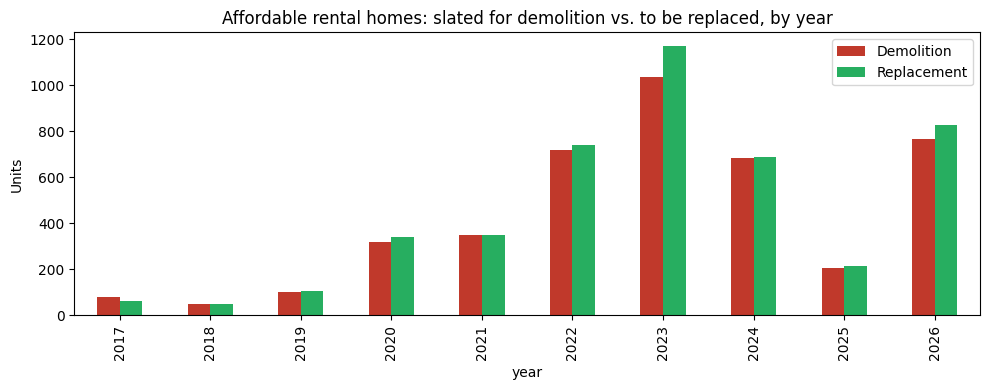

In [5]:
demo_raw = load_package_tables("demolition-and-replacement-of-rental-housing-units",
                               "demolition and replacement of rental housing units")
demo = demo_raw.copy()

c = {k: pick_col(demo, *p) for k, p in {
    "dem_tot":  [r"^Total Rental Homes for Demolition"], "dem_aff": [r"^Affordable Rental Homes for Demolition"],
    "dem_mid":  [r"^Mid-Range Rental Homes for Demolition"], "dem_high": [r"^High-End Rental Homes for Demolition"],
    "rep_tot":  [r"^Total Rental Homes Replaced"], "rep_aff": [r"^Affordable Rental Homes Replaced"],
    "rep_mid":  [r"^Mid-Range Rental Homes Replaced"], "rep_high": [r"^High-End Rental Homes Replaced"],
    "permit_dt": [r"^Date the Rental Demolition Permit"], "council_dt": [r"Council Approval Date"],
    "address": [r"^Address of Existing Rental Building"], "ward": [r"Post 2018.*Ward", r"Ward"]}.items()}
print(c)
missing = [k for k, v in c.items() if v is None]
if missing:
    print("WARNING: columns not found:", missing, "- check the package columns:", list(demo.columns)[:30])

blank_rep = int(demo[c["rep_aff"]].isna().sum()) if c["rep_aff"] else 0
for k in ["dem_tot", "dem_aff", "dem_mid", "dem_high", "rep_tot", "rep_aff", "rep_mid", "rep_high"]:
    demo[k] = to_num(demo[c[k]]).fillna(0) if c[k] else 0          # blank replacement counts are read as "none reported"
permit_dt, council_dt = sane_dates(to_dt(demo[c["permit_dt"]])), sane_dates(to_dt(demo[c["council_dt"]]))
demo["event_date"] = permit_dt.fillna(council_dt)
demo["date_basis"] = np.where(permit_dt.notna(), "permit_issued", np.where(council_dt.notna(), "council_approval", "none"))
demo = finalize_geo(demo, ward_col=c["ward"], label="Demolition")   # no coordinates -> source ward field (post-2018 = 25-ward model)

assert demo["_uid"].is_unique, "duplicate demolition rows"
assert (demo[["dem_tot", "dem_aff", "rep_tot", "rep_aff"]] >= 0).all().all(), "negative unit counts"
demo["net_affordable_change"] = demo["rep_aff"] - demo["dem_aff"]
demo["affordable_replacement_ratio"] = np.where(demo["dem_aff"] > 0, demo["rep_aff"] / demo["dem_aff"], np.nan)

fact_demo = demo[["_uid", c["address"], "ward_id", "geo_method", "event_date", "date_basis",
                  "dem_tot", "dem_aff", "dem_mid", "dem_high", "rep_tot", "rep_aff", "rep_mid", "rep_high",
                  "net_affordable_change", "affordable_replacement_ratio"]].rename(columns={c["address"]: "address"})
write_table(fact_demo, "fact_demolition_replacement")

ev_demo = make_events(demo, "_uid", "DEMO_", "RENTAL_DEMOLITION", demo["event_date"],
                      "Demolition and Replacement of Rental Housing Units", address=c["address"],
                      units=demo["dem_tot"], affordable=demo["dem_aff"])
write_events(ev_demo, ["Demolition and Replacement of Rental Housing Units"])
log_dq("Demolition & Replacement", len(demo), len(ev_demo), demo,
       f"{(demo['date_basis']=='council_approval').sum()} rows dated by council approval (no permit yet); "
       f"{(demo['date_basis']=='none').sum()} undated dropped; {blank_rep} blank replacement counts read as 0")

print(f"\n{len(demo)} demolition applications. Affordable units: {int(demo.dem_aff.sum()):,} slated for demolition, "
      f"{int(demo.rep_aff.sum()):,} to be replaced -> net {int(demo.net_affordable_change.sum()):+,}")
print(f"Ward unmapped: {int((demo.geo_method == 'unmapped').sum())} of {len(demo)};  blank 'affordable replaced' cells read as 0: {blank_rep}")

yr = demo.assign(year=pd.to_datetime(demo["event_date"]).dt.year).groupby("year")[["dem_aff", "rep_aff"]].sum()
yr.plot(kind="bar", figsize=(10, 4), color=["#c0392b", "#27ae60"])
plt.title("Affordable rental homes: slated for demolition vs. to be replaced, by year"); plt.ylabel("Units")
plt.legend(["Demolition", "Replacement"]); finish_plot("b1_demolition_by_year")

## B2. Active Affordable and Social Housing Units
This file is a **quarterly city-wide count** (for example, `Q1 2020: 6,101`) with no ward or address. It is therefore used only for what it supports: the size of the protected stock and its recent trend. It is **not** used as a ward-level denominator.

Loaded 'Active Affordable and Social Housing Units' [active-affordable-and-social-housing-units]: 27 rows, 6 cols
   - loaded: Social and Affordable Housing (27 rows)
   - skipped duplicate copy of an already-loaded table: Social and Affordable Housing.csv


,_id,Quarter,Subsidized Housing Units,Affordable Housing Units,_uid,_resource
0,1,Q1 2020,n/a,"6,101",0-1,Social and Affordable Housing
1,2,Q2 2020,n/a,"6,126",0-2,Social and Affordable Housing
2,3,Q3 2020,n/a,"6,128",0-3,Social and Affordable Housing
3,4,Q4 2020,n/a,"6,128",0-4,Social and Affordable Housing
4,5,Q1 2021,"85,768","6,470",0-5,Social and Affordable Housing


Detected columns: {'quarter': 'Quarter', 'affordable': 'Affordable Housing Units', 'subsidized': 'Subsidized Housing Units', 'ward': None}
Quarters with data: 26.  Latest (Q2 2026): 13,163 affordable units.  Fitted trend: +1,004 units per year
Subsidized housing units reported as n/a in 5 of 27 quarters


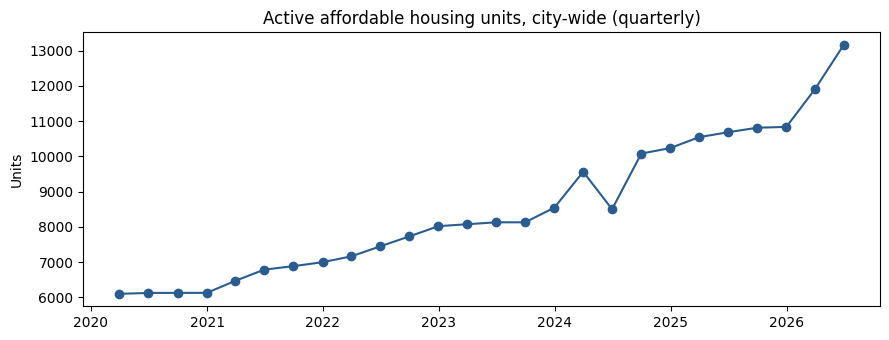

In [6]:
STOCK_OV = {}   # e.g. {"quarter": "Quarter", "affordable": "Affordable Housing Units", "subsidized": "Subsidized Housing Units"}

stock_raw = load_package_tables("active-affordable-and-social-housing-units", "active affordable and social housing units")
show(stock_raw, 5)
m = detect(stock_raw, STOCK_OV, {"quarter": [r"quarter|period"], "affordable": [r"afford.*(unit|home)", r"afford"],
                                 "subsidized": [r"subsid.*(unit|home)", r"subsid"], "ward": [r"^ward"]})
if m["ward"]:
    print("A ward column is present in this dataset; check the ward-level treatment before using it.")

def parse_quarter(s):
    t = str(s)
    mm = re.search(r"Q([1-4])\D{0,3}(\d{4})", t, re.I)
    if mm:
        q, y = int(mm.group(1)), int(mm.group(2))
    else:
        mm = re.search(r"(\d{4})\D{0,3}Q([1-4])", t, re.I)
        if not mm:
            return pd.NaT
        y, q = int(mm.group(1)), int(mm.group(2))
    return pd.Period(year=y, quarter=q, freq="Q").end_time.normalize()

fact_stock_city = pd.DataFrame({
    "quarter_label": stock_raw[m["quarter"]].astype(str),
    "quarter_end": stock_raw[m["quarter"]].map(parse_quarter),
    "affordable_units": to_num(stock_raw[m["affordable"]]) if m["affordable"] else np.nan,
    "subsidized_units": to_num(stock_raw[m["subsidized"]]) if m["subsidized"] else np.nan,
}).sort_values("quarter_end").reset_index(drop=True)
write_table(fact_stock_city, "fact_affordable_stock_city")

s = fact_stock_city.dropna(subset=["affordable_units", "quarter_end"])
STOCK_LATEST = float(s["affordable_units"].iloc[-1]) if len(s) else np.nan
STOCK_LATEST_Q = s["quarter_label"].iloc[-1] if len(s) else "n/a"
if len(s) >= 4:
    t_years = (s["quarter_end"] - s["quarter_end"].iloc[0]).dt.days / 365.25
    STOCK_TREND_PER_YEAR = float(np.polyfit(t_years, s["affordable_units"], 1)[0])
else:
    STOCK_TREND_PER_YEAR = np.nan
log_dq("Active Affordable & Social Housing", len(stock_raw), 0, None,
       "city-wide quarterly series; no ward or address, so it is not mapped and writes no events")
print(f"Quarters with data: {len(s)}.  Latest ({STOCK_LATEST_Q}): {STOCK_LATEST:,.0f} affordable units.  "
      f"Fitted trend: {STOCK_TREND_PER_YEAR:+,.0f} units per year")
print("Subsidized housing units reported as n/a in", int(fact_stock_city["subsidized_units"].isna().sum()), "of", len(fact_stock_city), "quarters")
plt.figure(figsize=(9, 3.5))
plt.plot(s["quarter_end"], s["affordable_units"], marker="o", color="#2b5c8f")
plt.title("Active affordable housing units, city-wide (quarterly)"); plt.ylabel("Units")
finish_plot("b2_stock_city")


## B3. Affordable Rental Housing Pipeline
Projects approved or in development, each with a status. Every project is assigned a stage (`completed`, `under_construction`, `approved`, `planning`, `other`), and each stage has a delivery probability and delivery window defined in `PIPELINE_ASSUMPTIONS` (Section 0).

- Projects already occupied are **excluded** from future supply.
- The probabilities are **planning assumptions, not estimates from data**, so the forecast is also run under low and high scenarios.

In [7]:
PIPE_OV = {}
STAGE_OVERRIDE = {}     # e.g. {"Some Exact Status Text": "approved"}

pipe_raw = load_package_tables("upcoming-and-recently-completed-affordable-housing-units", "affordable rental housing pipeline")
show(pipe_raw)
m = detect(pipe_raw, PIPE_OV, {
    "pid": [r"^Project ID"], "ward": [r"Ward Number", r"^ward.*(num|id|code)", r"^ward"], "geom": [r"^geometry$"],
    "address": [r"^Addresses", r"address"], "units": [r"^Affordable Homes Approved", r"afford.*(unit|home)"],
    "rgi": [r"^RGI"], "supportive": [r"^Supportive"], "rent_ctrl": [r"Rent-Controlled"], "status": [r"^status", r"status|stage"]})

pipe = pipe_raw.copy()
if m["pid"]:
    n0 = len(pipe); pipe = pipe.drop_duplicates(m["pid"]).reset_index(drop=True)
    if n0 != len(pipe):
        print(f"   removed {n0 - len(pipe)} rows repeating a Project ID")
pipe = add_coords(pipe, geom_col=m["geom"])
pipe = finalize_geo(pipe, ward_col=m["ward"], lat_col="_lat", lon_col="_lon", label="Affordable Pipeline")

def pipeline_stage(status):
    t = str(status).lower()
    if status in STAGE_OVERRIDE:
        return STAGE_OVERRIDE[status]
    if re.search(r"occupied|complet", t):                        return "completed"
    if re.search(r"construction|building permit|permit issued", t): return "under_construction"
    if re.search(r"approved|council|zoning|opa", t):             return "approved"
    if re.search(r"application|review|planning|pre-?app|proposal|prelim", t): return "planning"
    return "other"

pipe["units"] = to_num(pipe[m["units"]]).fillna(0)
pipe["stage"] = pipe[m["status"]].map(pipeline_stage)
pipe["p_deliver"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][0])
pipe["deliver_lo"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][1])
pipe["deliver_hi"] = pipe["stage"].map(lambda s_: PIPELINE_ASSUMPTIONS[s_][2])

def p_by_year(h, lo, hi):
    """Share of a project's delivery window (years lo..hi, uniform) that falls on or before year h."""
    return np.clip((np.minimum(h, hi) - lo + 1) / (hi - lo + 1), 0, 1)

for h in (FORECAST_YEARS,):
    pipe[f"expected_units_{h}y"] = pipe["units"] * pipe["p_deliver"] * p_by_year(h, pipe["deliver_lo"], pipe["deliver_hi"])

print("\nStatus -> stage mapping (check this table; use STAGE_OVERRIDE to correct it):")
disp(pipe.groupby([m["status"], "stage"]).agg(projects=("units", "size"), affordable_units=("units", "sum")).reset_index(), digits=0)

fact_pipe = pd.DataFrame({
    "_uid": pipe["_uid"], "project_id": pipe[m["pid"]] if m["pid"] else None, "address": pipe[m["address"]] if m["address"] else None,
    "status": pipe[m["status"]], "stage": pipe["stage"], "units": pipe["units"],
    "rgi_units": to_num(pipe[m["rgi"]]) if m["rgi"] else np.nan, "supportive_units": to_num(pipe[m["supportive"]]) if m["supportive"] else np.nan,
    "p_deliver": pipe["p_deliver"], "deliver_lo": pipe["deliver_lo"], "deliver_hi": pipe["deliver_hi"],
    f"expected_units_{FORECAST_YEARS}y": pipe[f"expected_units_{FORECAST_YEARS}y"],
    "ward_id": pipe["ward_id"], "neighbourhood_id": pipe["neighbourhood_id"], "geo_method": pipe["geo_method"]})
write_table(fact_pipe, "fact_affordable_pipeline")
log_dq("Affordable Rental Housing Pipeline", len(pipe_raw), 0, pipe,
       "snapshot with no dates -> fact table only, no events; completed projects excluded from future supply")
fut = fact_pipe[fact_pipe.stage != "completed"]
print(f"\nProjects: {len(fact_pipe)}. Affordable units approved in total: {fact_pipe.units.sum():,.0f} "
      f"(of which already completed/occupied: {fact_pipe.loc[fact_pipe.stage=='completed','units'].sum():,.0f}).")
print(f"Future pipeline (not completed): {fut.units.sum():,.0f} units; expected delivered within {FORECAST_YEARS} years "
      f"under base assumptions: {fut[f'expected_units_{FORECAST_YEARS}y'].sum():,.0f}. Ward unmapped: {(pipe.geo_method=='unmapped').mean():.1%}")

Loaded 'Affordable Housing Pipeline' [upcoming-and-recently-completed-affordable-housing-units]: 277 rows, 15 cols
   - loaded: Affordable Rental Housing Pipeline (277 rows)
   - skipped duplicate copy of an already-loaded table: Affordable Rental Housing Pipeline - 4326.csv
   - skipped duplicate copy of an already-loaded table: Affordable Rental Housing Pipeline - 2952.csv


,_id,Project ID,Addresses,Anchor Address,Status,Ward Number,Ward Name,Affordable Homes Approved,Rent-Controlled Market Units Approved,RGI Homes Approved,Supportive Units,Toronto Builds Portfolio,geometry,_uid,_resource
0,1,P0058,West Don Lands (phase 2 in PH5.3) Block 3/4/7 ...,373 Front St E,Occupied,13,Toronto Centre,275,0.0,0,0,No,"{""type"": ""Point"", ""coordinates"": [-79.35990217...",0-1,Affordable Rental Housing Pipeline
1,2,P0332,"985 Woodbine Avenue and 2078, 2086, 2100, 2102...",985 Woodbine Ave,Approved OPAs and Zoning By-Law Amendments,19,Beaches-East York,12,0.0,0,0,No,"{""type"": ""Point"", ""coordinates"": [-79.31250395...",0-2,Affordable Rental Housing Pipeline
2,3,P0107,976 College Street,976 College St,Planning Applications Under Review,9,Davenport,0,0.0,19,19,No,"{""type"": ""Point"", ""coordinates"": [-79.427965, ...",0-3,Affordable Rental Housing Pipeline


Detected columns: {'pid': 'Project ID', 'ward': 'Ward Number', 'geom': 'geometry', 'address': 'Addresses', 'units': 'Affordable Homes Approved', 'rgi': 'RGI Homes Approved', 'supportive': 'Supportive Units', 'rent_ctrl': 'Rent-Controlled Market Units Approved', 'status': 'Status'}
   coordinates: geometry:277 -> 100.0% of rows have a point
   spatial vs source-ward agreement: 100.0% on 277 rows

Status -> stage mapping (check this table; use STAGE_OVERRIDE to correct it):


,Status,stage,projects,affordable_units
0,Approved OPAs and Zoning By-Law Amendments,approved,140,11361
1,Approved Site Plan Application,approved,1,129
2,Building Permit Application,under_construction,4,122
3,Issued Building Permit,under_construction,2,87
4,Occupied,completed,35,656
5,Planning Applications Under Review,planning,34,5470
6,Pre-Planning,planning,17,1866
7,Started Construction,under_construction,44,2841



Projects: 277. Affordable units approved in total: 22,532 (of which already completed/occupied: 656).
Future pipeline (not completed): 21,876 units; expected delivered within 5 years under base assumptions: 12,701. Ward unmapped: 0.0%


## B4. RentSafeTO — Apartment Building Evaluation
The notebook keeps each building's evaluation history and measures the change between its latest and previous score.

| Term | Definition |
|---|---|
| **Red band** | Score below `RS_RED_BELOW` (City colour bands: green 85–100, yellow 70–84, red below 70) |
| **Degrading** | Latest score at least `RS_DROP_POINTS` (5) below the previous score — the City's engagement trigger |
| **Watch list** (`at_risk`) | Red band **or** degrading |

The City also prioritises the lowest 2.5% of scores each year for audit (`RS_AUDIT_PERCENTILE`). *Confirm the bands against current programme rules before presenting.*

   merged differently-spelled columns: ['YEAR REGISTERED + YEAR_REGISTERED', 'YEAR BUILT + YEAR_BUILT', 'YEAR EVALUATED + YEAR_EVALUATED', 'PROPERTY TYPE + PROPERTY_TYPE', 'SITE ADDRESS + SITE_ADDRESS', 'CONFIRMED STOREYS + CONFIRMED_STOREYS', 'CONFIRMED UNITS + CONFIRMED_UNITS', 'EVALUATION COMPLETED ON + EVALUATION_COMPLETED_ON']
Loaded 'Apartment Building Evaluation' [apartment-building-evaluation]: 18,917 rows, 91 cols  (removed 1 exact duplicate rows)
   - loaded: Apartment Building Evaluations 2023 - current (7,158 rows)
   - loaded: Pre-2023 Apartment Building Evaluations (11,760 rows)
   - skipped duplicate copy of an already-loaded table: Apartment Building Evaluations 2023 - current.csv
   - skipped duplicate copy of an already-loaded table: Pre-2023 Apartment Building Evaluations.csv
Detected columns: {'rsn': 'RSN', 'ward': 'WARD', 'lat': 'LATITUDE', 'lon': 'LONGITUDE', 'address': 'SITE ADDRESS', 'score': 'CURRENT BUILDING EVAL SCORE', 'units': 'CONFIRMED UNITS', 'year_built

eval_date,2023,2024,2025,2026
count,1749.0,1805.0,1734.0,1870.0
mean,87.6,87.2,91.0,90.8
median,89.0,89.0,92.0,92.0


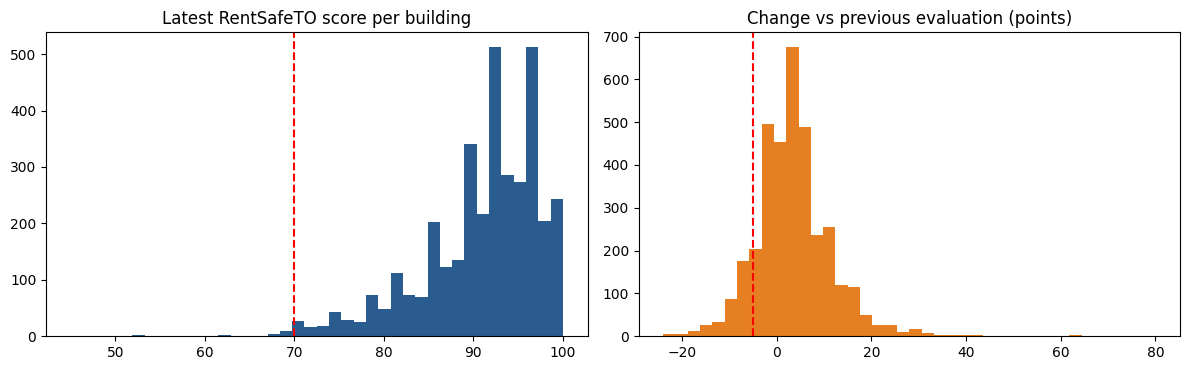

In [8]:
RS_OV = {}

rs_raw = load_package_tables("apartment-building-evaluation", "RentSafeTO apartment building evaluation")
m = detect(rs_raw, RS_OV, {
    "rsn": [r"^RSN$"], "ward": [r"^WARD$", r"^ward"], "lat": [r"^lat"], "lon": [r"^lon"], "address": [r"site.?address", r"address"],
    "score": [r"CURRENT.*BUILDING.*EVAL.*SCORE", r"EVAL.*SCORE", r"^score"], "units": [r"CONFIRMED.?UNITS", r"unit"],
    "year_built": [r"YEAR.?BUILT"], "eval_date": [r"EVALUATION.?COMPLETED", r"EVAL.*DATE"], "eval_year": [r"YEAR.?EVALUATED"]})
assert m["rsn"] and m["score"], "RSN / score column not found - set RS_OV"

rs = rs_raw.copy()
rs["eval_date"] = sane_dates(to_dt(rs[m["eval_date"]])) if m["eval_date"] else pd.Series(pd.NaT, index=rs.index)
if m["eval_year"]:
    yr_fallback = pd.to_datetime(to_num(rs[m["eval_year"]]).round().astype("Int64").astype(str) + "-07-01", errors="coerce")
    rs["eval_date"] = rs["eval_date"].fillna(yr_fallback)
rs["score_v"] = to_num(rs[m["score"]]).where(lambda x: x.between(0, 100))
n_noscore = int(rs["score_v"].isna().sum())
rs = rs.dropna(subset=["score_v", "eval_date"]).sort_values([m["rsn"], "eval_date"]).reset_index(drop=True)
print(f"   {n_noscore:,} rows without a valid score or date were dropped; {len(rs):,} evaluations remain")

hist = rs[[m["rsn"], "eval_date", "score_v"]].rename(columns={m["rsn"]: "rsn"})
write_table(hist, "fact_rentsafe_history")

rs["prev_score"] = rs.groupby(m["rsn"])["score_v"].shift(1)
rs["prev_date"] = rs.groupby(m["rsn"])["eval_date"].shift(1)
rs["n_evals"] = rs.groupby(m["rsn"]).cumcount() + 1
latest = rs.groupby(m["rsn"]).tail(1).copy().reset_index(drop=True)          # one row per building: its latest evaluation
latest["score_delta"] = latest["score_v"] - latest["prev_score"]
latest["days_between_evals"] = (latest["eval_date"] - latest["prev_date"]).dt.days

latest = finalize_geo(latest, ward_col=m["ward"], lat_col=m["lat"], lon_col=m["lon"], label="RentSafeTO")
latest["score"] = latest["score_v"]
latest["units"] = to_num(latest[m["units"]]).fillna(0) if m["units"] else 0
latest["year_built"] = to_num(latest[m["year_built"]]) if m["year_built"] else np.nan
latest["red_band"] = latest["score"] < RS_RED_BELOW
latest["degrading"] = latest["score_delta"] <= -RS_DROP_POINTS
latest["at_risk"] = latest["red_band"] | latest["degrading"]
eval_year = latest["eval_date"].dt.year
audit_cut = latest.groupby(eval_year)["score"].transform(lambda x: x.quantile(RS_AUDIT_PERCENTILE))
latest["audit_priority"] = latest["score"] <= audit_cut

fact_rs = latest[["_uid", "ward_id", "neighbourhood_id", "geo_method", "score", "prev_score", "score_delta", "days_between_evals",
                  "n_evals", "units", "year_built", "eval_date", "red_band", "degrading", "at_risk", "audit_priority"]].copy()
fact_rs["rsn"] = latest[m["rsn"]]
fact_rs["address"] = latest[m["address"]] if m["address"] else None
write_table(fact_rs, "fact_rentsafe")
log_dq("RentSafeTO Evaluation", len(rs_raw), 0, latest, "building-level table (latest evaluation per building); history in fact_rentsafe_history")

print(f"\n{len(latest):,} buildings, {latest.units.sum():,.0f} units ({(latest.units == 0).mean():.1%} of buildings have no unit count).")
print(f"Latest score: mean {latest.score.mean():.1f}, median {latest.score.median():.1f}, 5th percentile {latest.score.quantile(.05):.1f}")
print(f"Red band (<{RS_RED_BELOW}): {latest.red_band.sum():,} buildings / {latest.loc[latest.red_band,'units'].sum():,.0f} units")
print(f"Degrading (drop >= {RS_DROP_POINTS} pts; {latest.score_delta.notna().sum():,} buildings have 2+ evaluations): "
      f"{latest.degrading.sum():,} buildings / {latest.loc[latest.degrading,'units'].sum():,.0f} units")
print(f"Watch list (red or degrading): {latest.at_risk.sum():,} buildings / {latest.loc[latest.at_risk,'units'].sum():,.0f} units")

# Is the score scale consistent across the 2023 change in evaluation files? A jump would make 'degradation' meaningless.
by_year = rs.groupby(rs["eval_date"].dt.year)["score_v"].agg(["count", "mean", "median"]).round(1)
disp(by_year.T)
yrs = by_year.index
if 2022 in yrs and 2023 in yrs and abs(by_year.loc[2023, "mean"] - by_year.loc[2022, "mean"]) > 5:
    print("WARNING: mean score changes by more than 5 points between 2022 and 2023. The evaluation method may have changed; "
          "treat score_delta that spans 2022->2023 with caution.")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(latest["score"], bins=40, color="#2b5c8f"); ax[0].axvline(RS_RED_BELOW, color="r", ls="--"); ax[0].set_title("Latest RentSafeTO score per building")
ax[1].hist(latest["score_delta"].dropna(), bins=40, color="#e67e22"); ax[1].axvline(-RS_DROP_POINTS, color="r", ls="--"); ax[1].set_title("Change vs previous evaluation (points)")
finish_plot("b4_rentsafe_distributions")

## B5. Ward-Level Depletion Picture
Combines B1–B4 into one table per ward. Counts are summed only over rows that have a ward.

`pipeline_cover` = expected five-year affordable pipeline deliveries ÷ affordable units slated for demolition. It is left empty (not filled) where no demolition is planned.

Reconciliation  demolition: ward sum 4,311 vs total 4,311 | pipeline: 21,876 vs 21,876 | RentSafe buildings: 3,611 vs 3,611


,ward_name,aff_demolished,aff_replaced,demolition_cases,pipeline_units,pipeline_expected_5y,pipeline_projects,pipeline_completed_units,rs_buildings,rs_units,rs_avg_score,units_red,units_degrading,units_watch,buildings_watch,net_affordable_change,pipeline_cover,pct_units_watch,pct_buildings_watch
ward_id,,,,,,,,,,,,,,,,,,,
16,Don Valley East,315.0,300.0,5.0,793.0,578.85,3.0,0.0,159,16412.0,91.36,248.0,3870.0,3870.0,21.0,-15.0,1.84,0.24,0.13
5,York South-Weston,59.0,56.0,6.0,1577.0,1009.39,10.0,0.0,238,18354.0,87.88,28.0,5430.0,5430.0,49.0,-3.0,17.11,0.30,0.21
3,Etobicoke-Lakeshore,17.0,17.0,2.0,2049.0,1165.90,19.0,0.0,250,13968.0,92.70,87.0,998.0,998.0,26.0,0.0,68.58,0.07,0.10
1,Etobicoke North,0.0,0.0,0.0,60.0,14.40,2.0,0.0,83,9838.0,92.43,0.0,665.0,665.0,3.0,0.0,NaN,0.07,0.04
7,Humber River-Black Creek,236.0,236.0,1.0,188.0,131.60,2.0,0.0,103,15116.0,90.69,0.0,1097.0,1097.0,9.0,0.0,0.56,0.07,0.09
2,Etobicoke Centre,196.0,196.0,2.0,131.0,91.70,2.0,172.0,133,12828.0,94.27,0.0,250.0,250.0,2.0,0.0,0.47,0.02,0.02
14,Toronto-Danforth,195.0,195.0,6.0,1996.0,1250.92,16.0,100.0,151,9985.0,89.50,74.0,1699.0,1699.0,30.0,0.0,6.41,0.17,0.20
17,Don Valley North,87.0,87.0,3.0,1801.0,640.90,14.0,0.0,74,11901.0,91.82,0.0,1078.0,1078.0,7.0,0.0,7.37,0.09,0.09


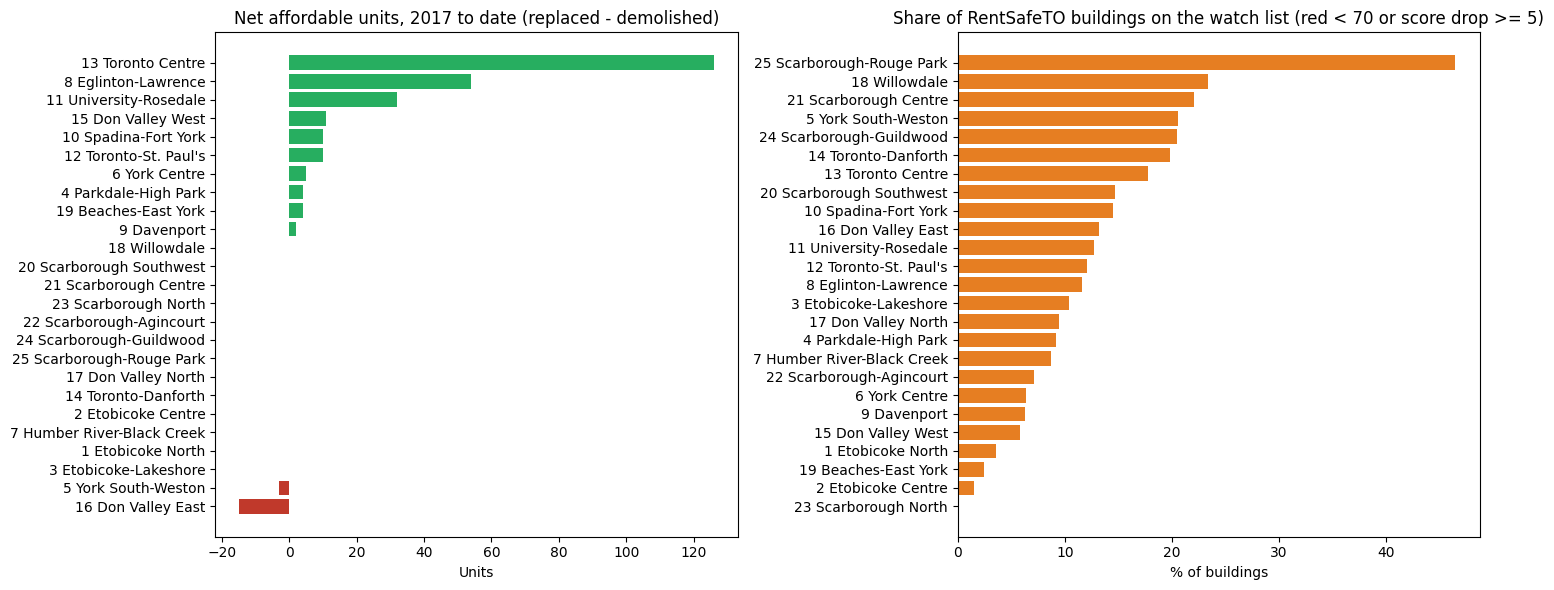

In [9]:
wd = pd.DataFrame({"ward_name": WARD_NAME})
wd.index.name = "ward_id"
wd = wd.join(by_ward(demo, aff_demolished=("dem_aff", "sum"), aff_replaced=("rep_aff", "sum"), demolition_cases=("_uid", "count")))
wd = wd.join(by_ward(fact_pipe[fact_pipe.stage != "completed"], pipeline_units=("units", "sum"),
                     pipeline_expected_5y=(f"expected_units_{FORECAST_YEARS}y", "sum"), pipeline_projects=("_uid", "count")))
wd = wd.join(by_ward(fact_pipe[fact_pipe.stage == "completed"], pipeline_completed_units=("units", "sum")))
wd = wd.join(by_ward(fact_rs, rs_buildings=("_uid", "count"), rs_units=("units", "sum"), rs_avg_score=("score", "mean")))
wd = wd.join(by_ward(fact_rs[fact_rs.red_band], units_red=("units", "sum")))
wd = wd.join(by_ward(fact_rs[fact_rs.degrading], units_degrading=("units", "sum")))
wd = wd.join(by_ward(fact_rs[fact_rs.at_risk], units_watch=("units", "sum"), buildings_watch=("_uid", "count")))
for col in wd.columns.drop(["ward_name", "rs_avg_score"]):
    wd[col] = wd[col].fillna(0)             # a sum over no matching records is genuinely 0
wd["net_affordable_change"] = wd["aff_replaced"] - wd["aff_demolished"]
wd["pipeline_cover"] = np.where(wd["aff_demolished"] > 0, wd["pipeline_expected_5y"] / wd["aff_demolished"], np.nan)
wd["pct_units_watch"] = np.where(wd["rs_units"] > 0, wd["units_watch"] / wd["rs_units"], np.nan)
wd["pct_buildings_watch"] = np.where(wd["rs_buildings"] > 0, wd["buildings_watch"] / wd["rs_buildings"], np.nan)
write_table(wd.reset_index(), "ward_depletion")

# reconciliation: ward sums must equal the dataset totals (unmapped rows are the only allowed difference)
print(f"Reconciliation  demolition: ward sum {wd.aff_demolished.sum():,.0f} vs total {demo.dem_aff.sum():,.0f} | "
      f"pipeline: {wd.pipeline_units.sum():,.0f} vs {fut.units.sum():,.0f} | RentSafe buildings: {wd.rs_buildings.sum():,.0f} vs {len(fact_rs):,}")
disp(wd.sort_values("net_affordable_change").head(8))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sdf = wd.sort_values("net_affordable_change")["net_affordable_change"]
ax[0].barh([f"{i} {WARD_NAME[i]}" for i in sdf.index], sdf.values, color=np.where(sdf.values < 0, "#c0392b", "#27ae60"))
ax[0].set_title("Net affordable units, 2017 to date (replaced - demolished)"); ax[0].set_xlabel("Units")
s2 = wd["pct_buildings_watch"].dropna().sort_values()
ax[1].barh([f"{i} {WARD_NAME[i]}" for i in s2.index], s2.values * 100, color="#e67e22")
ax[1].set_title(f"Share of RentSafeTO buildings on the watch list (red < {RS_RED_BELOW} or score drop >= {RS_DROP_POINTS})"); ax[1].set_xlabel("% of buildings")
finish_plot("b5_ward_depletion")

## B6. Forecast: Net Flow of Affordable Units, 1–5 Years Ahead, by Ward
**Definition.** For each ward and horizon *h* = 1…5 years:

`net flow(h) = pipeline units delivered by year h − cumulative net affordable loss (demolished − replaced) by year h`

A **deficit** is `net flow < 0`. The output is a probability of deficit and a 10–90% range, not a single number.

**Back-test first.** Demolition events are rare (about 170 in nine years across 25 wards), so most ward-years are zero and a sophisticated forecast may be no better than "predict zero". Candidate estimators are tested on unseen years (rolling origin: train on years before *T*, predict year *T*). The best statistical estimator is then used for the simulation, and its error is reported next to the baselines. The notebook states plainly if nothing beats them.

**Excluded from the baseline forecast.** RentSafeTO degradation is shown as a separate stress test, because these files contain no history linking a low score to a later loss of units.

In [10]:
last_full_year = AS_OF.year - 1
years = list(range(PANEL_START_YEAR, last_full_year + 1))
dm = demo.assign(year=pd.to_datetime(demo["event_date"]).dt.year).dropna(subset=["ward_id", "year"]).copy()
dm["ward_id"] = dm["ward_id"].astype(int)
dm["net_loss"] = dm["dem_aff"] - dm["rep_aff"]
H = (dm.groupby(["ward_id", "year"])["net_loss"].sum().unstack("year").reindex(index=range(1, 26), columns=years).fillna(0))
print(f"Annual net affordable loss matrix: {H.shape[0]} wards x {H.shape[1]} years ({years[0]}-{years[-1]}); "
      f"{(H.values != 0).mean():.0%} of ward-years are non-zero")

def one_step(train, kind, K=None):
    n = train.shape[1]; pool = float(train.values.mean())
    if kind == "zero":    return pd.Series(0.0, index=train.index)
    if kind == "last":    return train.iloc[:, -1].astype(float)
    if kind == "recent3": return train.iloc[:, -3:].mean(axis=1)
    if kind == "pooled":  return pd.Series(pool, index=train.index)
    w = n / (n + K)       # shrinkage: K = pseudo-years of pooled history (K=0 -> ward's own mean only)
    return w * train.mean(axis=1) + (1 - w) * pool

METHODS = {"Zero loss (baseline)": ("zero", None), "Last year (baseline)": ("last", None), "Last 3 years mean": ("recent3", None),
           "Pooled mean, same for all wards": ("pooled", None), "Ward's own mean": ("shrink", 0),
           "Shrinkage K=1": ("shrink", 1), "Shrinkage K=3": ("shrink", 3), "Shrinkage K=6": ("shrink", 6)}
K_OF = {"Pooled mean, same for all wards": None, "Ward's own mean": 0, "Shrinkage K=1": 1, "Shrinkage K=3": 3, "Shrinkage K=6": 6}

rows = []
for T in years[MIN_TRAIN_YEARS:]:
    tr_ = H[[y for y in years if y < T]]
    actual = H[T]
    for name, (kind, K) in METHODS.items():
        p = one_step(tr_, kind, K)
        rho = stats.spearmanr(p, actual)[0] if p.nunique() > 1 and actual.nunique() > 1 else np.nan
        rows.append({"test_year": T, "method": name, "MAE": (actual - p).abs().mean(), "RMSE": np.sqrt(((actual - p) ** 2).mean()),
                     "city_total_error": p.sum() - actual.sum(), "rank_corr": rho})
bt = pd.DataFrame(rows)
bt_sum = bt.groupby("method").agg(MAE=("MAE", "mean"), RMSE=("RMSE", "mean"), abs_city_error=("city_total_error", lambda x: x.abs().mean()),
                                  rank_corr=("rank_corr", "mean")).sort_values("MAE")
bt_sum["MAE_skill_vs_pooled_%"] = 100 * (1 - bt_sum["MAE"] / bt_sum.loc["Pooled mean, same for all wards", "MAE"])
print(f"Rolling-origin back-test, test years {years[MIN_TRAIN_YEARS]}-{years[-1]} (units per ward-year; lower error is better):")
disp(bt_sum)
disp(bt.pivot(index="method", columns="test_year", values="MAE"))
write_table(bt_sum.reset_index(), "backtest_affordable_loss")

cand = sorted(K_OF, key=lambda k: (round(bt_sum.loc[k, "MAE"], 4), -(1e9 if K_OF[k] is None else K_OF[k])))   # ties -> more pooling
champion = cand[0]; CHAMP_K = K_OF[champion]
zero_mae, champ_mae = bt_sum.loc["Zero loss (baseline)", "MAE"], bt_sum.loc[champion, "MAE"]
print(f"\nChosen method: {champion} (MAE {champ_mae:.2f}; 'predict zero' MAE {zero_mae:.2f}).")
if champ_mae >= zero_mae:
    print("No method beats the predict-zero baseline on average error. Losses are rare and lumpy, so these forecasts are better used as risk rankings with ranges than as point predictions.")
else:
    print(f"The chosen method reduces average error by {100 * (1 - champ_mae / zero_mae):.0f}% compared with predicting zero.")


Annual net affordable loss matrix: 25 wards x 9 years (2017-2025); 8% of ward-years are non-zero
Rolling-origin back-test, test years 2020-2025 (units per ward-year; lower error is better):


,MAE,RMSE,abs_city_error,rank_corr,MAE_skill_vs_pooled_%
method,,,,,
Zero loss (baseline),1.30,5.16,31.17,NaN,20.31
"Pooled mean, same for all wards",1.63,5.25,34.34,NaN,0.00
Shrinkage K=6,1.66,5.57,34.34,0.23,-2.01
Shrinkage K=3,1.69,5.75,34.34,0.23,-3.74
Shrinkage K=1,1.73,5.97,34.34,0.23,-6.33
Ward's own mean,1.77,6.14,34.34,0.23,-8.50
Last 3 years mean,2.05,7.68,42.72,0.27,-25.46
Last year (baseline),2.26,8.72,50.83,0.21,-38.54


test_year,2020,2021,2022,2023,2024,2025
method,,,,,,
Last 3 years mean,1.17,0.33,1.25,4.91,2.08,2.53
Last year (baseline),1.12,0.92,1.04,4.76,5.28,0.44
"Pooled mean, same for all wards",1.00,0.13,1.15,5.49,0.95,1.07
Shrinkage K=1,1.13,0.33,1.28,5.31,1.03,1.33
Shrinkage K=3,1.08,0.26,1.25,5.34,0.97,1.26
Shrinkage K=6,1.05,0.21,1.22,5.38,0.93,1.20
Ward's own mean,1.17,0.40,1.31,5.28,1.07,1.38
Zero loss (baseline),0.88,0.04,1.08,5.36,0.08,0.36



Chosen method: Pooled mean, same for all wards (MAE 1.63; 'predict zero' MAE 1.30).
No method beats the predict-zero baseline on average error. Losses are rare and lumpy, so these forecasts are better used as risk rankings with ranges than as point predictions.


,test_year,ward_coverage_80%,city_total_inside_range
0,2020,0.88,False
1,2021,0.96,True
2,2022,0.84,False
3,2023,0.80,False
4,2024,0.96,True
5,2025,0.92,True


Ward-level 10-90% range contained the actual value 89% of the time (target 80%; zeros inflate this); city total inside its range in 3 of 6 test years.
City-wide forecast (units, 10th / 50th / 90th percentile). Current protected stock (Q2 2026): 13,163


,horizon_years,loss_p10,loss_p50,loss_p90,gain_p10,gain_p50,gain_p90,net_p10,net_p50,net_p90,p_deficit
0,1,-90.0,-6.0,1.0,530.0,956.0,1423.0,547.0,975.0,1449.0,0.0
1,2,-121.0,-19.0,1.0,2919.0,3882.0,5119.0,2952.0,3913.0,5149.0,0.0
2,3,-143.0,-32.0,-2.0,6094.0,7393.0,9061.0,6157.0,7446.0,9108.0,0.0
3,4,-171.0,-49.0,-7.0,8429.0,10004.0,11941.0,8502.0,10082.0,12015.0,0.0
4,5,-216.0,-70.0,-13.0,10966.0,12590.0,14725.0,11054.0,12700.0,14838.0,0.0



Sensitivity of the 5-year city net flow to the pipeline delivery assumptions:


,scenario,pipeline_gain_mean_5y,net_flow_p10,net_flow_p50,net_flow_p90
0,low (x0.5),6336.0,4850.0,6328.0,8132.0
1,base (x1.0),12732.0,11074.0,12714.0,14917.0
2,high (x1.25),15310.0,13784.0,15209.0,17400.0



Wards ranked by probability of an affordable-unit deficit at year 5 (ties broken by median net flow):


,ward_id,ward_name,loss_p50,gain_mean,net_flow_p10,net_flow_p50,net_flow_p90,p_deficit,stress_extra_loss_watch_units
122,23,Scarborough North,0.0,0.00,0.0,0.0,11.0,0.06,0.00
100,1,Etobicoke North,0.0,14.52,0.0,0.0,60.0,0.04,33.25
117,18,Willowdale,0.0,7.03,0.0,10.0,16.0,0.03,99.75
101,2,Etobicoke Centre,0.0,92.44,2.0,131.0,136.0,0.01,12.50
106,7,Humber River-Black Creek,0.0,131.31,78.9,130.5,192.0,0.01,54.85
119,20,Scarborough Southwest,0.0,460.80,258.0,492.0,577.0,0.00,68.30
121,22,Scarborough-Agincourt,0.0,197.00,105.0,192.0,281.0,0.00,20.80
123,24,Scarborough-Guildwood,0.0,370.45,155.9,317.0,734.0,0.00,128.20
114,15,Don Valley West,0.0,132.85,90.9,135.0,175.0,0.00,65.45
108,9,Davenport,0.0,135.46,95.0,135.0,208.0,0.00,21.90


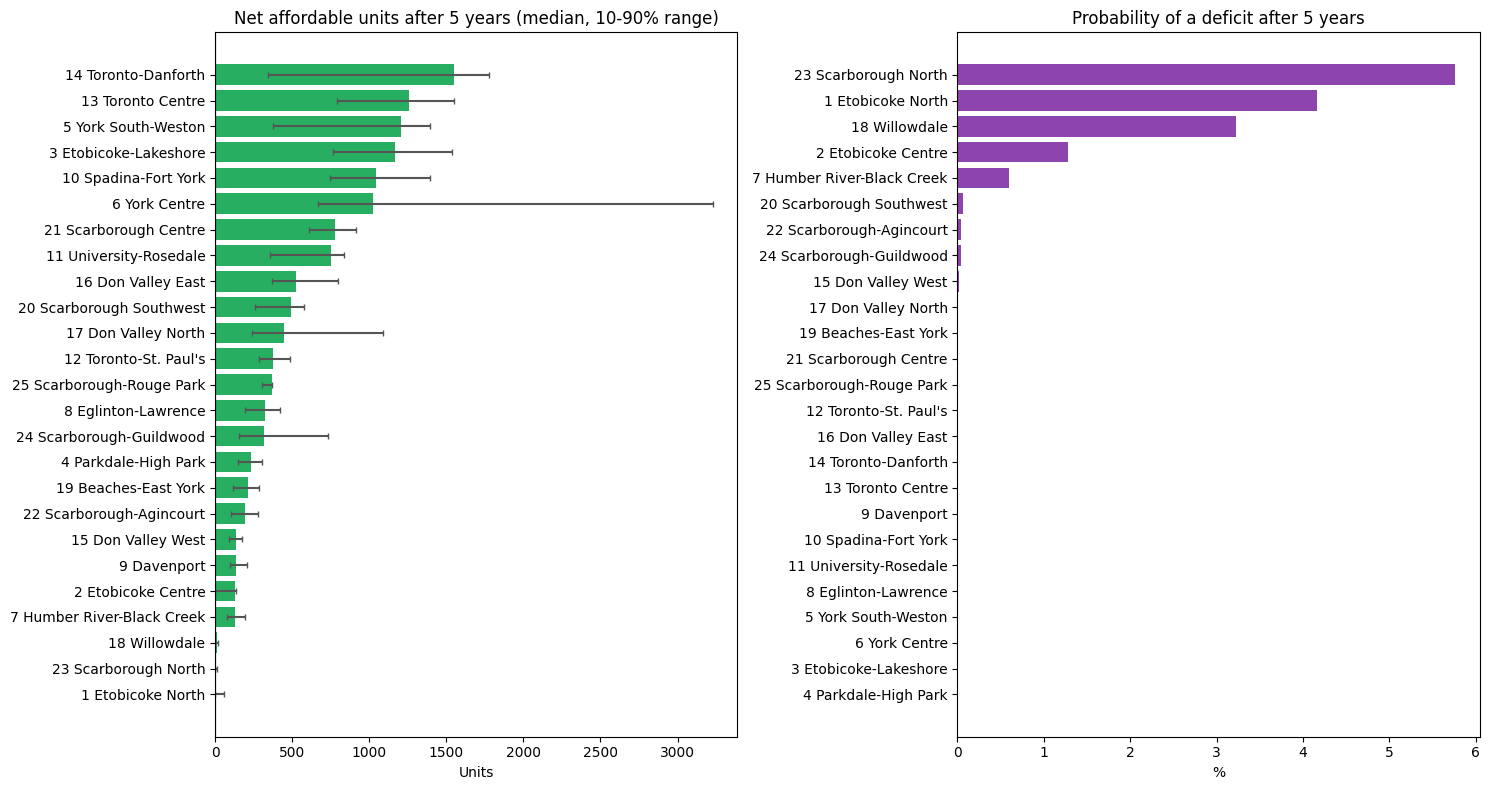

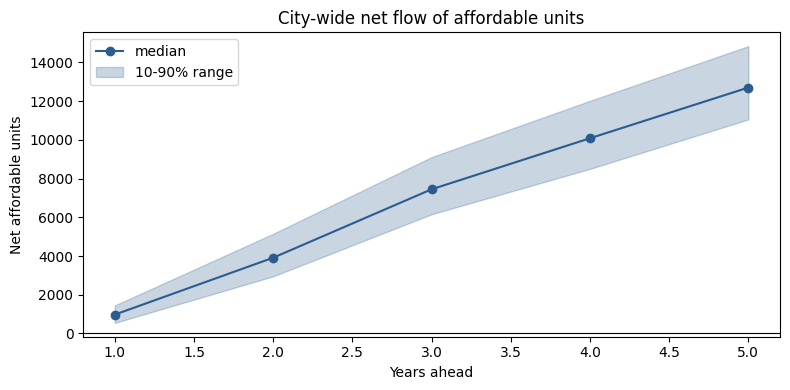

In [11]:
def draw_losses(train, K, horizon, sims, rng):
    """Simulated annual net loss, shape (sims, horizon, wards). Each ward-year is drawn from the ward's own history with
    probability n/(n+K), otherwise from the pooled history of all wards (K=None -> pooled only)."""
    n = train.shape[1]
    w = 0.0 if K is None else n / (n + K)
    pool = train.values.ravel()
    out = np.zeros((sims, horizon, train.shape[0]))
    for j in range(train.shape[0]):
        own = rng.choice(train.iloc[j].values, size=(sims, horizon))
        pl = rng.choice(pool, size=(sims, horizon))
        out[:, :, j] = np.where(rng.random((sims, horizon)) < w, own, pl)
    return out

# ---- calibration: do the 10-90% ranges contain the truth about 80% of the time? ----
cal = []
for T in years[MIN_TRAIN_YEARS:]:
    tr_ = H[[y for y in years if y < T]]
    d_ = draw_losses(tr_, CHAMP_K, 1, 2000, np.random.default_rng(SEED))[:, 0, :]
    lo_, hi_ = np.percentile(d_, 10, axis=0), np.percentile(d_, 90, axis=0)
    a_ = H[T].values
    ct = np.percentile(d_.sum(axis=1), [10, 90])
    cal.append({"test_year": T, "ward_coverage_80%": float(((a_ >= lo_) & (a_ <= hi_)).mean()),
                "city_total_inside_range": bool(ct[0] <= a_.sum() <= ct[1])})
cal = pd.DataFrame(cal)
disp(cal)
print(f"Ward-level 10-90% range contained the actual value {cal['ward_coverage_80%'].mean():.0%} of the time (target 80%; "
      f"zeros inflate this); city total inside its range in {cal['city_total_inside_range'].sum()} of {len(cal)} test years.")

# ---- main simulation: losses + staged pipeline deliveries ----
def simulate_flows(H_, K, horizon, sims, seed, p_mult=1.0):
    rng = np.random.default_rng(seed)
    loss = draw_losses(H_, K, horizon, sims, rng).cumsum(axis=1)                      # (sims, horizon, 25)
    pj = fact_pipe[(fact_pipe.stage != "completed") & fact_pipe.ward_id.notna() & (fact_pipe.units > 0)]
    widx = pj["ward_id"].astype(int).to_numpy() - 1
    onehot = np.zeros((len(pj), 25)); onehot[np.arange(len(pj)), widx] = 1
    units = pj["units"].to_numpy(float)
    lo, hi = pj["deliver_lo"].to_numpy(int), pj["deliver_hi"].to_numpy(int)
    deliver = rng.random((sims, len(pj))) < np.minimum(1.0, pj["p_deliver"].to_numpy(float) * p_mult)
    when = rng.integers(lo, hi + 1, size=(sims, len(pj)))
    gain = np.stack([((deliver & (when <= h)) * units) @ onehot for h in range(1, horizon + 1)], axis=1)   # (sims, horizon, 25)
    return loss, gain, gain - loss

loss_d, gain_d, net_d = simulate_flows(H, CHAMP_K, FORECAST_YEARS, SIMS, SEED)
watch_units = fact_rs[fact_rs.at_risk].dropna(subset=["ward_id"]).assign(ward_id=lambda d: d.ward_id.astype(int)).groupby("ward_id")["units"].sum().reindex(range(1, 26)).fillna(0)

rows = []
for h in range(1, FORECAST_YEARS + 1):
    for j, w in enumerate(range(1, 26)):
        L, G, N = loss_d[:, h - 1, j], gain_d[:, h - 1, j], net_d[:, h - 1, j]
        rows.append({"ward_id": w, "ward_name": WARD_NAME[w], "horizon_years": h,
                     "loss_p10": np.percentile(L, 10), "loss_p50": np.percentile(L, 50), "loss_p90": np.percentile(L, 90),
                     "gain_mean": G.mean(), "gain_p10": np.percentile(G, 10), "gain_p90": np.percentile(G, 90),
                     "net_flow_p10": np.percentile(N, 10), "net_flow_p50": np.percentile(N, 50), "net_flow_p90": np.percentile(N, 90),
                     "p_deficit": float((N < 0).mean()),
                     "stress_extra_loss_watch_units": watch_units[w] * STRESS_DEGRADATION_LOSS_RATE * h})
fc_aff = pd.DataFrame(rows)
write_table(fc_aff, "forecast_affordable_flow")

city_rows = []
for h in range(1, FORECAST_YEARS + 1):
    L, G, N = loss_d[:, h - 1, :].sum(axis=1), gain_d[:, h - 1, :].sum(axis=1), net_d[:, h - 1, :].sum(axis=1)
    city_rows.append({"horizon_years": h, "loss_p10": np.percentile(L, 10), "loss_p50": np.percentile(L, 50), "loss_p90": np.percentile(L, 90),
                      "gain_p10": np.percentile(G, 10), "gain_p50": np.percentile(G, 50), "gain_p90": np.percentile(G, 90),
                      "net_p10": np.percentile(N, 10), "net_p50": np.percentile(N, 50), "net_p90": np.percentile(N, 90), "p_deficit": float((N < 0).mean())})
fc_city = pd.DataFrame(city_rows)
write_table(fc_city, "forecast_affordable_flow_city")
print(f"City-wide forecast (units, 10th / 50th / 90th percentile). Current protected stock ({STOCK_LATEST_Q}): {STOCK_LATEST:,.0f}")
disp(fc_city, digits=0)

# ---- scenarios for the pipeline assumptions ----
sc = []
for name, mult in PIPELINE_SCENARIOS.items():
    _, g_, n_ = simulate_flows(H, CHAMP_K, FORECAST_YEARS, 2000, SEED, p_mult=mult)
    N5 = n_[:, -1, :].sum(axis=1)
    sc.append({"scenario": name, "pipeline_gain_mean_5y": g_[:, -1, :].sum(axis=1).mean(), "net_flow_p10": np.percentile(N5, 10),
               "net_flow_p50": np.percentile(N5, 50), "net_flow_p90": np.percentile(N5, 90)})
sc = pd.DataFrame(sc)
write_table(sc, "forecast_affordable_scenarios")
print("\nSensitivity of the 5-year city net flow to the pipeline delivery assumptions:")
disp(sc, digits=0)

f5 = fc_aff[fc_aff.horizon_years == FORECAST_YEARS].copy()
print(f"\nWards ranked by probability of an affordable-unit deficit at year {FORECAST_YEARS} (ties broken by median net flow):")
disp(f5.sort_values(["p_deficit", "net_flow_p50"], ascending=[False, True])[
    ["ward_id", "ward_name", "loss_p50", "gain_mean", "net_flow_p10", "net_flow_p50", "net_flow_p90", "p_deficit", "stress_extra_loss_watch_units"]].head(10), digits=2)

fig, ax = plt.subplots(1, 2, figsize=(15, 8))
f5s = f5.sort_values("net_flow_p50")
ax[0].barh([f"{i} {n}" for i, n in zip(f5s.ward_id, f5s.ward_name)], f5s.net_flow_p50, color=np.where(f5s.net_flow_p50 < 0, "#c0392b", "#27ae60"),
           xerr=[f5s.net_flow_p50 - f5s.net_flow_p10, f5s.net_flow_p90 - f5s.net_flow_p50], ecolor="#555", capsize=2)
ax[0].axvline(0, color="k", lw=.8); ax[0].set_title(f"Net affordable units after {FORECAST_YEARS} years (median, 10-90% range)"); ax[0].set_xlabel("Units")
f5p = f5.sort_values("p_deficit")
ax[1].barh([f"{i} {n}" for i, n in zip(f5p.ward_id, f5p.ward_name)], f5p.p_deficit * 100, color="#8e44ad")
ax[1].set_title(f"Probability of a deficit after {FORECAST_YEARS} years"); ax[1].set_xlabel("%")
finish_plot("b6_forecast_by_ward")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fc_city.horizon_years, fc_city.net_p50, marker="o", color="#2b5c8f", label="median")
ax.fill_between(fc_city.horizon_years, fc_city.net_p10, fc_city.net_p90, alpha=.25, color="#2b5c8f", label="10-90% range")
ax.axhline(0, color="k", lw=.8); ax.set_xlabel("Years ahead"); ax.set_ylabel("Net affordable units"); ax.set_title("City-wide net flow of affordable units"); ax.legend()
finish_plot("b6_forecast_city")

# Project 6 — Developer Responsiveness & Supply Forecasting
Three different delays are measured because they answer different questions.

| Measure | Definition | Who is slow? |
|---|---|---|
| **Approval lag** | `ISSUED_DATE − APPLICATION_DATE` of a building permit | Mostly the *City* |
| **Execution lag** | First housing building permit at the same address minus Development Application submission date | The *development process, end to end* |
| **Build lag** | `COMPLETED_DATE − ISSUED_DATE` | Mostly the *developer* |

Execution lag and build lag involve work that may not be finished (an application that has not reached a permit, a permit not yet completed). Averaging only finished cases would make developers look faster than they are, so both are estimated with **Kaplan–Meier survival curves**, which treat unfinished cases as "still waiting" rather than ignoring them.

## C1. Development Applications
Planning-stage pipeline (rezoning, site plan, subdivision, etc.). The event date is the submission date.

- **Units** are not a field in this dataset. They are parsed from the free-text description and flagged `units_parsed`; treat them as indicative.
- **Location.** Projected `X`/`Y` coordinates are converted to latitude/longitude so each application is placed in a ward and neighbourhood by location.

In [12]:
DEV_OV = {}

dev_raw = load_package_tables("development-applications", "development applications")
show(dev_raw)
m = detect(dev_raw, DEV_OV, {
    "date": [r"date.?submit", r"submit", r"application.*date", r"^date"], "type": [r"application.?type", r"^type"],
    "status": [r"^status"], "desc": [r"description"], "ward": [r"ward.?(num|id|code)", r"^ward"],
    "lat": [r"^lat"], "lon": [r"^lon|^lng"], "x": [r"^X$"], "y": [r"^Y$"],
    "street_num": [r"street.?num"], "street_name": [r"street.?name"], "street_type": [r"street.?type"], "folder": [r"FOLDERRSN"]})

dev = dev_raw.copy()
if m["folder"]:
    n0 = len(dev); dev = dev.drop_duplicates(m["folder"]).reset_index(drop=True)
    print(f"   {n0 - len(dev):,} rows repeating a FOLDERRSN removed; {len(dev):,} unique applications")
dev["event_date"] = sane_dates(to_dt(dev[m["date"]]))
print(f"   {int(dev['event_date'].isna().sum()):,} applications have no valid submission date (kept in the fact table, not evented)")
dev = add_coords(dev, lat_col=m["lat"], lon_col=m["lon"], x_col=m["x"], y_col=m["y"])
dev = finalize_geo(dev, ward_col=m["ward"], lat_col="_lat", lon_col="_lon", label="Development Applications")

UNIT_RE = re.compile(r"(\d[\d,]*)\s*(?:residential|dwelling|rental|affordable|condominium|apartment|new|replacement)?\s*"
                     r"(?:residential\s+)?(?:dwelling\s+)?(?:units?|suites?)\b", re.I)
def parse_units(text):
    nums = [int(x.replace(",", "")) for x in UNIT_RE.findall(str(text)) if x.replace(",", "").isdigit()]
    return max(nums) if nums else np.nan

HOUSING_RE = re.compile(r"residential|dwelling|rental|apartment|condominium|townhouse|mixed[- ]use|housing|\bunits?\b", re.I)
dev["units_parsed"] = dev[m["desc"]].map(parse_units) if m["desc"] else np.nan
dev["housing_related"] = (dev[m["desc"]].astype(str).str.contains(HOUSING_RE) | dev["units_parsed"].notna()) if m["desc"] else False

def addr_key(num, name, typ=None):
    """Street number + name + type, upper-case letters/digits only. Used to match applications to permits."""
    n = num.astype(str).str.extract(r"(\d+)")[0]
    k = n.fillna("") + "|" + name.fillna("").astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    if typ is not None:
        k = k + "|" + typ.fillna("").astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return k.where(n.notna() & name.notna())

if m["street_num"] and m["street_name"]:
    dev["addr_key"] = addr_key(dev[m["street_num"]], dev[m["street_name"]], dev[m["street_type"]] if m["street_type"] else None)
    dev["address"] = (dev[m["street_num"]].fillna("").astype(str) + " " + dev[m["street_name"]].fillna("").astype(str)
                      + (" " + dev[m["street_type"]].fillna("").astype(str) if m["street_type"] else "")).str.strip()
else:
    dev["addr_key"] = np.nan; dev["address"] = None
    print("Street number/name columns were not found, so application-to-permit matching will be skipped.")

fact_dev = pd.DataFrame({"_uid": dev["_uid"], "event_date": dev["event_date"], "address": dev["address"], "addr_key": dev["addr_key"],
                         "app_type": dev[m["type"]] if m["type"] else None, "status": dev[m["status"]] if m["status"] else None,
                         "units_parsed": dev["units_parsed"], "housing_related": dev["housing_related"], "ward_id": dev["ward_id"],
                         "neighbourhood_id": dev["neighbourhood_id"], "geo_method": dev["geo_method"]})
write_table(fact_dev, "fact_dev_applications")

ev_dev = make_events(dev, "_uid", "DEVAPP_", "DEV_APPLICATION", dev["event_date"], "Development Applications",
                     address="address", units=dev["units_parsed"])
write_events(ev_dev, ["Development Applications"])
log_dq("Development Applications", len(dev_raw), len(ev_dev), dev,
       f"units parsed from text for {dev['units_parsed'].notna().mean():.0%} of rows (indicative only); "
       f"{dev['housing_related'].mean():.0%} flagged housing-related by keyword")
print(f"{len(ev_dev):,} dated applications; units parsed for {dev['units_parsed'].notna().mean():.0%}; "
      f"housing-related {dev['housing_related'].mean():.0%}; ward unmapped {(dev.geo_method=='unmapped').mean():.1%}; "
      f"neighbourhood assigned {dev['neighbourhood_id'].notna().mean():.1%}")
disp(dev[m["type"]].value_counts().head(8).to_frame("applications").T if m["type"] else pd.DataFrame())


Loaded 'Development Applications' [development-applications]: 26,455 rows, 27 cols  (removed 258 exact duplicate rows)
   - loaded: Development Applications (26,713 rows)
   - skipped duplicate copy of an already-loaded table: Development Applications.csv


,_id,APPLICATION_TYPE,APPLICATION#,STREET_NUM,STREET_NAME,STREET_TYPE,STREET_DIRECTION,POSTAL,DATE_SUBMITTED,STATUS,X,Y,DESCRIPTION,REFERENCE_FILE#,FOLDERRSN,WARD_NUMBER,WARD_NAME,COMMUNITY_MEETING_DATE,COMMUNITY_MEETING_TIME,COMMUNITY_MEETING_LOCATION,APPLICATION_URL,CONTACT_NAME,CONTACT_PHONE,CONTACT_EMAIL,PARENT_FOLDER_NUMBER,_uid,_resource
0,1,OZ,25 138314 WET 05 OZ,320,SIDNEY BELSEY,CRES,,,2025-04-02T00:00:00,Closed,303949.89,4838773.22,City initiated Zoning By-law Amendment to appl...,NaN,5608120,05,York South-Weston,2025-05-07T00:00:00,7:00pm,Virtual,http://app.toronto.ca/AIC/index.do?folderRsn=V...,NaN,NaN,NaN,NaN,0-1,Development Applications
1,2,OZ,25 138314 WET 05 OZ,330,SIDNEY BELSEY,CRES,,,2025-04-02T00:00:00,Closed,304019.23,4838786.43,City initiated Zoning By-law Amendment to appl...,NaN,5608120,05,York South-Weston,2025-05-07T00:00:00,7:00pm,Virtual,http://app.toronto.ca/AIC/index.do?folderRsn=V...,NaN,NaN,NaN,NaN,0-2,Development Applications
2,3,OZ,25 189579 ESC 21 OZ,20,METROPOLITAN,RD,,M1R,2025-07-07T00:00:00,Application Received,320795.51,4847364.69,Proposed a mixed-use development comprised of...,NaN,5667191,21,Scarborough Centre,NaN,NaN,NaN,NaN,"Mahendran, Janani",416-338-3003,Janani.Mahendran@toronto.ca,23 128433 ESC 21 OZ,0-3,Development Applications


Detected columns: {'date': 'DATE_SUBMITTED', 'type': 'APPLICATION_TYPE', 'status': 'STATUS', 'desc': 'DESCRIPTION', 'ward': 'WARD_NUMBER', 'lat': None, 'lon': None, 'x': 'X', 'y': 'Y', 'street_num': 'STREET_NUM', 'street_name': 'STREET_NAME', 'street_type': 'STREET_TYPE', 'folder': 'FOLDERRSN'}
   17,816 rows repeating a FOLDERRSN removed; 8,639 unique applications
   0 applications have no valid submission date (kept in the fact table, not evented)
   X/Y converted from EPSG:2952 (100% of sampled points fall inside Toronto)
   coordinates: X/Y:8,538 -> 98.8% of rows have a point
   spatial vs source-ward agreement: 91.4% on 8,501 rows
8,639 dated applications; units parsed for 43%; housing-related 73%; ward unmapped 0.1%; neighbourhood assigned 98.5%


APPLICATION_TYPE,SA,OZ,CD,SB,PL
applications,4281,2789,1109,288,172


## C2. Building Permits — Active and Cleared
All rows of both packages are loaded (one copy of each table). Permits are de-duplicated on `PERMIT_NUM`, keeping the highest `REVISION_NUM`, so revisions are not double counted.

**Ward assignment.** Permits have no coordinates and no 25-ward field, but they carry `GEO_ID`. The assignment steps are:
1. Join `GEO_ID` to the Address Points layer to obtain coordinates, then place the permit by point-in-polygon.
2. For the remainder, use `WARD_GRID` **only as a lookup learned from permits that do have coordinates**, and only for grid codes where at least 90% of those permits fall in one ward. The lookup is tested on held-out permits before it is applied (the grid may follow the pre-2018 44-ward numbering, so it is not read directly).
3. Anything still unresolved stays `unmapped` and is excluded from ward totals.

**Data-entry errors.** Permits above `MAX_UNITS_PER_PERMIT`, or with 500+ units at a cost under `MIN_COST_PER_UNIT` per unit, have their units set to zero, are listed in the output, and carry the flag `outlier_units`. Lags above `MAX_LAG_DAYS` are treated as date errors.

In [13]:
ADDR_OV = {}     # override the Address Points join, e.g. {"key": "ADDRESS_POINT_ID", "lat": "LATITUDE", "lon": "LONGITUDE"}

act = load_package_tables("building-permits-active-permits", "building permits active permits", dedupe=False)
clr = load_package_tables("building-permits-cleared-permits", "building permits cleared permits", dedupe=False)
act["permit_source"], clr["permit_source"] = "active", "cleared"
act["_uid"], clr["_uid"] = "A" + act["_uid"].astype(str), "C" + clr["_uid"].astype(str)

permits = pd.concat([act, clr], ignore_index=True)
del act, clr
need = ["PERMIT_NUM", "REVISION_NUM", "APPLICATION_DATE", "ISSUED_DATE", "COMPLETED_DATE", "DWELLING_UNITS_CREATED",
        "DWELLING_UNITS_LOST", "EST_CONST_COST", "GEO_ID", "PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "STATUS"]
miss = [c_ for c_ in need if c_ not in permits.columns]
assert not miss, f"permit columns not found: {miss}. Available: {list(permits.columns)}"

n_raw = len(permits)
permits["_rev"] = to_num(permits["REVISION_NUM"]).fillna(0)
permits["_rank"] = permits["permit_source"].map({"cleared": 0, "active": 1})
permits = (permits.sort_values(["PERMIT_NUM", "_rev", "_rank"], ascending=[True, False, True])
                  .drop_duplicates("PERMIT_NUM", keep="first").reset_index(drop=True))
assert permits["PERMIT_NUM"].is_unique
print(f"{n_raw:,} permit rows -> {len(permits):,} unique permits after keeping the latest revision")

permits["app_date"] = sane_dates(to_dt(permits["APPLICATION_DATE"]))
permits["issued_date"] = sane_dates(to_dt(permits["ISSUED_DATE"]))
permits["completed_date"] = sane_dates(to_dt(permits["COMPLETED_DATE"]))
permits["units_created"] = to_num(permits["DWELLING_UNITS_CREATED"]).fillna(0).clip(lower=0)
permits["units_lost"] = to_num(permits["DWELLING_UNITS_LOST"]).fillna(0).clip(lower=0)
permits["est_cost"] = to_num(permits["EST_CONST_COST"])

# ---- implausible unit counts ----
cpu = permits["est_cost"] / permits["units_created"].replace(0, np.nan)
permits["units_outlier"] = ((permits["units_created"] >= MAX_UNITS_PER_PERMIT) | (permits["units_lost"] >= MAX_UNITS_PER_PERMIT)
                            | ((permits["units_created"] >= 500) & (cpu < MIN_COST_PER_UNIT)))
permits["units_created_raw"], permits["units_lost_raw"] = permits["units_created"], permits["units_lost"]
permits.loc[permits["units_outlier"], ["units_created", "units_lost"]] = 0
print(f"Flagged {int(permits.units_outlier.sum())} permits with implausible unit counts (their units are set to 0):")
disp(permits.loc[permits.units_outlier, ["PERMIT_NUM", "STRUCTURE_TYPE", "WORK", "STATUS", "units_created_raw", "units_lost_raw", "est_cost"]]
     .sort_values("units_created_raw", ascending=False), n=15, digits=0)

# ---- lags (negative = data error; very long = data error) ----
permits["approval_lag_days"] = (permits["issued_date"] - permits["app_date"]).dt.days
permits["build_lag_days"] = (permits["completed_date"] - permits["issued_date"]).dt.days
for c_ in ("approval_lag_days", "build_lag_days"):
    bad = (permits[c_] < 0) | (permits[c_] > MAX_LAG_DAYS)
    print(f"   {c_}: {int(bad.sum()):,} values negative or longer than {MAX_LAG_DAYS} days set to missing")
    permits.loc[bad, c_] = np.nan

# ---- address key for matching to Development Applications ----
if "STREET_NUM" in permits and "STREET_NAME" in permits:
    permits["addr_key"] = addr_key(permits["STREET_NUM"], permits["STREET_NAME"], permits["STREET_TYPE"] if "STREET_TYPE" in permits else None)
else:
    permits["addr_key"] = np.nan

# ---- geography via the Address Points bridge ----
permits["_geo_id"] = to_num(permits["GEO_ID"])
lat_c = lon_c = None
if USE_ADDRESS_BRIDGE and HAS_GPD and wards_gdf is not None:
    try:
        addr = load_package_tables("address-points-municipal-toronto-one-address-repository",
                                   "address points municipal toronto one address repository", dedupe=False)
        print("   Address Points columns:", list(addr.columns)[:40])
        pid = set(permits["_geo_id"].dropna().astype("int64"))
        keys = [k for k in addr.columns if not str(k).startswith("_") and _colkey(k) in ("geoid", "addresspointid", "addressid", "addrpointid")]
        if ADDR_OV.get("key"):
            keys = [ADDR_OV["key"]]
        overlap = {k: len(pid & set(to_num(addr[k]).dropna().astype("int64"))) / max(len(pid), 1) for k in keys}
        print("   candidate join keys and the share of permit GEO_IDs they find:", {k: f"{v:.1%}" for k, v in overlap.items()})
        if overlap and max(overlap.values()) >= 0.3:
            key = max(overlap, key=overlap.get)
            addr["_geo_id"] = to_num(addr[key])
            addr = addr[addr["_geo_id"].isin(pid)].drop_duplicates("_geo_id")
            lat_src = ADDR_OV.get("lat") or pick_col(addr, r"^lat")
            lon_src = ADDR_OV.get("lon") or pick_col(addr, r"^lon|^lng")
            addr = add_coords(addr, lat_col=lat_src, lon_col=lon_src, geom_col="geometry" if "geometry" in addr.columns else None,
                              x_col=pick_col(addr, r"^X$"), y_col=pick_col(addr, r"^Y$"))
            permits = permits.merge(addr[["_geo_id", "_lat", "_lon"]], on="_geo_id", how="left")
            lat_c, lon_c = "_lat", "_lon"
            print(f"   joined on '{key}': coordinates found for {permits['_lat'].notna().mean():.1%} of permits")
        else:
            print("   No Address Points column matched the permit GEO_IDs well enough (set ADDR_OV). Spatial join skipped.")
        del addr
    except Exception as e:
        print("Address Points bridge failed:", type(e).__name__, str(e)[:200])

permits = finalize_geo(permits, lat_col=lat_c, lon_col=lon_c, label="Building Permits")

# ---- WARD_GRID: learn a lookup from spatially-mapped permits, test it on held-out rows, then apply it ----
def grid_keys(df):
    g_ = df["WARD_GRID"].astype(str).str.strip().str.upper()
    return {"full code": g_, "letter+2 digits": g_.str.extract(r"^([A-Z]\d{2})")[0]}

def learn_lookup(sp, key, min_n=GRID_MIN_N, min_purity=GRID_MIN_PURITY):
    t = sp.assign(_k=key).dropna(subset=["_k"]).groupby(["_k", "ward_id"]).size().rename("n").reset_index()
    t["tot"] = t.groupby("_k")["n"].transform("sum"); t["purity"] = t["n"] / t["tot"]
    t = t.sort_values("n", ascending=False).drop_duplicates("_k")
    return t[(t.tot >= min_n) & (t.purity >= min_purity)].set_index("_k")["ward_id"]

if "WARD_GRID" in permits.columns and (permits.geo_method == "spatial_join").sum() > 1000:
    sp = permits[permits.geo_method == "spatial_join"]
    ks = grid_keys(sp)
    hold = np.random.default_rng(SEED).random(len(sp)) < 0.2
    for kname, kser in ks.items():
        lk = learn_lookup(sp[~hold], kser[~hold])
        pred = kser[hold].map(lk)
        cov = pred.notna().mean()
        acc = (pred[pred.notna()] == sp["ward_id"][hold][pred.notna()]).mean() if pred.notna().any() else np.nan
        print(f"   WARD_GRID lookup by {kname}: {len(lk):,} usable codes; on held-out permits it covers {cov:.1%} and is right {acc:.1%} of the time")
    unm = permits.geo_method == "unmapped"
    for kname in ("full code", "letter+2 digits"):
        lk = learn_lookup(sp, grid_keys(sp)[kname])
        kser = grid_keys(permits)[kname]
        hit = unm & permits.geo_method.eq("unmapped") & kser.map(lk).notna()
        permits.loc[hit, "ward_id"] = kser[hit].map(lk).astype("Int64")
        permits.loc[hit, "geo_method"] = "ward_grid_lookup"
        unm = permits.geo_method == "unmapped"
else:
    print("   WARD_GRID lookup not built (too few spatially-mapped permits). Remaining permits stay unmapped.")

print("Geography method:\n", permits["geo_method"].value_counts(normalize=True).round(3).to_string())
if permits["ward_id"].notna().mean() < 0.5:
    print("WARNING: fewer than half of the permits have a ward. Ward-level permit results below are not reliable - fix the Address Points join (ADDR_OV).")

# ---- persist ----
keep = ["_uid", "PERMIT_NUM", "permit_source", "PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "STATUS", "app_date", "issued_date",
        "completed_date", "approval_lag_days", "build_lag_days", "units_created", "units_lost", "units_outlier", "est_cost",
        "addr_key", "ward_id", "neighbourhood_id", "geo_method"]
write_table(permits[keep], "fact_permits")

permits["address"] = (permits["STREET_NUM"].fillna("").astype(str) + " " + permits["STREET_NAME"].fillna("").astype(str) + " "
                      + permits["STREET_TYPE"].fillna("").astype(str)).str.strip() if "STREET_NUM" in permits else None
housing = (permits["units_created"] > 0) | (permits["units_lost"] > 0)       # only housing-relevant permits become events
n_dropped = int((housing & permits["issued_date"].isna()).sum())
oflag = permits["units_outlier"].map({True: "outlier_units"})
ev_parts = {}
for src_name, ev_type, label in (("active", "BUILDING_PERMIT", "Building Permits (Active)"), ("cleared", "BUILDING_PERMIT_CLEARED", "Building Permits (Cleared)")):
    sel = (permits.permit_source == src_name) & (housing | permits["units_outlier"])
    sub = permits[sel]
    ev_parts[label] = make_events(sub, "_uid", "PERMIT_", ev_type, sub["issued_date"], label, address="address",
                                  units=sub["units_created"], lost=sub["units_lost"], flag=oflag[sel])
    write_events(ev_parts[label], [label])
    log_dq(label.replace("Building Permits (", "Building Permits - ").rstrip(")"), int((permits.permit_source == src_name).sum()),
           len(ev_parts[label]), permits[permits.permit_source == src_name], "housing-relevant permits with an issue date")
print(f"Events written: " + ", ".join(f"{k}: {len(v):,}" for k, v in ev_parts.items()), f"| housing permits without an issue date (not evented): {n_dropped:,}")
disp(permits[["approval_lag_days", "build_lag_days"]].describe())

Loaded 'Building Permits - Active Permits' [building-permits-active-permits]: 196,865 rows, 34 cols
   - loaded: building-permits-active-permits (196,865 rows)
   - skipped duplicate copy of an already-loaded table: building-permits-active-permits.csv
Loaded 'Building Permits - Cleared Permits' [building-permits-cleared-permits]: 900,998 rows, 34 cols
   - loaded: Cleared Building Permits since 2017 (452,905 rows)
   - loaded: Cleared Permits 2000 to 2016 (448,093 rows)
   - skipped duplicate copy of an already-loaded table: Cleared Building Permits since 2017.csv
1,097,863 permit rows -> 998,338 unique permits after keeping the latest revision
Flagged 2 permits with implausible unit counts (their units are set to 0):


,PERMIT_NUM,STRUCTURE_TYPE,WORK,STATUS,units_created_raw,units_lost_raw,est_cost
23337,00 363746 CMB,Mixed Comm/Res,New Building,Closed,637.0,0.0,0.0
713173,19 262243 BLD,Apartment Building,New Building,Closed,580.0,0.0,0.0


   approval_lag_days: 1,048 values negative or longer than 3650 days set to missing
   build_lag_days: 65,824 values negative or longer than 3650 days set to missing
Loaded 'Address Points (Municipal) - Toronto One Address Repository' [address-points-municipal-toronto-one-address-repository]: 525,168 rows, 40 cols
   - loaded: Address Points (525,168 rows)
   - skipped duplicate copy of an already-loaded table: Address Points - 4326.csv
   - skipped duplicate copy of an already-loaded table: Address Points - 2952.csv
   Address Points columns: ['_id', 'ADDRESS_POINT_ID', 'ADDRESS_ID', 'ADDRESS_STRING_ID', 'LINEAR_NAME_ID', 'CENTRELINE_ID', 'MAINT_STAGE', 'ADDRESS_NUMBER', 'LINEAR_NAME_FULL', 'LO_NUM', 'LO_NUM_SUF', 'HI_NUM', 'HI_NUM_SUF', 'LINEAR_NAME', 'LINEAR_NAME_TYPE', 'LINEAR_NAME_DIR', 'LINEAR_NAME_DESC', 'CENTRELINE_SIDE', 'CENTRELINE_MEASURE', 'CENTRELINE_OFFSET', 'GENERAL_USE_CODE', 'GENERAL_USE', 'CLASS_FAMILY', 'CLASS_FAMILY_DESC', 'ADDRESS_CLASS', 'ADDRESS_CLASS_DESC', 'ADD

/tmp/ipykernel_693/392895378.py:76: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  permits = permits.merge(addr[["_geo_id", "_lat", "_lon"]], on="_geo_id", how="left")


   joined on 'ADDRESS_POINT_ID': coordinates found for 88.6% of permits
   WARD_GRID lookup by full code: 771 usable codes; on held-out permits it covers 95.3% and is right 99.9% of the time
   WARD_GRID lookup by letter+2 digits: 39 usable codes; on held-out permits it covers 52.2% and is right 99.4% of the time
Geography method:
 geo_method
spatial_join        0.886
ward_grid_lookup    0.101
unmapped            0.013
Events written: Building Permits (Active): 11,011, Building Permits (Cleared): 57,263 | housing permits without an issue date (not evented): 6,595


,approval_lag_days,build_lag_days
count,933047.00,710108.00
mean,69.91,634.08
std,163.15,764.88
min,0.00,0.00
25%,7.00,131.00
50%,25.00,338.00
75%,61.00,811.00
max,3631.00,3650.00


### C2.1 Supply: Net Dwelling Units Permitted by Ward and Year
Net units = units created − units lost, from permits **issued since 2017**, after unit-count errors are removed. Wards are ranked on this cleaned data.

360,234 permits issued 2017-2026 have a ward (100% of all permits issued in that window).


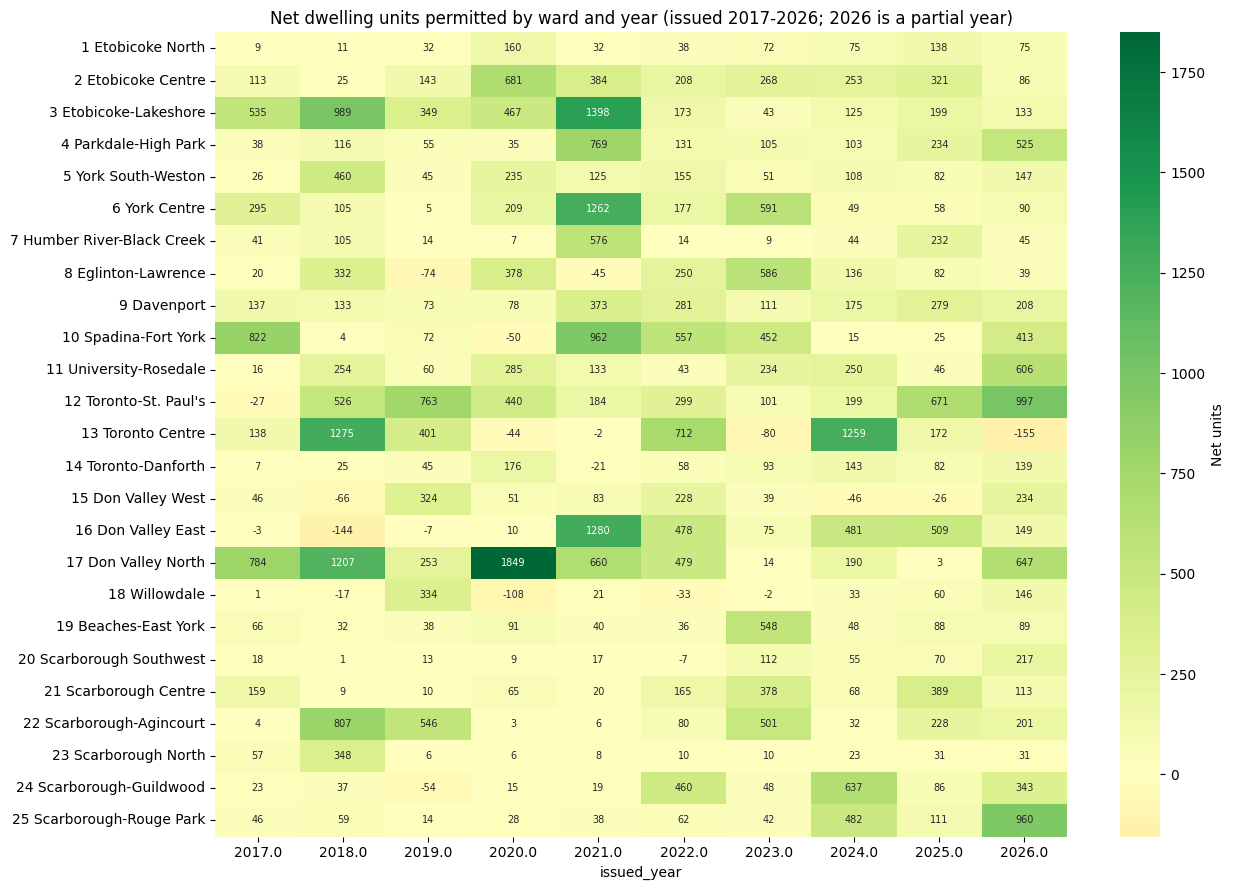

Top 5 wards by net permitted units: 17 Don Valley North (6,086), 3 Etobicoke-Lakeshore (4,411), 12 Toronto-St. Paul's (4,153), 13 Toronto Centre (3,676), 10 Spadina-Fort York (3,272)


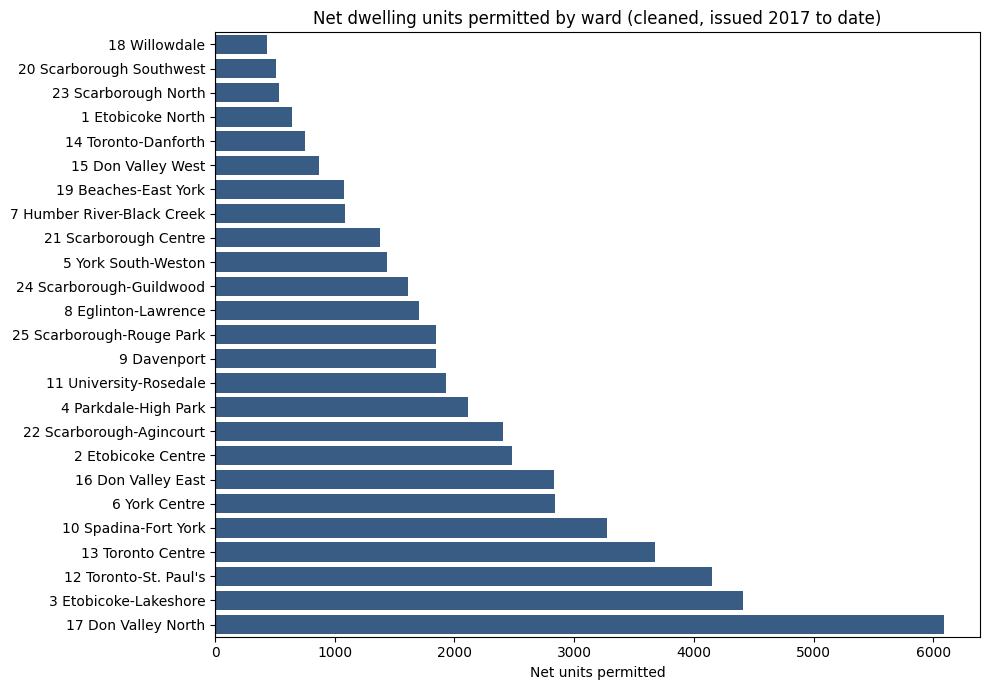

SQL vs pandas ward totals: largest difference 0.0 units (OK)


In [14]:
pm_all = permits[permits["ward_id"].notna()].copy()
pm_all["ward_id"] = pm_all["ward_id"].astype(int)
pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
pm_all["issued_year"] = pm_all["issued_date"].dt.year
pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()      # analysis window
print(f"{len(pm_win):,} permits issued {ANALYSIS_START.year}-{AS_OF.year} have a ward ({len(pm_win)/max(((permits.issued_date>=ANALYSIS_START)&(permits.issued_date<=AS_OF)).sum(),1):.0%} of all permits issued in that window).")

ward_year = pm_win.groupby(["ward_id", "issued_year"])["net_units"].sum().unstack("issued_year").reindex(range(1, 26)).fillna(0)
ward_year.index = [f"{i} {WARD_NAME[i]}" for i in ward_year.index]
plt.figure(figsize=(13, 9))
sns.heatmap(ward_year, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Net units"}, annot_kws={"size": 7})
plt.title(f"Net dwelling units permitted by ward and year (issued {ANALYSIS_START.year}-{AS_OF.year}; {AS_OF.year} is a partial year)")
finish_plot("c2_net_units_heatmap")

ward_net_units = pm_win.groupby("ward_id")["net_units"].sum().reindex(range(1, 26)).fillna(0)
top5 = ward_net_units.sort_values(ascending=False).head(5)
print("Top 5 wards by net permitted units:", ", ".join(f"{i} {WARD_NAME[i]} ({v:,.0f})" for i, v in top5.items()))
plt.figure(figsize=(10, 7))
srt = ward_net_units.sort_values()
sns.barplot(x=srt.values, y=[f"{i} {WARD_NAME[i]}" for i in srt.index], color="#2b5c8f")
plt.axvline(0, color="k", lw=.8); plt.xlabel("Net units permitted"); plt.title("Net dwelling units permitted by ward (cleaned, issued 2017 to date)")
finish_plot("c2_net_units_by_ward")

# --- the same facts straight from the database (checks the SQL layer the KinesisIQ team will use) ---
conn = connect()
sql_total = pd.read_sql_query("SELECT ward_id, SUM(units_created - units_lost) AS net_units FROM fact_permits "
                              "WHERE ward_id IS NOT NULL AND issued_date >= ? AND issued_date <= ? GROUP BY ward_id",
                              conn, params=[str(ANALYSIS_START.date()), str(AS_OF.date()) + " 23:59:59"]).set_index("ward_id")["net_units"]
conn.close()
diff = (sql_total.reindex(range(1, 26)).fillna(0) - ward_net_units).abs().max()
print(f"SQL vs pandas ward totals: largest difference {diff:.1f} units", "(OK)" if diff < 1 else "(CHECK: dates are stored as text, so boundary days may differ)")

## C3. Developer Responsiveness: Approval, Execution and Build Lag
**Population.** Housing permits (`units_created > 0`, outliers removed) issued since 2017 and located in a ward. Approval lag uses permits with both dates; build lag and execution lag use survival estimates so unfinished cases are retained.

**Benchmark.** `excess_median_days` = ward median − best-quartile ward median (only wards with n ≥ 30 set the benchmark).

In [15]:
# ---------- Recreate pm_win from permits if not already defined ----------
try:
    pm_win
except NameError:
    pm_all = permits[permits["ward_id"].notna()].copy()
    pm_all["ward_id"] = pm_all["ward_id"].astype(int)
    pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
    pm_all["issued_year"] = pm_all["issued_date"].dt.year
    pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()

# ---------- Kaplan-Meier (handles unfinished cases) ----------
def km_curve(durations, events):
    d = np.asarray(durations, float); e = np.asarray(events, bool)
    ok = np.isfinite(d) & (d >= 0); d, e = d[ok], e[ok]
    if len(d) == 0 or not e.any():
        return np.array([]), np.array([])
    d_sorted = np.sort(d)
    d_ev = np.sort(d[e])
    t = np.unique(d_ev)
    at_risk = len(d) - np.searchsorted(d_sorted, t, side="left")
    n_ev = np.searchsorted(d_ev, t, side="right") - np.searchsorted(d_ev, t, side="left")
    return t, np.cumprod(1 - n_ev / at_risk)

def km_median(d, e):
    t, S = km_curve(d, e)
    idx = np.where(S <= 0.5)[0] if len(S) else []
    return float(t[idx[0]]) if len(idx) else np.nan

def km_cdf(d, e, t0):
    t, S = km_curve(d, e)
    if len(t) == 0:
        return np.nan
    s = S[t <= t0]
    return float(1 - (s[-1] if len(s) else 1.0))

# ---------- housing permit cohort ----------
hp = pm_win[(pm_win["units_created"] > 0)].copy()
print(f"Housing permits in the analysis window with a ward: {len(hp):,}")

# approval lag (City processing)
def lag_stats(df, col, min_n=30):
    d = df.dropna(subset=[col])
    s = d.groupby("ward_id")[col].agg(n="count", mean="mean", median="median", p75=lambda x: x.quantile(.75), p90=lambda x: x.quantile(.9))
    bench = s.loc[s.n >= min_n, "median"].quantile(.25) if (s.n >= min_n).any() else np.nan
    s["excess_median_days"] = (s["median"] - bench).clip(lower=0) if not np.isnan(bench) else np.nan
    s["excess_permit_days"] = s["excess_median_days"] * s["n"] if not np.isnan(bench) else np.nan
    s.insert(0, "ward_name", s.index.map(WARD_NAME))
    return s.sort_values("median", ascending=False), bench

approval_stats, approval_bench = lag_stats(hp, "approval_lag_days")
write_table(approval_stats.reset_index(), "ward_approval_lag")
print(f"Approval lag benchmark (best-quartile ward median): {approval_bench:.0f} days")

# build lag with censoring: event = completed; unfinished permits are censored at AS_OF
bl = hp[hp["issued_date"].notna()].copy()
bl["done"] = bl["completed_date"].notna() & bl["build_lag_days"].notna()
bl["dur"] = np.where(bl["done"], bl["build_lag_days"], (AS_OF - bl["issued_date"]).dt.days)
bl = bl[bl["dur"] >= 0]
print(f"Build-lag cohort: {len(bl):,} housing permits, {bl.done.mean():.0%} completed so far (the rest are counted as still under way)")

def km_by_ward(df, dur, ev, horizon):
    rows = []
    for w, g_ in df.groupby("ward_id"):
        rows.append({"ward_id": w, "n": len(g_), "completed": int(g_[ev].sum()), "km_median_days": km_median(g_[dur], g_[ev]),
                     f"share_done_within_{horizon}d": km_cdf(g_[dur], g_[ev], horizon)})
    return pd.DataFrame(rows).set_index("ward_id").reindex(range(1, 26))

build_km = km_by_ward(bl, "dur", "done", 1095)
naive_build = bl[bl.done].groupby("ward_id")["dur"].median().reindex(range(1, 26)).rename("median_completed_only")
build_stats = build_km.join(naive_build)
build_stats.insert(0, "ward_name", [WARD_NAME[i] for i in build_stats.index])
write_table(build_stats.reset_index(), "ward_build_lag")
print("\nBuild lag by ward. 'km_median_days' counts unfinished permits; 'median_completed_only' ignores them (and is therefore too short):")
disp(build_stats.sort_values("km_median_days", ascending=False), digits=2)

Housing permits in the analysis window with a ward: 17,556
Approval lag benchmark (best-quartile ward median): 52 days
Build-lag cohort: 17,556 housing permits, 64% completed so far (the rest are counted as still under way)

Build lag by ward. 'km_median_days' counts unfinished permits; 'median_completed_only' ignores them (and is therefore too short):


,ward_name,n,completed,km_median_days,share_done_within_1095d,median_completed_only
ward_id,,,,,,
17,Don Valley North,499,349,2107.0,0.37,1179.0
6,York Centre,971,606,2089.0,0.26,2049.0
5,York South-Weston,823,530,1906.0,0.39,965.5
7,Humber River-Black Creek,400,296,1436.0,0.49,721.0
21,Scarborough Centre,795,495,1393.0,0.46,474.0
3,Etobicoke-Lakeshore,1464,1005,1157.0,0.49,760.0
8,Eglinton-Lawrence,1375,900,1101.0,0.50,706.0
16,Don Valley East,354,166,1044.0,0.51,602.0
2,Etobicoke Centre,886,595,1035.0,0.59,762.0


Execution-lag cohort: 3,548 housing-related applications submitted 2017+; 6.1% matched to a housing permit at the same address.
Matching uses street address, so large multi-address sites can be missed. The result is a lower bound on conversion and is most useful for comparing wards.


,applications,matched,exec_km_median_days,share_permitted_within_3y,ward_name
ward_id,,,,,
10,344,3,NaN,0.00,Spadina-Fort York
9,129,4,NaN,0.01,Davenport
19,86,2,NaN,0.01,Beaches-East York
7,64,4,NaN,0.02,Humber River-Black Creek
13,342,17,NaN,0.02,Toronto Centre
11,234,10,NaN,0.02,University-Rosedale
20,165,3,NaN,0.02,Scarborough Southwest
25,53,7,NaN,0.02,Scarborough-Rouge Park
15,140,6,NaN,0.02,Don Valley West


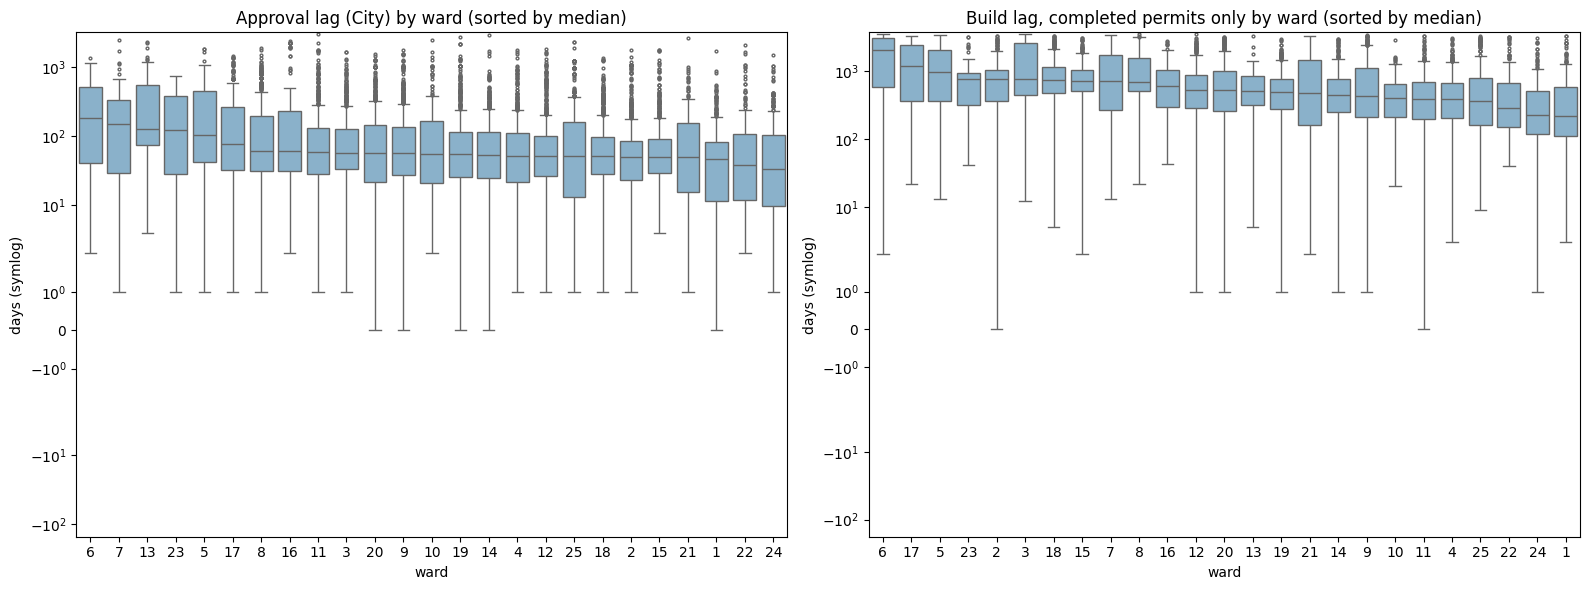

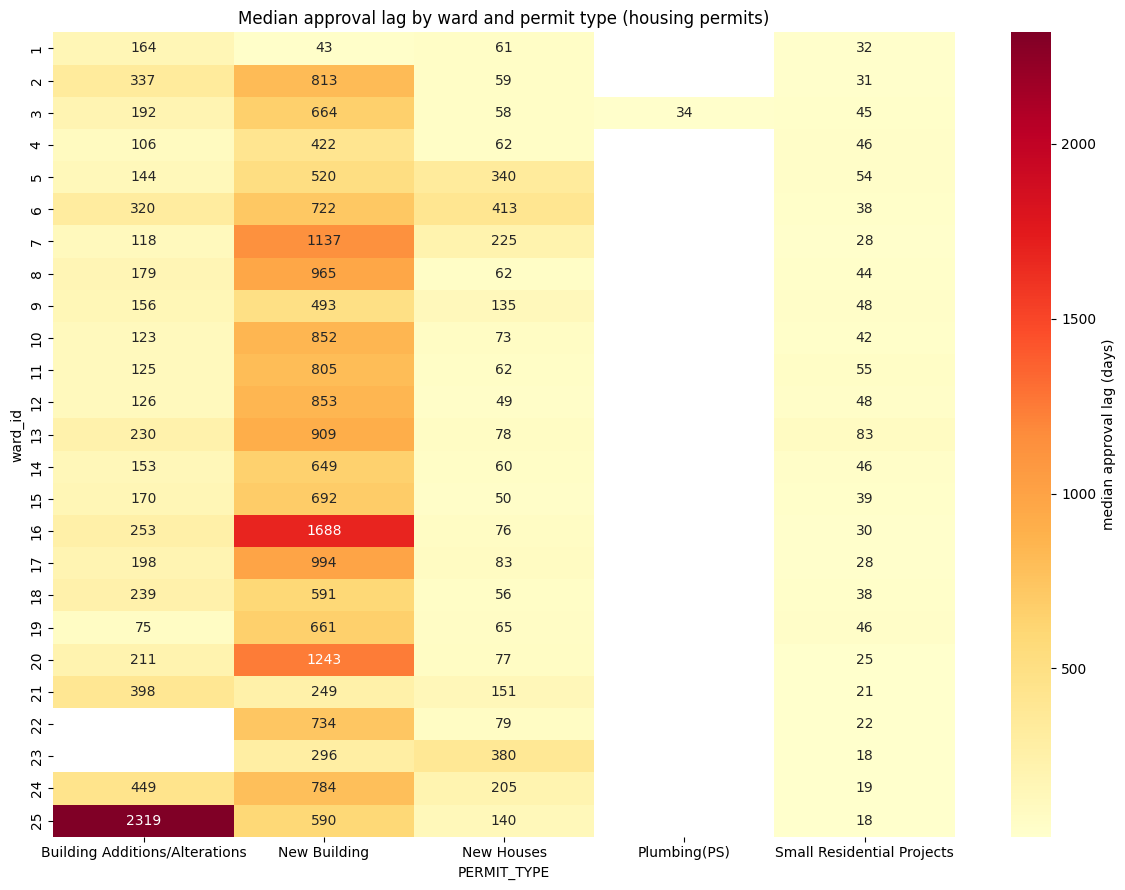

Spearman approval_median_days vs net units permitted (25 wards): rho=0.21, p=0.320
Spearman build_km_median_days vs net units permitted (25 wards): rho=0.28, p=0.173


In [16]:
# ---------- execution lag: Development Application -> first housing building permit at the same address ----------
exec_stats = pd.DataFrame(index=range(1, 26))
if dev["addr_key"].notna().any() and permits["addr_key"].notna().any():
    apps = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF) & dev["ward_id"].notna() & dev["addr_key"].notna()].copy()
    apps["ward_id"] = apps["ward_id"].astype(int)
    perm_h = permits[(permits.units_created > 0) & permits.issued_date.notna() & permits.addr_key.notna()][["addr_key", "issued_date", "ward_id"]]
    j = apps[["_uid", "addr_key", "event_date", "ward_id"]].merge(perm_h.rename(columns={"ward_id": "permit_ward"}), on="addr_key", how="left")
    ok_ward = j["permit_ward"].isna() | j["ward_id"].eq(j["permit_ward"].astype("float"))      # same address text must also be the same ward
    j = j[ok_ward & ((j["issued_date"] >= j["event_date"]) | j["issued_date"].isna())]
    first = j.groupby("_uid")["issued_date"].min()
    apps["first_permit"] = apps["_uid"].map(first)
    apps["matched"] = apps["first_permit"].notna() & ((apps["first_permit"] - apps["event_date"]).dt.days <= MAX_LAG_DAYS)
    apps["dur"] = np.where(apps["matched"], (apps["first_permit"] - apps["event_date"]).dt.days, (AS_OF - apps["event_date"]).dt.days)
    apps = apps[apps["dur"] >= 0]
    print(f"Execution-lag cohort: {len(apps):,} housing-related applications submitted {ANALYSIS_START.year}+; "
          f"{apps.matched.mean():.1%} matched to a housing permit at the same address.")
    print("Matching uses street address, so large multi-address sites can be missed. The result is a lower bound on conversion and is most useful for comparing wards.")
    exec_stats = km_by_ward(apps, "dur", "matched", 1095).rename(columns={"km_median_days": "exec_km_median_days", "share_done_within_1095d": "share_permitted_within_3y",
                                                                           "n": "applications", "completed": "matched"})
    write_table(exec_stats.reset_index(), "ward_execution_lag")
    fact_apps = apps[["_uid", "ward_id", "event_date", "first_permit", "matched", "dur"]]
    write_table(fact_apps, "fact_application_to_permit")
    disp(exec_stats.assign(ward_name=[WARD_NAME[i] for i in exec_stats.index]).sort_values("share_permitted_within_3y"), digits=2)
else:
    print("Execution lag skipped: address keys are missing in applications or permits.")

# ---------- one table of developer-responsiveness measures ----------
resp = pd.DataFrame({"ward_name": pd.Series(WARD_NAME)})
resp = (resp.join(approval_stats[["n", "median", "excess_median_days"]].rename(columns={"n": "approval_n", "median": "approval_median_days", "excess_median_days": "approval_excess_days"}))
            .join(build_stats[["n", "km_median_days", "share_done_within_1095d"]].rename(columns={"n": "build_n", "km_median_days": "build_km_median_days", "share_done_within_1095d": "build_done_3y"}))
            .join(exec_stats))
resp.index.name = "ward_id"
write_table(resp.reset_index(), "ward_developer_responsiveness")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, col, title in ((ax[0], "approval_lag_days", "Approval lag (City)"), (ax[1], "build_lag_days", "Build lag, completed permits only")):
    d = hp.dropna(subset=[col])
    order = d.groupby("ward_id")[col].median().sort_values(ascending=False).index
    sns.boxplot(data=d, x="ward_id", y=col, order=order, color="#7fb3d5", fliersize=2, ax=a)
    a.set_yscale("symlog"); a.set_title(f"{title} by ward (sorted by median)"); a.set_ylabel("days (symlog)"); a.set_xlabel("ward")
finish_plot("c3_lags_by_ward")

top_types = hp["PERMIT_TYPE"].value_counts().head(8).index
piv = hp[hp["PERMIT_TYPE"].isin(top_types)].pivot_table(values="approval_lag_days", index="ward_id", columns="PERMIT_TYPE", aggfunc="median")
if not piv.isna().all().all():
    plt.figure(figsize=(12, 9)); sns.heatmap(piv, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "median approval lag (days)"})
    plt.title("Median approval lag by ward and permit type (housing permits)"); finish_plot("c3_approval_by_type")

# rank correlations (descriptive, n = 25 wards)
cc = resp[["approval_median_days", "build_km_median_days"]].join(ward_net_units.rename("net_units")).dropna()
for col in ("approval_median_days", "build_km_median_days"):
    if len(cc) > 5:
        r, p = stats.spearmanr(cc[col], cc["net_units"])
        print(f"Spearman {col} vs net units permitted ({len(cc)} wards): rho={r:.2f}, p={p:.3f}")


### C3.1 Do Application Volume and Permitted Supply Move Together by Ward? *(exploratory)*
A ward-level regression with **25 observations**, so the result is descriptive only.

- Uses cleaned units and housing-related applications over the same window (2017 to date).
- Works in logarithms, so a coefficient reads as "a 10% higher application count goes with a ___% higher permitted-unit count".
- Uses heteroskedasticity-robust (HC3) standard errors.
- Reports leave-one-out prediction error against an intercept-only baseline, because a model that does not predict held-out wards is not useful however significant its p-value.
- Lists the most influential wards (Cook's distance).

Spearman rank correlation, housing applications vs net permitted units (25 wards): rho = 0.37 (p = 0.0662)


,coef,robust_se,p_value
intercept,4.809,1.232,0.001
log(1 + housing applications),0.435,0.197,0.038
"log(median approval lag, days)",0.128,0.281,0.654


n = 25 wards, R2 = 0.17 (adjusted 0.09).
Leave-one-out mean absolute error on the log scale: model 0.57 vs mean-only baseline 0.60 -> the model predicts held-out wards better than the baseline.
Most influential wards (Cook's distance): 23 Scarborough North (0.18), 18 Willowdale (0.15), 20 Scarborough Southwest (0.07) | a value above 4/n = 0.16 is usually treated as influential.


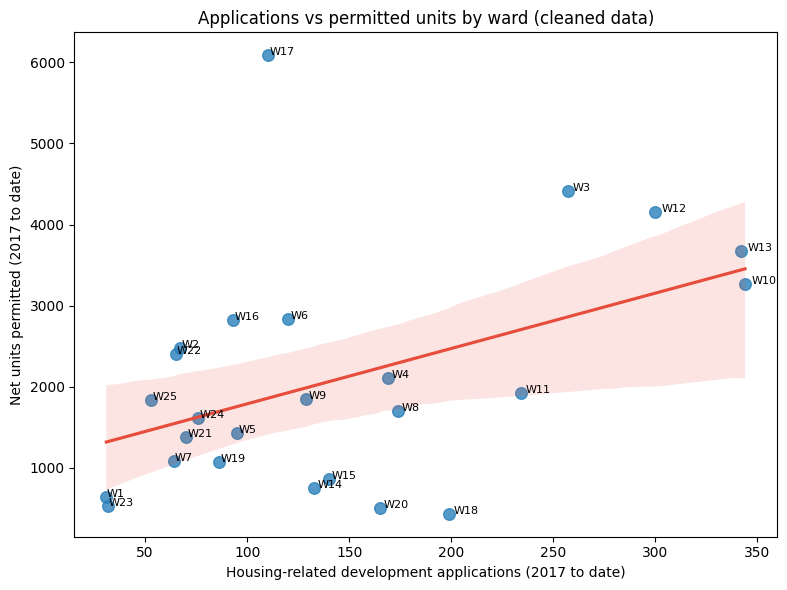

In [17]:
# ---------- Recreate missing variables if not already defined ----------
try:
    ward_net_units
except NameError:
    try:
        pm_win
    except NameError:
        pm_all = permits[permits["ward_id"].notna()].copy()
        pm_all["ward_id"] = pm_all["ward_id"].astype(int)
        pm_all["net_units"] = pm_all["units_created"] - pm_all["units_lost"]
        pm_all["issued_year"] = pm_all["issued_date"].dt.year
        pm_win = pm_all[(pm_all["issued_date"] >= ANALYSIS_START) & (pm_all["issued_date"] <= AS_OF)].copy()
    ward_net_units = pm_win.groupby("ward_id")["net_units"].sum().reindex(range(1, 26)).fillna(0)

try:
    resp
except NameError:
    # Fall back to using a basic DataFrame if the full lag stats from C3 are missing
    resp = pd.DataFrame({"approval_median_days": approval_stats["median"] if 'approval_stats' in locals() else pd.Series(np.nan, index=range(1, 26))}, index=range(1, 26))

def ols_hc3(X, y):
    """OLS with HC3 robust standard errors, leave-one-out residuals and Cook's distance (numpy only)."""
    X = np.column_stack([np.ones(len(y)), np.asarray(X, float)]); y = np.asarray(y, float)
    n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X); b = XtXi @ X.T @ y
    res = y - X @ b
    h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    Xw = X * (res / (1 - h))[:, None]
    cov = XtXi @ (Xw.T @ Xw) @ XtXi
    se = np.sqrt(np.diag(cov)); t = b / se; p = 2 * stats.t.sf(np.abs(t), n - k)
    ss_res, ss_tot = float(res @ res), float(((y - y.mean()) ** 2).sum())
    s2 = ss_res / (n - k)
    return {"coef": b, "se": se, "p": p, "r2": 1 - ss_res / ss_tot, "adj_r2": 1 - (1 - (1 - ss_res / ss_tot)) * (n - 1) / (n - k),
            "loo_resid": res / (1 - h), "cooks": (res ** 2 / (k * s2)) * h / (1 - h) ** 2, "n": n}

apps_ward = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF)].dropna(subset=["ward_id"]).assign(
    ward_id=lambda d: d.ward_id.astype(int)).groupby("ward_id").size().reindex(range(1, 26)).fillna(0).rename("housing_apps")
corr_df = pd.concat([ward_net_units.rename("net_units"), apps_ward, resp["approval_median_days"]], axis=1)
corr_df["ward_name"] = corr_df.index.map(WARD_NAME)
write_table(corr_df.reset_index().rename(columns={"index": "ward_id"}), "ward_supply_vs_applications")

rho, p_rho = stats.spearmanr(corr_df["housing_apps"], corr_df["net_units"])
print(f"Spearman rank correlation, housing applications vs net permitted units ({len(corr_df)} wards): rho = {rho:.2f} (p = {p_rho:.4f})")

md_ = corr_df.dropna(subset=["approval_median_days"])
yv = np.log1p(md_["net_units"].clip(lower=0))
spec = {"log(1 + housing applications)": np.log1p(md_["housing_apps"]), "log(median approval lag, days)": np.log(md_["approval_median_days"].clip(lower=1))}
fit = ols_hc3(np.column_stack(list(spec.values())), yv)
coef = pd.DataFrame({"coef": fit["coef"], "robust_se": fit["se"], "p_value": fit["p"]}, index=["intercept"] + list(spec))
disp(coef, digits=3)
n_ = fit["n"]
loo_model = np.abs(fit["loo_resid"]).mean()
loo_base = np.abs((yv - yv.mean()) * n_ / (n_ - 1)).mean()
print(f"n = {n_} wards, R2 = {fit['r2']:.2f} (adjusted {fit['adj_r2']:.2f}).")
print(f"Leave-one-out mean absolute error on the log scale: model {loo_model:.2f} vs mean-only baseline {loo_base:.2f} "
      f"-> {'the model predicts held-out wards better than the baseline' if loo_model < loo_base else 'NO better than the baseline'}.")
top_inf = pd.Series(fit["cooks"], index=md_.index).sort_values(ascending=False).head(3)
print("Most influential wards (Cook's distance):", ", ".join(f"{i} {WARD_NAME[i]} ({v:.2f})" for i, v in top_inf.items()),
      "| a value above 4/n =", f"{4 / n_:.2f} is usually treated as influential.")

plt.figure(figsize=(8, 6))
sns.regplot(data=corr_df, x="housing_apps", y="net_units", color="#2980b9", scatter_kws={"s": 70, "alpha": .8}, line_kws={"color": "#e74c3c"})
for i, r in corr_df.iterrows():
    plt.text(r["housing_apps"] * 1.01, r["net_units"], f"W{i}", fontsize=8)
plt.xlabel("Housing-related development applications (2017 to date)"); plt.ylabel("Net units permitted (2017 to date)")
plt.title("Applications vs permitted units by ward (cleaned data)"); finish_plot("c31_apps_vs_units")

## C4. Supervised Models

The models are tested on later observations that were not used for fitting. Simple baselines are included so the model is only kept when it adds useful prediction skill.

### C4.1 Permit approval lag

The target is the number of days from application to permit issue for housing permits that were eventually issued. Only issued permits can be observed, so this does not describe applications that are still waiting.

The model uses permit type, structure type, work type, ward, proposed units, estimated cost and application month. The data are split in time order. The latest 20% is kept as the final test set.

The main model is a histogram gradient boosting model on the log-transformed lag. Its MAE is compared with a ward median and a citywide median. The uncertainty interval is calibrated on a separate part of the training period so the final test set is not used for calibration.


Modelling population: 14,601 permits; median approval lag 56 days, 90th percentile 376
Train: applications up to 2024-05-14 (11,680); test: 2024-05-14 to 2025-11-14 (2,921)


,MAE_days,median_abs_error_days,skill_vs_citywide_median_%
Gradient boosting,58.78,34.03,10.17
Ward median (baseline),73.64,44.00,-12.54
Citywide median (baseline),65.43,43.00,0.00


R2 on the log scale: 0.21.
Calibrated 10-90% interval coverage: 80.0% (target 80%).
Calibration value on the log scale: 0.339


,model,citywide_median
year,,
2024,62.30,67.49
2025,56.64,64.18


,increase in log-scale MAE when shuffled
STRUCTURE_TYPE,0.13
WORK,0.09
log_cost,0.06
log_units,0.05
ward_id,0.01
PERMIT_TYPE,0.00
app_month,0.00


Gradient boosting beats the ward-median baseline (58.8 vs 73.6 days MAE).
Most important input: STRUCTURE_TYPE.


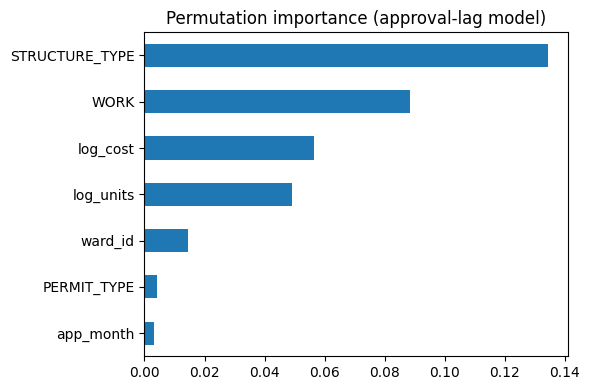

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

lm = permits[(permits.units_created > 0) & permits.app_date.notna() & permits.issued_date.notna() & permits.approval_lag_days.notna()
             & (permits.app_date >= ANALYSIS_START) & (permits.app_date <= AS_OF - pd.Timedelta(days=365))].sort_values("app_date").reset_index(drop=True)
print(f"Modelling population: {len(lm):,} permits; median approval lag {lm.approval_lag_days.median():.0f} days, 90th percentile {lm.approval_lag_days.quantile(.9):.0f}")

split = int(len(lm) * 0.8)
tr, te = lm.iloc[:split].copy(), lm.iloc[split:].copy()
if len(tr) > 150_000:
    tr = tr.sample(150_000, random_state=SEED).sort_values("app_date")
print(f"Train: applications up to {tr.app_date.max().date()} ({len(tr):,}); test: {te.app_date.min().date()} to {te.app_date.max().date()} ({len(te):,})")

# Keep a separate calibration period inside the training data.
cal_split = int(len(tr) * 0.80)
tr_fit = tr.iloc[:cal_split].copy()
cal = tr.iloc[cal_split:].copy()

CAT_COLS = ["PERMIT_TYPE", "STRUCTURE_TYPE", "WORK", "ward_id"]
cat_levels = {}
for c_ in CAT_COLS:
    s_ = tr_fit[c_].astype("object").where(tr_fit[c_].notna(), "missing").astype(str)
    cat_levels[c_] = list(s_.value_counts().head(60).index) + ["other"]

def make_X(df):
    X = pd.DataFrame(index=df.index)
    for c_ in CAT_COLS:
        s_ = df[c_].astype("object").where(df[c_].notna(), "missing").astype(str)
        s_ = s_.where(s_.isin(cat_levels[c_]), "other")
        X[c_] = pd.Categorical(s_, categories=cat_levels[c_])
    X["log_units"] = np.log1p(df["units_created"])
    X["log_cost"] = np.log1p(df["est_cost"].clip(lower=0))
    # units_lost is excluded because it can be updated later in the permit process.
    X["app_month"] = df["app_date"].dt.month
    return X

X_fit, X_cal, X_te = make_X(tr_fit), make_X(cal), make_X(te)
y_fit = np.log1p(tr_fit["approval_lag_days"].to_numpy())
y_cal = np.log1p(cal["approval_lag_days"].to_numpy())
yte = np.log1p(te["approval_lag_days"].to_numpy())

common = dict(categorical_features="from_dtype", max_iter=300, learning_rate=0.08,
              max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0, random_state=SEED)

mdl = HistGradientBoostingRegressor(loss="absolute_error", **common).fit(X_fit, y_fit)
q10 = HistGradientBoostingRegressor(loss="quantile", quantile=0.10, **common).fit(X_fit, y_fit)
q90 = HistGradientBoostingRegressor(loss="quantile", quantile=0.90, **common).fit(X_fit, y_fit)

pred_log = mdl.predict(X_te)
pred_days = np.expm1(pred_log)
true_days = te["approval_lag_days"].to_numpy()

glob_med = float(tr_fit["approval_lag_days"].median())
ward_med = tr_fit.groupby("ward_id")["approval_lag_days"].median()
base_ward = te["ward_id"].map(ward_med).fillna(glob_med).to_numpy(float)

res = pd.DataFrame({
    "MAE_days": [np.abs(true_days - pred_days).mean(),
                  np.abs(true_days - base_ward).mean(),
                  np.abs(true_days - glob_med).mean()],
    "median_abs_error_days": [np.median(np.abs(true_days - pred_days)),
                               np.median(np.abs(true_days - base_ward)),
                               np.median(np.abs(true_days - glob_med))],
}, index=["Gradient boosting", "Ward median (baseline)", "Citywide median (baseline)"])
res["skill_vs_citywide_median_%"] = 100 * (1 - res["MAE_days"] / res.loc["Citywide median (baseline)", "MAE_days"])
disp(res)

# Calibrate the 10-90% interval on data that was not used to fit the models.
cal_lo = q10.predict(X_cal)
cal_hi = q90.predict(X_cal)
scores = np.maximum(cal_lo - y_cal, y_cal - cal_hi)
alpha = 0.20
q_level = min(1.0, np.ceil((len(scores) + 1) * (1 - alpha)) / len(scores))
calibration_q = float(np.quantile(scores, q_level))

lo_log = q10.predict(X_te) - calibration_q
hi_log = q90.predict(X_te) + calibration_q
lo_days = np.expm1(lo_log)
hi_days = np.expm1(hi_log)
cover = float(((yte >= lo_log) & (yte <= hi_log)).mean())

r2_log = 1 - ((yte - pred_log) ** 2).sum() / ((yte - yte.mean()) ** 2).sum()
print(f"R2 on the log scale: {r2_log:.2f}.")
print(f"Calibrated 10-90% interval coverage: {cover:.1%} (target 80%).")
print(f"Calibration value on the log scale: {calibration_q:.3f}")

yr_mae = pd.DataFrame({"year": te["app_date"].dt.year.to_numpy(),
                       "model": np.abs(true_days - pred_days),
                       "citywide_median": np.abs(true_days - glob_med)}).groupby("year").mean()
disp(yr_mae)

samp = np.random.default_rng(SEED).choice(len(X_te), size=min(5000, len(X_te)), replace=False)
pi = permutation_importance(mdl, X_te.iloc[samp], yte[samp], n_repeats=5,
                             random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
disp(imp.rename("increase in log-scale MAE when shuffled").to_frame())

better = res.loc["Gradient boosting", "MAE_days"] < res.loc["Ward median (baseline)", "MAE_days"]
print(f"Gradient boosting {'beats' if better else 'does not beat'} the ward-median baseline "
      f"({res.loc['Gradient boosting','MAE_days']:.1f} vs {res.loc['Ward median (baseline)','MAE_days']:.1f} days MAE).")
print(f"Most important input: {imp.index[0]}.")

write_table(res.reset_index().rename(columns={"index": "model"}), "model_approval_lag_metrics")
interval_metrics = pd.DataFrame({
    "target_coverage": [0.80],
    "test_coverage": [cover],
    "calibration_value_log": [calibration_q]
})
write_table(interval_metrics, "model_approval_lag_interval")

plt.figure(figsize=(6, 4))
imp.sort_values().plot(kind="barh")
plt.title("Permutation importance (approval-lag model)")
finish_plot("c41_approval_lag_importance")


### C4.2 Housing development-application volume

This model predicts housing-related development applications for each ward and quarter, one to four quarters ahead.

It uses recent application counts, seasonal history, recent permit activity, ward and quarter, plus the policy-date flags in Section 0. The model is a Poisson gradient boosting model.

The test is rolling through time. The model is compared with the same quarter last year, the last quarter and the ward's recent four-quarter average. The prediction interval is calibrated from earlier observations because the Poisson interval was too narrow in the first version.


Panel: 25 wards x 39 quarters (2017Q1 to 2026Q3); 3,527 housing applications; 15% of ward-quarters are zero
Rolling-origin back-test, 5 forecast years, 1-4 quarters ahead. Lower error is better.


,MAE_ward_quarter,MAE_city_quarter,city_bias,skill_vs_seasonal_naive_%
method,,,,
ward 4-quarter average,2.50,37.43,22.73,22.08
gradient boosting (Poisson),3.18,55.68,22.81,0.96
seasonal naive (same quarter last year),3.21,51.37,22.87,0.00
last quarter,3.63,60.03,51.83,-13.25


Lowest ward-quarter error: ward 4-quarter average.
Gradient boosting is better than the seasonal-naive baseline.
Calibrated 80% interval coverage across back-tests: 81.0% (target 80%).

City-wide forecast of housing-related development applications (calibrated 80% interval):


,expected_apps,lower80,upper80,approx_p10,approx_p90
quarter,,,,,
2026Q4,87.0,33.0,144.0,33.0,144.0
2027Q1,57.0,14.0,114.0,14.0,114.0
2027Q2,64.0,22.0,122.0,22.0,122.0
2027Q3,69.0,23.0,126.0,23.0,126.0


Wards with the highest expected application volume over the next 4 quarters:


,,expected_apps_4q,indicative_units_4q
ward_id,ward_name,,
12,Toronto-St. Paul's,25.0,9604.0
18,Willowdale,23.0,9580.0
10,Spadina-Fort York,23.0,9078.0
13,Toronto Centre,21.0,10157.0
3,Etobicoke-Lakeshore,17.0,5553.0
8,Eglinton-Lawrence,15.0,4000.0
14,Toronto-Danforth,14.0,781.0
4,Parkdale-High Park,13.0,1709.0



City-wide quarterly housing applications, 8 quarters before vs after each shock (descriptive only):


,event,mean_8q_before,mean_8q_after
0,COVID-19 emergency (Ontario),79.1,127.5
1,Bank of Canada first rate rise,127.5,107.0
2,Bill 23 royal assent (Ontario),162.8,66.4


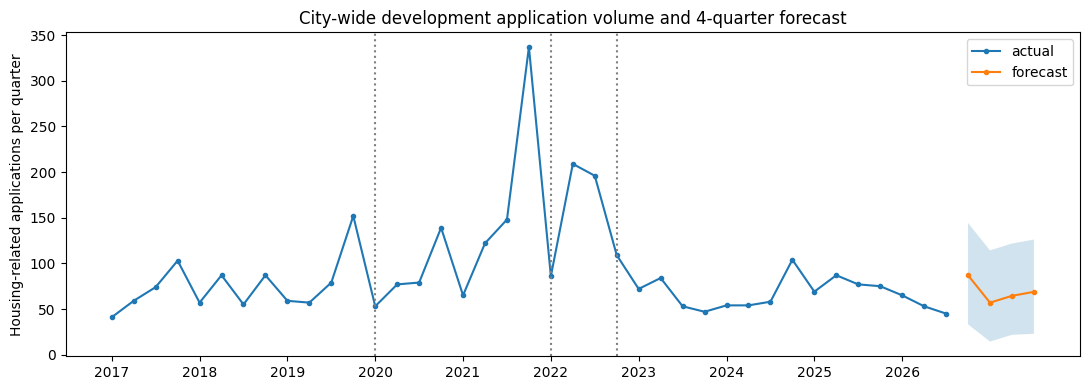

In [19]:
def qidx(ts):
    return ts.dt.year * 4 + ts.dt.quarter - 1

q0 = ANALYSIS_START.year * 4
last_full_q = (AS_OF.year * 4 + AS_OF.quarter - 1) - 1
qgrid = pd.MultiIndex.from_product([range(1, 26), range(q0, last_full_q + 1)], names=["ward_id", "q"])

apps_q = dev[dev["housing_related"] & dev["event_date"].between(ANALYSIS_START, AS_OF) & dev["ward_id"].notna()].copy()
apps_q["q"], apps_q["ward_id"] = qidx(apps_q["event_date"]), apps_q["ward_id"].astype(int)
A = apps_q.groupby(["ward_id", "q"]).size().reindex(qgrid, fill_value=0).unstack("q").to_numpy(float)
perm_q = hp.assign(q=qidx(hp["issued_date"]))
P = perm_q.groupby(["ward_id", "q"]).size().reindex(qgrid, fill_value=0).unstack("q").to_numpy(float)
nq = A.shape[1]
print(f"Panel: 25 wards x {nq} quarters ({ANALYSIS_START.year}Q1 to {(q0 + nq - 1) // 4}Q{(q0 + nq - 1) % 4 + 1}); {A.sum():,.0f} housing applications; {(A == 0).mean():.0%} of ward-quarters are zero")

policy_q = {k: int(pd.Timestamp(v).year * 4 + pd.Timestamp(v).quarter - 1) for k, v in POLICY_EVENTS.items()}
WARD_CATS = list(range(1, 26))

def feats(o, h):
    t = o + h
    X = pd.DataFrame({"ward_id": pd.Categorical(WARD_CATS, categories=WARD_CATS), "h": h,
                      "lag0": A[:, o], "mean4": A[:, max(0, o - 3):o + 1].mean(1), "mean8": A[:, max(0, o - 7):o + 1].mean(1),
                      "same_q_last_year": A[:, t - 4] if 0 <= t - 4 <= o else np.nan,
                      "ward_mean_all": A[:, :o + 1].mean(1), "city_last4": A[:, max(0, o - 3):o + 1].sum(),
                      "permits_mean4": P[:, max(0, o - 3):o + 1].mean(1), "quarter_of_year": (q0 + t) % 4})
    for k, pq in policy_q.items():
        X["after_" + re.sub(r"\W+", "_", k)[:20]] = int(q0 + t >= pq)
    return X

def build(origins, hs, with_target=True):
    parts, ys = [], []
    for o in origins:
        for h in hs:
            if with_target and o + h > nq - 1:
                continue
            f_ = feats(o, h)
            f_["_o"], f_["_t"] = o, o + h
            parts.append(f_)
            if with_target:
                ys.append(A[:, o + h])
    X = pd.concat(parts, ignore_index=True)
    return X, (np.concatenate(ys) if with_target else None)

def fit_hgb(X, y):
    return HistGradientBoostingRegressor(loss="poisson", categorical_features="from_dtype",
                                         max_iter=200, learning_rate=0.05,
                                         min_samples_leaf=20, l2_regularization=1.0,
                                         random_state=SEED).fit(X.drop(columns=["_o", "_t"]), y)

def conformal_count_interval(model, X_fit, y_fit, X_cal, y_cal, X_test, alpha=0.20):
    pred_cal = np.clip(model.predict(X_cal.drop(columns=["_o", "_t"])), 0, None)
    scores = np.abs(y_cal - pred_cal)
    level = min(1.0, np.ceil((len(scores) + 1) * (1 - alpha)) / len(scores))
    q = float(np.quantile(scores, level))
    pred_test = np.clip(model.predict(X_test.drop(columns=["_o", "_t"])), 0, None)
    lo = np.maximum(0, pred_test - q)
    hi = pred_test + q
    return pred_test, lo, hi, q

rows_bt, cover_bt = [], []
last_year_full = (q0 + nq - 1) // 4
for cy in range(2021, last_year_full + 1):
    c = cy * 4 + 3 - q0
    if c + 1 > nq - 1:
        continue
    Xtr_, ytr_ = build(range(7, c), range(1, 5))
    keep_ = Xtr_["_t"] <= c
    Xtr_, ytr_ = Xtr_[keep_].reset_index(drop=True), ytr_[keep_.to_numpy()]
    Xte_, yte_ = build([c], range(1, 5))
    if len(Xte_) == 0:
        continue

    # Last 20% of the training observations is used for interval calibration.
    cal_n = max(1, int(len(Xtr_) * 0.20))
    Xfit_, Xcal_ = Xtr_.iloc[:-cal_n].copy(), Xtr_.iloc[-cal_n:].copy()
    yfit_, ycal_ = ytr_[:-cal_n], ytr_[-cal_n:]
    model_q = fit_hgb(Xfit_, yfit_)
    mu, lo_, hi_, q_ = conformal_count_interval(model_q, Xfit_, yfit_, Xcal_, ycal_, Xte_)

    base = {
        "seasonal naive (same quarter last year)": Xte_["same_q_last_year"].to_numpy(),
        "last quarter": Xte_["lag0"].to_numpy(),
        "ward 4-quarter average": Xte_["mean4"].to_numpy(),
        "gradient boosting (Poisson)": mu
    }
    for name, p_ in base.items():
        tot = pd.DataFrame({"t": Xte_["_t"], "p": p_, "a": yte_}).groupby("t").sum()
        rows_bt.append({"cutoff_year": cy, "method": name,
                        "MAE_ward_quarter": np.nanmean(np.abs(p_ - yte_)),
                        "MAE_city_quarter": (tot["p"] - tot["a"]).abs().mean(),
                        "city_bias": (tot["p"] - tot["a"]).mean()})
    cover_bt.append(float(((yte_ >= lo_) & (yte_ <= hi_)).mean()))

btq = pd.DataFrame(rows_bt)
btq_sum = btq.groupby("method")[["MAE_ward_quarter", "MAE_city_quarter", "city_bias"]].mean().sort_values("MAE_ward_quarter")
btq_sum["skill_vs_seasonal_naive_%"] = 100 * (1 - btq_sum["MAE_ward_quarter"] / btq_sum.loc["seasonal naive (same quarter last year)", "MAE_ward_quarter"])
print(f"Rolling-origin back-test, {btq.cutoff_year.nunique()} forecast years, 1-4 quarters ahead. Lower error is better.")
disp(btq_sum)
write_table(btq_sum.reset_index(), "backtest_dev_applications")
champ_q = btq_sum.index[0]
print(f"Lowest ward-quarter error: {champ_q}.")
print(f"Gradient boosting is {'better' if btq_sum.loc['gradient boosting (Poisson)', 'MAE_ward_quarter'] < btq_sum.loc['seasonal naive (same quarter last year)', 'MAE_ward_quarter'] else 'not better'} than the seasonal-naive baseline.")
print(f"Calibrated 80% interval coverage across back-tests: {np.mean(cover_bt):.1%} (target 80%).")

# Forecast the next four quarters using all available history.
Xall, yall = build(range(7, nq), range(1, 5))
cal_n = max(1, int(len(Xall) * 0.20))
Xfit_all, Xcal_all = Xall.iloc[:-cal_n].copy(), Xall.iloc[-cal_n:].copy()
yfit_all, ycal_all = yall[:-cal_n], yall[-cal_n:]
model_final = fit_hgb(Xfit_all, yfit_all)
Xf = pd.concat([feats(nq - 1, h).assign(_o=nq - 1, _t=nq - 1 + h) for h in range(1, 5)], ignore_index=True)
muf, lo_f, hi_f, final_q = conformal_count_interval(model_final, Xfit_all, yfit_all, Xcal_all, ycal_all, Xf)

fq = pd.DataFrame({"ward_id": Xf["ward_id"].astype(int),
                   "quarter": [f"{(q0 + t) // 4}Q{(q0 + t) % 4 + 1}" for t in Xf["_t"]],
                   "horizon_q": Xf["h"], "expected_apps": muf,
                   "lower80": lo_f, "upper80": hi_f,
                   "p10": lo_f, "p90": hi_f})
fq["ward_name"] = fq["ward_id"].map(WARD_NAME)
med_units = apps_q.groupby("ward_id")["units_parsed"].agg(["median", "count"])
fq["median_units_parsed_ward"] = fq["ward_id"].map(med_units["median"].where(med_units["count"] >= 10))
fq["indicative_units"] = fq["expected_apps"] * fq["median_units_parsed_ward"]
write_table(fq, "forecast_dev_applications")

city_fq = fq.groupby("quarter").agg(expected_apps=("expected_apps", "sum"), lower80=("lower80", "sum"), upper80=("upper80", "sum"))
city_fq["approx_p10"], city_fq["approx_p90"] = city_fq["lower80"], city_fq["upper80"]
print("\nCity-wide forecast of housing-related development applications (calibrated 80% interval):")
disp(city_fq, digits=0)
print("Wards with the highest expected application volume over the next 4 quarters:")
disp(fq.groupby(["ward_id", "ward_name"]).agg(expected_apps_4q=("expected_apps", "sum"), indicative_units_4q=("indicative_units", "sum")).sort_values("expected_apps_4q", ascending=False).head(8), digits=0)

city_series = A.sum(0)
ev_rows = []
for k, pq in policy_q.items():
    pos = pq - q0
    if 8 <= pos <= nq - 9:
        ev_rows.append({"event": k, "mean_8q_before": city_series[pos - 8:pos].mean(), "mean_8q_after": city_series[pos:pos + 8].mean()})
if ev_rows:
    print("\nCity-wide quarterly housing applications, 8 quarters before vs after each shock (descriptive only):")
    disp(pd.DataFrame(ev_rows), digits=1)

fig, ax = plt.subplots(figsize=(11, 4))
qlab = [q0 + i for i in range(nq)]
ax.plot(qlab, city_series, marker="o", ms=3, label="actual")
fut_x = [nq - 1 + h + q0 for h in range(1, 5)]
ax.plot(fut_x, city_fq["expected_apps"].values, marker="o", ms=3, label="forecast")
ax.fill_between(fut_x, city_fq["lower80"].values, city_fq["upper80"].values, alpha=.2)
for k, pq in policy_q.items():
    ax.axvline(pq, color="grey", ls=":")
ax.set_xticks(qlab[::4]); ax.set_xticklabels([f"{x // 4}" for x in qlab[::4]])
ax.set_ylabel("Housing-related applications per quarter")
ax.set_title("City-wide development application volume and 4-quarter forecast")
ax.legend()
finish_plot("c42_dev_application_forecast")


## C5. Maps
Choropleth maps use the ward and neighbourhood reference layers. Wards with no value are shown in grey, not as zero.

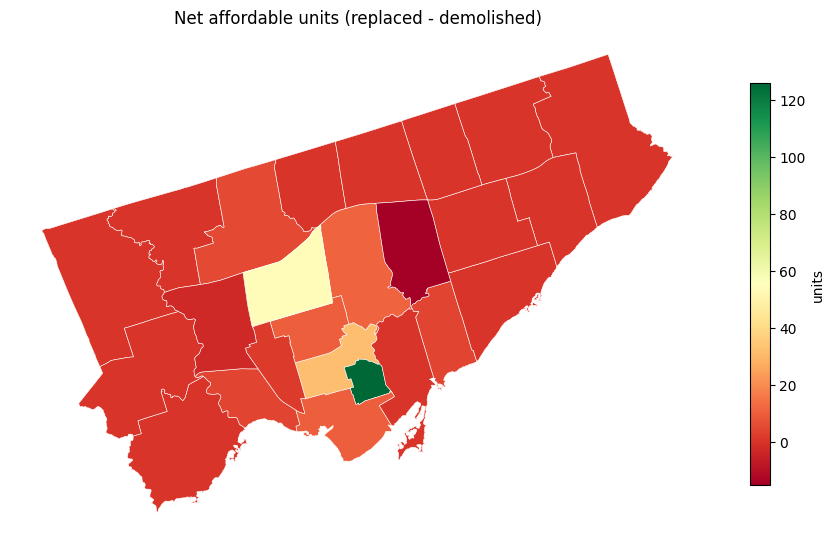

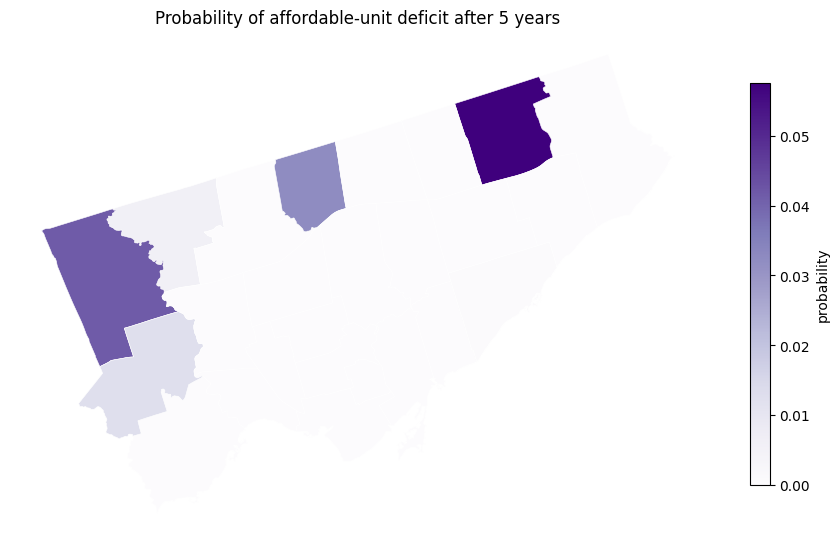

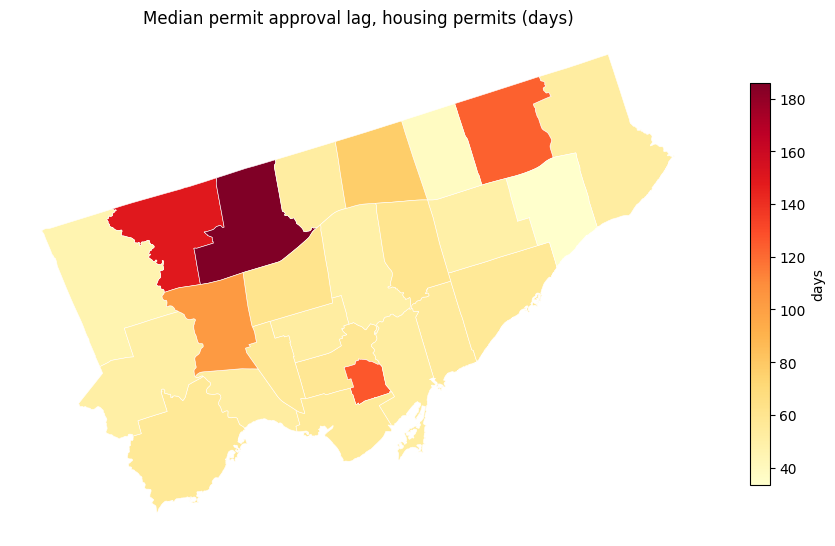

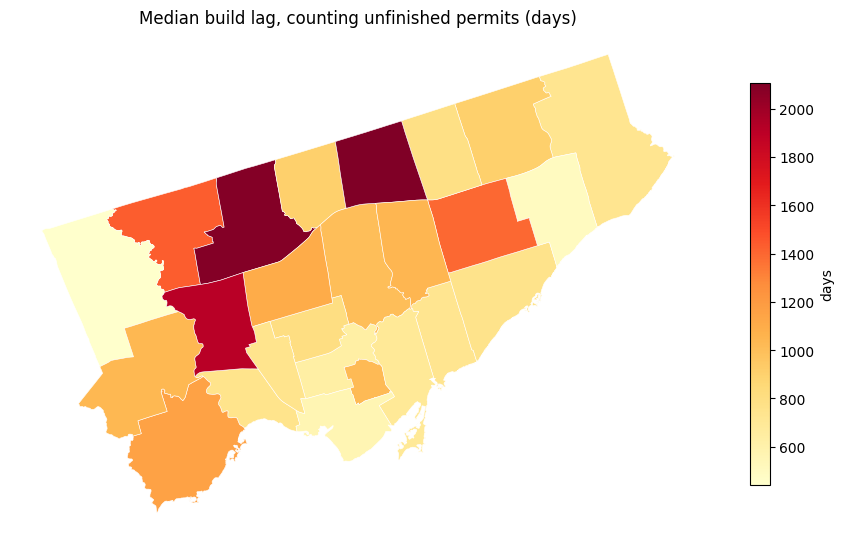

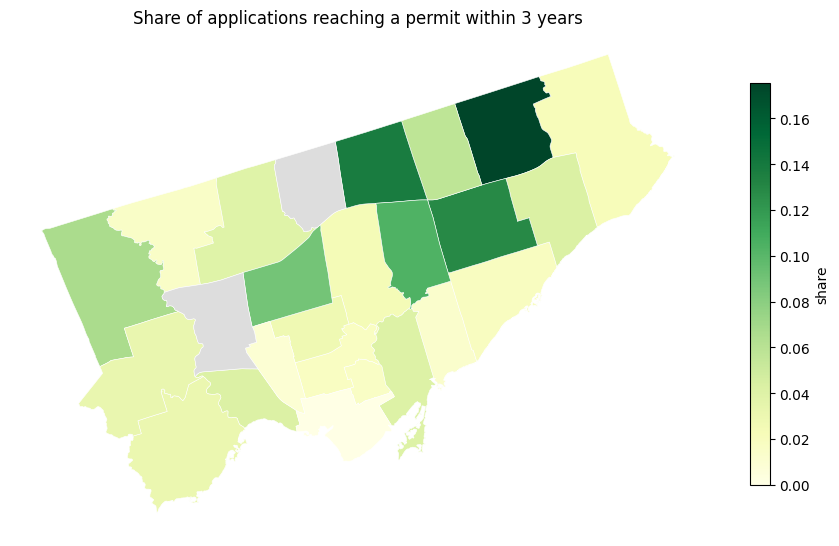

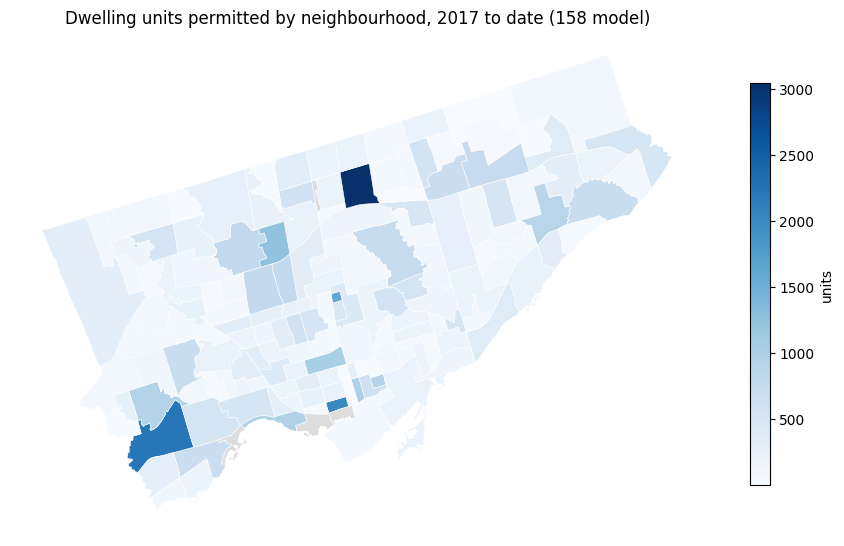

In [20]:
def choropleth(gdf, values, key, title, cmap="YlOrRd", label="", name=None):
    m_ = gdf.merge(values.rename("value").reset_index().rename(columns={values.index.name or "index": key}), on=key, how="left")
    ax = m_.plot(column="value", cmap=cmap, legend=True, figsize=(9, 7), edgecolor="white", linewidth=.4,
                 missing_kwds={"color": "#dddddd"}, legend_kwds={"label": label, "shrink": .6})
    ax.set_title(title); ax.axis("off")
    finish_plot(name or re.sub(r"\W+", "_", title.lower())[:40])

if HAS_GPD and wards_gdf is not None:
    if "net_affordable_change" in wd:
        choropleth(wards_gdf, wd["net_affordable_change"].rename_axis("ward_id"), "ward_id", "Net affordable units (replaced - demolished)", cmap="RdYlGn", label="units", name="map_net_affordable")
    if "p_deficit" in f5.columns:
        choropleth(wards_gdf, f5.set_index("ward_id")["p_deficit"].rename_axis("ward_id"), "ward_id", f"Probability of affordable-unit deficit after {FORECAST_YEARS} years", cmap="Purples", label="probability", name="map_p_deficit")
    if "approval_median_days" in resp:
        choropleth(wards_gdf, resp["approval_median_days"].rename_axis("ward_id"), "ward_id", "Median permit approval lag, housing permits (days)", label="days", name="map_approval_lag")
    if "build_km_median_days" in resp:
        choropleth(wards_gdf, resp["build_km_median_days"].rename_axis("ward_id"), "ward_id", "Median build lag, counting unfinished permits (days)", label="days", name="map_build_lag")
    if "share_permitted_within_3y" in resp:
        choropleth(wards_gdf, resp["share_permitted_within_3y"].rename_axis("ward_id"), "ward_id", "Share of applications reaching a permit within 3 years", cmap="YlGn", label="share", name="map_execution")
else:
    print("Ward geometry unavailable - ward maps skipped.")

if HAS_GPD and nbhd_gdf is not None:
    nb_units = hp.dropna(subset=["neighbourhood_id"]).assign(neighbourhood_id=lambda d: d.neighbourhood_id.astype(int)).groupby("neighbourhood_id")["units_created"].sum()
    choropleth(nbhd_gdf, nb_units, "neighbourhood_id", "Dwelling units permitted by neighbourhood, 2017 to date (158 model)", cmap="Blues", label="units", name="map_neighbourhood_units")
    write_table(nb_units.rename("units_permitted").reset_index(), "neighbourhood_units_permitted")
else:
    print("Neighbourhood geometry unavailable - neighbourhood map skipped.")

## D. ETL Validation
The checks below run on the tables just written to the database.

| Status | Meaning |
|---|---|
| **PASS** | Check satisfied |
| **WARN** | Known limitation; mention it when presenting |
| **FAIL** (critical) | A later result should not be trusted until this is fixed |

In [21]:
CHECKS = []
def check(name, passed, detail, critical=True):
    CHECKS.append({"check": name, "result": "PASS" if passed else ("FAIL" if critical else "WARN"), "detail": detail})

conn = connect()
evdb = pd.read_sql_query("SELECT event_id, event_type, event_date, ward_id, units_affected, units_affordable, units_lost, source_dataset FROM kinesis_events", conn)
wards_db = set(pd.read_sql_query("SELECT ward_id FROM dim_ward", conn)["ward_id"])
tables_db = set(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"])
counts_db = evdb.groupby("source_dataset").size().to_dict()
conn.close()

# 1. one copy of every table: business keys are unique
check("Demolition rows unique", demo["_uid"].is_unique and len(demo) == demo_raw["_uid"].nunique(), f"{len(demo)} rows")
pid_col = pick_col(pipe, r"^Project ID")
check("Pipeline: one row per Project ID", pipe[pid_col].is_unique if pid_col else True, f"{len(pipe)} projects")
folder_col = pick_col(dev, r"FOLDERRSN")
check("Development applications: one row per FOLDERRSN", dev[folder_col].is_unique if folder_col else True, f"{len(dev):,} applications")
check("Permits: one row per PERMIT_NUM", permits["PERMIT_NUM"].is_unique, f"{len(permits):,} permits")
rsn_col = pick_col(latest, r"^RSN$")
check("RentSafeTO: one row per building", latest[rsn_col].is_unique, f"{len(latest):,} buildings")

# 2. nothing silently overwritten when events were written (INSERT OR REPLACE would hide duplicate event_ids)
expected = {"Demolition and Replacement of Rental Housing Units": len(ev_demo), "Development Applications": len(ev_dev),
            **{k: len(v) for k, v in ev_parts.items()}}
lost_ev = {k: (v, counts_db.get(k, 0)) for k, v in expected.items() if counts_db.get(k, 0) != v}
check("Event IDs unique (rows written = rows stored)", not lost_ev, "all sources match" if not lost_ev else f"mismatch (written, stored): {lost_ev}")

# 3. referential integrity and ranges
ward_vals = set(evdb["ward_id"].dropna().astype(int))
check("Every event ward_id exists in dim_ward", ward_vals <= wards_db, f"{len(ward_vals)} distinct wards in events")
dts = pd.to_datetime(evdb["event_date"], errors="coerce")
check("Event dates parse and fall in 1990 .. AS_OF + 1 year", dts.notna().all() and dts.min() >= pd.Timestamp("1990-01-01") and dts.max() <= AS_OF + pd.DateOffset(years=1),
      f"{dts.min().date()} to {dts.max().date()}; unparseable: {int(dts.isna().sum())}")
check("No negative unit counts in events", (evdb[["units_affected", "units_affordable", "units_lost"]] >= 0).all().all(), "")
check("No single permit above the unit limit remains", bool((permits["units_created"] < MAX_UNITS_PER_PERMIT).all()),
      f"{int(permits.units_outlier.sum())} permits had their units zeroed")

# 4. totals reconcile after the ward breakdown
check("Ward totals = dataset totals (demolition)", abs(wd.aff_demolished.sum() - demo.loc[demo.ward_id.notna(), "dem_aff"].sum()) < 1e-6,
      f"{wd.aff_demolished.sum():,.0f} affordable units")
check("Ward totals = dataset totals (pipeline, not completed)", abs(wd.pipeline_units.sum() - fut.loc[fut.ward_id.notna(), "units"].sum()) < 1e-6,
      f"{wd.pipeline_units.sum():,.0f} units")

# 5. geography
for r_ in GEO_LOG:
    check(f"Spatial vs source ward agreement >= 95% ({r_['dataset']})", r_["agreement"] >= 0.95, f"{r_['agreement']:.1%} on {r_['rows_compared']:,} rows", critical=False)
for d_ in DQ:
    if pd.notna(d_["pct_ward_unmapped"]):
        lim = 0.30 if "Permits" in d_["dataset"] else 0.05
        check(f"Ward unmapped <= {lim:.0%} ({d_['dataset']})", d_["pct_ward_unmapped"] <= lim, f"{d_['pct_ward_unmapped']:.1%} unmapped", critical=False)
perm_gm = permits["geo_method"].value_counts(normalize=True)
check("Permits: share placed by point-in-polygon or tested lookup", perm_gm.get("unmapped", 0) < 0.5, ", ".join(f"{k} {v:.0%}" for k, v in perm_gm.items()))

# 6. tables exist and are not empty
conn = connect()
for t_ in ["fact_demolition_replacement", "fact_affordable_stock_city", "fact_affordable_pipeline", "fact_rentsafe", "fact_dev_applications", "fact_permits"]:
    n_ = pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {t_}", conn)["n"][0] if t_ in tables_db else 0
    check(f"Table {t_} has rows", n_ > 0, f"{n_:,} rows")
conn.close()

chk = pd.DataFrame(CHECKS)
disp(chk)
print("\nData-quality log:"); disp(pd.DataFrame(DQ), digits=3)
n_fail = int((chk.result == "FAIL").sum()); n_warn = int((chk.result == "WARN").sum())
print(f"\n{(chk.result == 'PASS').sum()} passed, {n_warn} warnings, {n_fail} failures.")


,check,result,detail
0,Demolition rows unique,PASS,173 rows
1,Pipeline: one row per Project ID,PASS,277 projects
2,Development applications: one row per FOLDERRSN,PASS,"8,639 applications"
3,Permits: one row per PERMIT_NUM,PASS,"998,338 permits"
4,RentSafeTO: one row per building,PASS,"3,611 buildings"
5,Event IDs unique (rows written = rows stored),PASS,all sources match
6,Every event ward_id exists in dim_ward,PASS,25 distinct wards in events
7,Event dates parse and fall in 1990 .. AS_OF + ...,PASS,1990-01-04 to 2026-11-13; unparseable: 0
8,No negative unit counts in events,PASS,
9,No single permit above the unit limit remains,PASS,2 permits had their units zeroed



Data-quality log:


,dataset,rows_loaded,events_written,pct_ward_unmapped,note
0,Demolition & Replacement,173,173,0.000,112 rows dated by council approval (no permit ...
1,Active Affordable & Social Housing,27,0,NaN,city-wide quarterly series; no ward or address...
2,Affordable Rental Housing Pipeline,277,0,0.000,"snapshot with no dates -> fact table only, no ..."
3,RentSafeTO Evaluation,18917,0,0.000,building-level table (latest evaluation per bu...
4,Development Applications,26455,8639,0.001,units parsed from text for 43% of rows (indica...
5,Building Permits - Active,172552,11011,0.002,housing-relevant permits with an issue date
6,Building Permits - Cleared,825786,57263,0.015,housing-relevant permits with an issue date



27 passed, 1 warnings, 0 failures.


## E. Unsupervised View — Ward Typology
Groups the 25 wards by depletion profile (demolition, pipeline and building-condition measures) and developer behaviour (lags, application volume and permitted units).

- Features that are empty for some wards are dropped rather than filled.
- Counts are signed-log transformed and every feature is standardised.
- *k* is chosen by silhouette score (2–6).
- **Stability** is tested by re-clustering 200 random 80% subsets of wards and comparing with the full-data clusters using the Adjusted Rand Index (1 = identical, near 0 = unrelated).

With only 25 wards this is a descriptive grouping, not a validated segmentation.

Silhouette by k: {2: 0.165, 3: 0.245, 4: 0.283, 5: 0.254, 6: 0.246} -> k = 4
Stability: mean Adjusted Rand Index 0.59 (5th percentile 0.27) over 200 random 80% subsets of wards. Clusters are NOT stable: treat the grouping as illustrative only.


,wards,relative_to_other_wards,aff_demolished,net_affordable_change,pipeline_expected_5y,pct_buildings_watch,approval_median_days,build_km_median_days,housing_apps,net_units_permitted
cluster,,,,,,,,,,
0,"2, 3, 4, 8, 9, 10, 11, 12, 13, 14, 15, 18, 19,...",near the city average on every feature,225.1,16.9,496.3,0.1,58.3,847.2,186.9,2108.1
1,"5, 6, 7, 16, 17","high: approval_median_days, build_km_median_da...",187.0,-2.6,754.8,0.1,115.2,1716.4,96.4,2855.2
2,"21, 24, 25",high: pct_buildings_watch; low: aff_demolished...,0.0,0.0,489.4,0.3,45.2,875.7,66.3,1610.7
3,"1, 23","low: aff_demolished, pipeline_expected_5y, pct...",0.0,0.0,7.2,0.0,84.5,675.5,31.5,586.0


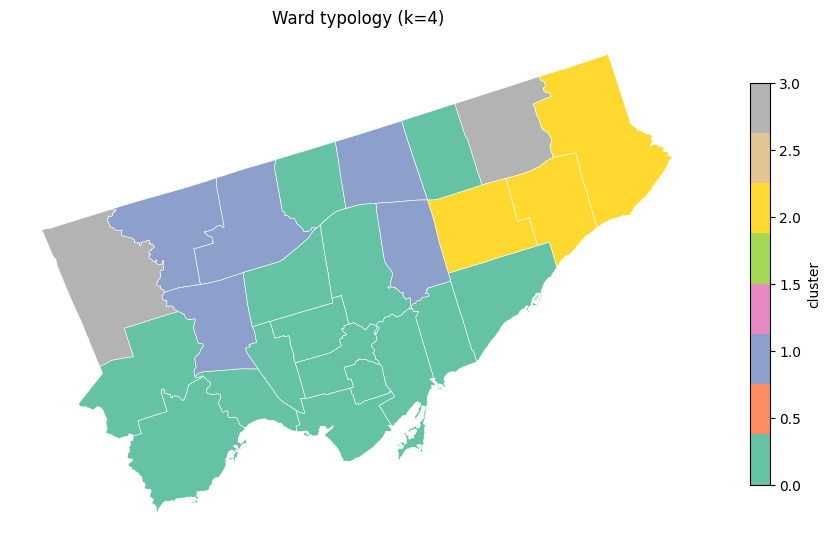

In [22]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Safely collect available features to avoid KeyErrors
feats_dict = {}
if "aff_demolished" in wd.columns: feats_dict["aff_demolished"] = wd["aff_demolished"]
if "net_affordable_change" in wd.columns: feats_dict["net_affordable_change"] = wd["net_affordable_change"]
if "pipeline_expected_5y" in wd.columns: feats_dict["pipeline_expected_5y"] = wd["pipeline_expected_5y"]
if "pct_buildings_watch" in wd.columns: feats_dict["pct_buildings_watch"] = wd["pct_buildings_watch"]
if "approval_median_days" in resp.columns: feats_dict["approval_median_days"] = resp["approval_median_days"]
if "build_km_median_days" in resp.columns: feats_dict["build_km_median_days"] = resp["build_km_median_days"]
if "housing_apps" in corr_df.columns: feats_dict["housing_apps"] = corr_df["housing_apps"]
if "net_units_permitted" in locals() or "ward_net_units" in locals(): feats_dict["net_units_permitted"] = ward_net_units

feat = pd.DataFrame(feats_dict).reindex(range(1, 26))
empty_cols = feat.columns[feat.isna().any()].tolist()
if empty_cols:
    print("Dropped (empty for some wards, not filled):", empty_cols)
    feat = feat.drop(columns=empty_cols)
const_cols = feat.columns[feat.nunique() <= 1].tolist()
if const_cols:
    print("Dropped (identical in every ward):", const_cols); feat = feat.drop(columns=const_cols)

slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
count_like = [c_ for c_ in ("aff_demolished", "net_affordable_change", "pipeline_expected_5y", "housing_apps", "net_units_permitted") if c_ in feat]
Zdf = feat.copy()
for c_ in count_like:
    Zdf[c_] = slog(Zdf[c_])
Z = StandardScaler().fit_transform(Zdf)

scores = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in range(2, 7)}
best_k = max(scores, key=scores.get)
print("Silhouette by k:", {k: round(float(v), 3) for k, v in scores.items()}, "-> k =", best_k)
full = KMeans(best_k, n_init=20, random_state=SEED).fit_predict(Z)
rng_ = np.random.default_rng(SEED); aris = []
for _ in range(200):
    idx = rng_.choice(25, size=20, replace=False)
    sub = KMeans(best_k, n_init=10, random_state=int(rng_.integers(1_000_000))).fit_predict(Z[idx])
    aris.append(adjusted_rand_score(full[idx], sub))
print(f"Stability: mean Adjusted Rand Index {np.mean(aris):.2f} (5th percentile {np.percentile(aris, 5):.2f}) over 200 random 80% subsets of wards. "
      f"{'Clusters are reasonably stable.' if np.mean(aris) >= 0.7 else 'Clusters are NOT stable: treat the grouping as illustrative only.'}")
feat["cluster"] = full
zscores = pd.DataFrame(Z, index=feat.index, columns=Zdf.columns).groupby(full).mean()
def describe_cluster(k):
    hi = [c_ for c_ in zscores.columns if zscores.loc[k, c_] > .75]; lo = [c_ for c_ in zscores.columns if zscores.loc[k, c_] < -.75]
    return ("high: " + ", ".join(hi) if hi else "") + ("; " if hi and lo else "") + ("low: " + ", ".join(lo) if lo else "") or "near the city average on every feature"
profile = feat.groupby("cluster").mean().round(1)
profile.insert(0, "wards", feat.groupby("cluster").apply(lambda d: ", ".join(map(str, d.index)), include_groups=False))
profile.insert(1, "relative_to_other_wards", [describe_cluster(k) for k in profile.index])
write_table(feat.reset_index().rename(columns={"index": "ward_id"}), "ward_clusters")
disp(profile)
if HAS_GPD and wards_gdf is not None:
    choropleth(wards_gdf, feat["cluster"].astype(float).rename_axis("ward_id"), "ward_id", f"Ward typology (k={best_k})", cmap="Set2", label="cluster", name="map_typology")

## F. Findings, Limitations and Decisions
Every number in the findings below is produced by the code above, so it updates when the notebook is re-run.

In [23]:
def fmt(x, d=0):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:,.{d}f}"

c5 = fc_city[fc_city.horizon_years == FORECAST_YEARS].iloc[0]
topdef = f5.sort_values(["p_deficit", "net_flow_p50"], ascending=[False, True]).head(5)
findings = []
findings.append(f"**Demolition and replacement.** {len(demo)} rental demolition applications since 2017 put {demo.dem_aff.sum():,.0f} affordable rental homes at risk; {demo.rep_aff.sum():,.0f} are slated for replacement (net {demo.net_affordable_change.sum():+,.0f}). Replacement is a commitment and does not mean the replacement homes already exist.")
findings.append(f"**Protected stock.** {fmt(STOCK_LATEST)} affordable units were reported for {STOCK_LATEST_Q}. This is a city-wide series, so it is not used as a ward denominator. The fitted trend is {fmt(STOCK_TREND_PER_YEAR)} units per year.")
findings.append(f"**Pipeline.** {fut.units.sum():,.0f} affordable units are in projects that are not yet complete. Under the base delivery assumptions about {fut[f'expected_units_{FORECAST_YEARS}y'].sum():,.0f} arrive within {FORECAST_YEARS} years. The low and high scenarios show how much this result changes when the delivery assumptions are changed.")
findings.append(f"**Affordable-loss forecast.** The best back-tested method was {champion}. It {'beats' if champ_mae < zero_mae else 'does not beat'} the predict-zero baseline (MAE {champ_mae:.2f} vs {zero_mae:.2f} units per ward-year). Because non-zero losses are sparse, the five-year results are better treated as risk ranges than precise ward-level predictions.")
findings.append("**Wards with the highest probability of a five-year deficit:** " + "; ".join(f"{r.ward_id} {r.ward_name} ({r.p_deficit:.0%}, median net {r.net_flow_p50:+,.0f})" for r in topdef.itertuples()) + ".")
findings.append(f"**Building condition.** {latest.at_risk.sum():,} of {len(latest):,} RentSafeTO buildings ({latest.at_risk.mean():.1%}) are on the watch list, holding {latest.loc[latest.at_risk,'units'].sum():,.0f} units. The 1% loss rate is used only in the stress scenario.")
findings.append(f"**Approval lag.** Median {hp.approval_lag_days.median():.0f} days for housing permits; slowest ward median: {approval_stats.index[0]} {approval_stats.ward_name.iloc[0]} ({approval_stats['median'].iloc[0]:.0f} days).")

build_median_val = resp.build_km_median_days.median() if "build_km_median_days" in resp.columns else build_stats.km_median_days.median()
findings.append(f"**Build lag.** Counting unfinished permits, the median ward build time is {build_median_val:.0f} days. The completed-only median is shorter because unfinished permits are left out.")

if "share_permitted_within_3y" in resp.columns:
    findings.append(f"**Execution lag.** {apps.matched.mean():.0%} of housing-related applications matched a housing permit at the same address. This is a lower bound because multi-address and phased developments can be missed.")

findings.append(f"**Approval-lag model.** Gradient boosting {'beats' if better else 'does not beat'} the ward-median baseline ({res.loc['Gradient boosting','MAE_days']:.1f} vs {res.loc['Ward median (baseline)','MAE_days']:.1f} days MAE). The calibrated interval covered {cover:.1%} of the final test permits, compared with the 80% target.")
findings.append(f"**Application-volume model.** Lowest back-test error: {champ_q}. Its skill against the seasonal-naive baseline was {btq_sum.loc['gradient boosting (Poisson)','skill_vs_seasonal_naive_%']:+.0f}%. The calibrated 80% interval covered {np.mean(cover_bt):.1%} of back-test ward-quarters.")
findings.append(f"**Applications vs supply.** Rank correlation between housing applications and permitted net units across wards was rho = {rho:.2f}. Leave-one-out error {'beats' if loo_model < loo_base else 'does not beat'} the mean-only baseline, so this should be read as an exploratory relationship rather than a strong forecasting model.")
print("\n\n".join(f"{i}. {f_}" for i, f_ in enumerate(findings, 1)))


1. **Demolition and replacement.** 173 rental demolition applications since 2017 put 4,311 affordable rental homes at risk; 4,551 are slated for replacement (net +240). Replacement is a commitment and does not mean the replacement homes already exist.

2. **Protected stock.** 13,163 affordable units were reported for Q2 2026. This is a city-wide series, so it is not used as a ward denominator. The fitted trend is 1,004 units per year.

3. **Pipeline.** 21,876 affordable units are in projects that are not yet complete. Under the base delivery assumptions about 12,701 arrive within 5 years. The low and high scenarios show how much this result changes when the delivery assumptions are changed.

4. **Affordable-loss forecast.** The best back-tested method was Pooled mean, same for all wards. It does not beat the predict-zero baseline (MAE 1.63 vs 1.30 units per ward-year). Because non-zero losses are sparse, the five-year results are better treated as risk ranges than precise ward-level pr

### Limitations

**Affordable housing**
- Replacement units are commitments, not proof that replacement homes have been built.
- The demolished stock and pipeline stock are different types of affordable housing and should not be treated as identical.
- Pipeline delivery shares are planning assumptions because the pipeline file has no delivery history. The low/base/high scenarios show the effect of changing them.
- Affordable losses are sparse across ward-years, so the forecast is more useful for identifying risk than giving exact ward totals.
- The RentSafeTO 1% loss rate is only a stress scenario. The data do not show that a low score causes a later loss of units.

**Developer responsiveness**
- Permits that cannot be placed in a ward are not assigned a guessed ward.
- Application-to-permit matching uses street address, so large multi-address and phased projects can be missed. The matching result is therefore a lower bound.
- Parsed units from development-application descriptions are indicative, not an official unit count.
- The approval-lag model only includes permits that were eventually issued, so recent applications that are still waiting are not represented.
- The approval-lag interval was calibrated separately from the final test set. The application-volume interval was also calibrated because the original Poisson intervals were too narrow.
- The application-volume model is still limited by the short history and the small number of wards.
- Policy-date variables are descriptive and do not establish causal effects.
- The ward clusters are illustrative because there are only 25 wards and the stability check was not strong enough to treat the groups as fixed segments.


### Main decisions

| Decision | What was done |
|---|---|
| Duplicate resources | One copy of each table was loaded and exact duplicate rows were removed. |
| Affordable stock | Used as a city-wide quarterly series because it has no ward or address field. |
| Pipeline | Stage weights and delivery windows were used as planning assumptions; completed projects were excluded from future supply. |
| Ward assignment | Used spatial joining first, then an explicit ward field or tested lookup where needed. |
| Implausible permits | Extreme unit and cost records were treated as data-quality problems rather than allowed to dominate totals. |
| Long lags | Lags over 10 years or negative lags were treated as date errors. |
| Build and execution lag | Kaplan–Meier methods were used so unfinished cases were not simply dropped. |
| Affordable-loss forecast | Methods were compared using rolling-origin back-testing against simple baselines. |
| Approval-lag model | Gradient boosting was kept because it was better than the ward-median baseline; the interval was calibrated separately. |
| Application-volume model | Poisson gradient boosting was kept for the point forecast when it won the back-test; its interval was widened using calibration data. |
| Missing values in clustering | Features with missing ward values were dropped instead of filled with invented values. |


In [24]:
MEASURES = [
 ("affordable_net_loss", "Net affordable loss", "ward x year", "Affordable rental homes slated for demolition minus affordable homes to be replaced, by year of permit (or council approval if no permit).", "sum(dem_aff - rep_aff)", "units", "fact_demolition_replacement", "Replacement is a commitment, not delivery."),
 ("affordable_replacement_ratio", "Affordable replacement ratio", "application", "Replaced / demolished affordable units.", "rep_aff / dem_aff", "ratio", "fact_demolition_replacement", "Empty where no affordable units are demolished."),
 ("pipeline_expected_units", "Expected pipeline deliveries", "ward x horizon", "Affordable pipeline units x stage delivery probability x share of delivery window elapsed by year h.", "units * p_stage * P(delivered <= h)", "units", "fact_affordable_pipeline", "Stage probabilities are assumptions (Section 0)."),
 ("net_flow", "Net affordable flow", "ward x horizon (simulated)", "Pipeline deliveries by year h minus cumulative net loss by year h.", "gain(h) - cum_loss(h)", "units", "forecast_affordable_flow", "Given as p10 / p50 / p90."),
 ("p_deficit", "Probability of deficit", "ward x horizon", "Share of simulations in which net flow is below zero.", "mean(net_flow < 0)", "probability", "forecast_affordable_flow", "Depends on the pipeline scenario."),
 ("condition_watch_share", "Condition watch share", "ward", "Share of RentSafeTO buildings in the red band or with a score drop of 5+ points.", "buildings_watch / rs_buildings", "share", "fact_rentsafe", "Latest evaluation per building."),
 ("score_delta", "RentSafeTO score change", "building", "Latest score minus previous score.", "score - prev_score", "points", "fact_rentsafe", "Compare evaluations across the 2023 file change with care."),
 ("approval_lag_days", "Approval lag", "permit / ward", "Permit issue date minus application date.", "issued - applied", "days", "fact_permits", "Only issued permits are observed; recent applications still waiting are not included."),
 ("build_lag_km_median", "Build lag (survival median)", "ward", "Kaplan-Meier median of days from permit issue to completion, unfinished permits censored at AS_OF.", "KM median(completed - issued)", "days", "ward_build_lag", "Empty if fewer than half have completed."),
 ("execution_lag_km_median", "Execution lag (survival median)", "ward", "Kaplan-Meier median of days from application to first housing permit at the same address.", "KM median(first permit - submitted)", "days", "ward_execution_lag", "Address matching gives a lower bound."),
 ("share_permitted_3y", "Share permitted within 3 years", "ward", "Kaplan-Meier share of housing applications that reach a housing permit within 1,095 days.", "KM cdf(1095)", "share", "ward_execution_lag", "As above."),
 ("housing_app_volume", "Housing application volume", "ward x quarter", "Count of Development Applications whose description mentions housing or units.", "count(housing_related)", "applications", "fact_dev_applications", "Keyword flag, not an official category."),
 ("net_units_permitted", "Net units permitted", "ward x year", "Dwelling units created minus lost on permits issued in the year, outliers removed.", "sum(units_created - units_lost)", "units", "fact_permits", "Permits not placed in a ward are excluded."),
]
meas = pd.DataFrame(MEASURES, columns=["measure_id", "name", "grain", "definition", "formula", "unit", "source_table", "caveat"])
write_table(meas, "dim_measure")
disp(meas[["measure_id", "grain", "unit", "source_table"]])


,measure_id,grain,unit,source_table
0,affordable_net_loss,ward x year,units,fact_demolition_replacement
1,affordable_replacement_ratio,application,ratio,fact_demolition_replacement
2,pipeline_expected_units,ward x horizon,units,fact_affordable_pipeline
3,net_flow,ward x horizon (simulated),units,forecast_affordable_flow
4,p_deficit,ward x horizon,probability,forecast_affordable_flow
5,condition_watch_share,ward,share,fact_rentsafe
6,score_delta,building,points,fact_rentsafe
7,approval_lag_days,permit / ward,days,fact_permits
8,build_lag_km_median,ward,days,ward_build_lag
9,execution_lag_km_median,ward,days,ward_execution_lag


### Exports and Presentation Outline
The next cell saves key tables to `outputs/` and lists the figures saved in `figures/`, for use in the findings report and slides.

**Suggested slide outline (about 10 slides)**
1. **Question** — where is affordable housing being lost, and how fast do developers respond?
2. **Data and method** — sources, one-copy ETL, ward mapping, validation checks (Section D).
3. **Lost vs. coming** — B1 demolition chart and B3 pipeline by stage.
4. **Building condition** — B4 score distributions and ward watch-list share.
5. **Five-year outlook** — city fan chart and ward ranking by probability of deficit (B6).
6. **Model checks** — back-test results, calibration and pipeline scenarios.
7. **Where developers are slow** — approval, build and execution lag maps (C3, C5).
8. **Models tested** — approval-lag and application-volume models against their baselines (C4).
9. **Ward typology** — and what it suggests (E).
10. **Limitations, early-warning signals and next steps.**


In [25]:
tables_to_export = {"ward_depletion": wd.reset_index(), "forecast_affordable_flow": fc_aff, "forecast_affordable_flow_city": fc_city,
                    "forecast_affordable_scenarios": sc, "backtest_affordable_loss": bt_sum.reset_index(), "ward_developer_responsiveness": resp.reset_index(),
                    "ward_build_lag": build_stats.reset_index(), "forecast_dev_applications": fq, "backtest_dev_applications": btq_sum.reset_index(),
                    "model_approval_lag_metrics": res.reset_index(), "model_approval_lag_interval": interval_metrics, "ward_clusters": feat.reset_index(), "etl_checks": chk, "measure_catalogue": meas}
for name_, df_ in tables_to_export.items():
    df_.to_csv(f"{OUT_DIR}/{name_}.csv", index=False)
with open(f"{OUT_DIR}/findings.txt", "w") as fh:
    fh.write("\n\n".join(f"{i}. {f_}" for i, f_ in enumerate(findings, 1)))
print(f"Saved {len(tables_to_export)} tables and the findings text to {OUT_DIR}/")
print("Figures in", FIG_DIR + "/:", ", ".join(sorted(os.listdir(FIG_DIR))))
print("Database:", db_path, "| tables:", ", ".join(sorted(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connect())["name"])))


Saved 14 tables and the findings text to outputs/
Figures in figures/: b1_demolition_by_year.png, b2_stock_city.png, b4_rentsafe_distributions.png, b5_ward_depletion.png, b6_forecast_by_ward.png, b6_forecast_city.png, c2_net_units_by_ward.png, c2_net_units_heatmap.png, c31_apps_vs_units.png, c3_approval_by_type.png, c3_lags_by_ward.png, c41_approval_lag_importance.png, c42_dev_application_forecast.png, map_approval_lag.png, map_build_lag.png, map_execution.png, map_neighbourhood_units.png, map_net_affordable.png, map_p_deficit.png, map_typology.png
Database: kinesis.db | tables: backtest_affordable_loss, backtest_dev_applications, dim_measure, dim_neighbourhood, dim_ward, fact_affordable_pipeline, fact_affordable_stock_city, fact_application_to_permit, fact_demolition_replacement, fact_dev_applications, fact_permits, fact_rentsafe, fact_rentsafe_history, forecast_affordable_flow, forecast_affordable_flow_city, forecast_affordable_scenarios, forecast_dev_applications, kinesis_events, mo